# Inicialização

## Import de bibliotecas

In [96]:
import os
import io
import sys
import time
import re

import pandas as pd
import numpy as np
import collections
import seaborn as sns
import joblib
from pathlib import Path
import contextlib
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings("ignore")
from pprint import pprint

# from google.colab import drive

from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox
from matplotlib.ticker import MaxNLocator

from sklearn import svm, tree
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score,roc_curve,\
classification_report,confusion_matrix,auc, matthews_corrcoef
from sklearn.preprocessing import label_binarize, StandardScaler

pd.set_option('max_colwidth', 800)

In [66]:
# Project root: the first folder, from the working directory upwards, that holds
#   prototipo/, feature_store/ and datasets/. Lets the notebook run from any subfolder.
def find_project_root(markers=('prototipo', 'feature_store', 'datasets')):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if all((folder / marker).is_dir() for marker in markers):
            return folder
    raise RuntimeError(f'project root not found from {Path.cwd()}; '
                       f'expected a folder holding {markers}')


PROJECT_ROOT = find_project_root()

# Local modules, imported by file name, so their folders go on sys.path:
#   feature_store/pipeline.py                 -> fs (feature store)
#   scripts/evaluation/protocolo_temporal.py  -> pt (temporal evaluation protocol)
for folder in [PROJECT_ROOT / 'feature_store', PROJECT_ROOT / 'scripts' / 'evaluation']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import pipeline as fs
import protocolo_temporal as pt

print(f'project root       : {PROJECT_ROOT}')
print(f'fs (feature store) : {fs.__file__}')
print(f'pt (protocol)      : {pt.__file__}')

project root       : /home/beatrizam/Documents/beatriz/path-aware-datasets
fs (feature store) : /home/beatrizam/Documents/beatriz/path-aware-datasets/feature_store/pipeline.py
pt (protocol)      : /home/beatrizam/Documents/beatriz/path-aware-datasets/scripts/evaluation/protocolo_temporal.py


## Setup de plotagem de gráficos

In [67]:
rotas = {
    1: { 'cor': '#00bf63', 'nome': 'Verde' },
    2: { 'cor': '#ff3131', 'nome': 'Vermelho' },
    3: { 'cor': '#2440f7', 'nome': 'Azul' },
    4: { 'cor': '#ffd735', 'nome': 'Amarelo' }
}

# plots saving/showing configurations
save_file_flag=True
show_IV_plot=True

In [68]:
# function to return key for any value

def get_key(val,mydict):
	for key, value in mydict.items():
		if val == value:
			return key

def count_label(labels,labels_dic):
    label_buf=collections.Counter(labels)
    counted_labels_dic={get_key(key1,labels_dic):value1 for key1,value1 in label_buf.items()}
    return counted_labels_dic

In [69]:
def lines_plot(df_i,save_path,title_str='',y_label='',x_label='',save_file=''):

    fig=plt.figure()
    for key in df_i.keys():
        plt.plot(np.arange(len(df_i[key])),df_i[key],marker='x',label=key)
    plt.xticks(np.arange(len(df_i[key])),list(map(str,np.arange(1,len(df_i[key])+1,1))))
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title_str)
    #plt.legend(loc="best",bbox_to_anchor=(0.6, 0.4), ncol=2)
    plt.legend(loc="best")
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()


def create_boxplot(valu_vec,save_path,date_set,title_str='',y_label='',x_label='',save_file=''):

    meanpointprops = dict(marker='+', markeredgecolor='darkgoldenrod',markerfacecolor='red')
    medianprops = dict(linestyle='-', linewidth=1, color='red')

    pltbx=plt.boxplot(valu_vec, showfliers=False,labels=date_set,meanprops=meanpointprops,medianprops=medianprops,
            showmeans=True,patch_artist=True)
    means_vals = [item.get_ydata()[0] for item in pltbx['means']]
    plt.setp(pltbx['boxes'], color='blue',facecolor='white')
    plt.title("%s"%title_str)
    #plt.ylim(0,10)
    plt.ylabel(y_label)
    plt.xlabel(x_label)
    #plt.xticks(rotation = 45)
    legend_elements = [Line2D([0], [0], color='red', lw=1, label='Median'),
                    Line2D([0], [0], color='darkgoldenrod',marker='+',label='Mean'),
                  Line2D([0], [0], color='blue', lw=1, label='25%-75%'),
                   Line2D([0], [0], color='black', lw=1, label='9%-91%')]
    plt.legend(handles=legend_elements,loc='best',  fancybox=True, framealpha=1)
    plt.grid()
    if save_file:
         plt.savefig(f"{os.path.join(save_path, save_file)}", dpi=300, format='pdf', bbox_inches='tight')
    plt.show()
    return means_vals

#####################################################################################################################

def call_compute_color_position(ax,confusion_mat):
    for i in range(confusion_mat.shape[0]):
        for j in range(confusion_mat.shape[1]):
            ax.text(x=j, y=i,s=confusion_mat[i, j], va='center', ha='center', size='large')
    ax.tick_params(top=False, bottom=True,labeltop=False, labelbottom=True)
    #ax.tick_params(top=True, bottom=False,labeltop=True, labelbottom=False)
    return ax

def plot_matrix(conf_mat,class_labels,classifier,title_str='',save_path='', file_prefix='mc'):

    fig = plt.figure()
    axes = fig.add_subplot(111)
    cax=axes.matshow(conf_mat, cmap=plt.cm.YlGnBu, alpha=0.8)
    fig.colorbar(cax)
    axes=call_compute_color_position(axes,conf_mat)
    axes.set_xlabel('Predictions')
    axes.set_ylabel('Actuals')
    axes.set_title(f'{title_str}',fontsize=10)
    axes.set_xticklabels([''] + class_labels)
    axes.set_yticklabels([''] + class_labels)
    if save_path and file_prefix:
        os.makedirs(save_path, exist_ok=True)
        file_to_save=f"{file_prefix}_{classifier}.png"
        plt.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=300, bbox_inches='tight')
    plt.show()

In [70]:
def plot_roc_curve(y_test_binarized, class_labels, classifier, y_pred_proba, title_str='', save_path='', save_file='', binary_classification=True):
    n_class = len(class_labels)

    if binary_classification:
        unique_classes = np.unique(y_test)
        y_test_binary = np.where(y_test == unique_classes[0], 0, 1)

        y_score = y_pred_proba[:, 1]

        fpr, tpr, _ = roc_curve(y_test_binary, y_score)
        roc_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, linewidth=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    else:
        unique_classes = np.unique(y_test)
        y_test_binarized = label_binarize(y_test, classes=unique_classes)

        if y_test_binarized.shape[1] == 1:
            y_test_binarized = np.hstack([1 - y_test_binarized, y_test_binarized])

        fpr = {}
        tpr = {}
        roc_auc = {}

        for i in range(n_class):
            fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], linestyle='--', linewidth=2,
                    label=f'{class_labels[i]} vs Rest (AUC = {roc_auc[i]:.3f})')

        fpr["micro"], tpr["micro"], _ = roc_curve(y_test_binarized.ravel(), y_pred_proba.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

        all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_class)]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(n_class):
            mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        mean_tpr /= n_class

        fpr["macro"] = all_fpr
        tpr["macro"] = mean_tpr
        roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

        # Plotar médias
        plt.plot(fpr["micro"], tpr["micro"],
                label=f'micro-average (AUC = {roc_auc["micro"]:.3f})',
                color="deeppink", linestyle="-.", linewidth=3)

        plt.plot(fpr["macro"], tpr["macro"],
                label=f'macro-average (AUC = {roc_auc["macro"]:.3f})',
                color="navy", linestyle="-.", linewidth=3)

    plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5,
            label='Random Classifier')

    # Configurações do gráfico
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(title_str if title_str else f'{classifier} - ROC Curve', fontsize=14)
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(alpha=0.3)

    # Salvar se necessário
    if save_file and save_path:
        file_to_save = f"{save_file}_{classifier}.pdf"
        full_path = os.path.join(save_path, file_to_save)
        plt.savefig(full_path, dpi=300, bbox_inches='tight')
        print(f"Gráfico salvo em: {full_path}")

    plt.show()
    plt.close()

In [71]:
def full_extent(ax, pad=0.0):
    """Get the full extent of an axes, including axes labels, tick labels, and
    titles."""
    # For text objects, we need to draw the figure first, otherwise the extents
    # are undefined.
    ax.figure.canvas.draw()
    items = ax.get_xticklabels() + ax.get_yticklabels()
#    items += [ax, ax.title, ax.xaxis.label, ax.yaxis.label]
    items += [ax, ax.title]
    bbox = Bbox.union([item.get_window_extent() for item in items])

    return bbox.expanded(0.98 + pad, 1.12 + pad)



def plot_Prob_Dist_OvR(class_labels,classifier,y_pred_proba,y_target,title_str='',save_path='',save_file=''):
    fig=plt.figure(figsize = (15, 4))
    bins = [i/20 for i in range(20)] + [1]
    roc_auc_ovr = {}
    prob_class_dic={}
    i=0
    for key,value in class_labels.items():
        class_binary = [1 if y == value else 0 for y in y_target]

        # Prepares an auxiliar dataframe to help with the plots
        prob_class_dic['class'] = class_binary
        prob_class_dic['prob'] = y_pred_proba[:, i]
        df_aux=pd.DataFrame(prob_class_dic)
        df_aux = df_aux.reset_index(drop = True)


        # Plots the probability distribution for the class and the rest
        ax = plt.subplot(1, 4, i+1)
        #fig=sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins).get_figure()
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        sns.histplot(x='prob',data = df_aux, color = 'b', hue = 'class',ax = ax, bins = bins)
        #ax.set_title(value)
        ax.legend([f"Class: {key}", "Rest"])
        ax.set_xlabel(f"P(x = {key})")
        i=i+1
        if save_file:
            extent = full_extent(ax).transformed(fig.dpi_scale_trans.inverted())
            file_to_save=f"{save_file}_{classifier}_{key}.pdf"
            fig.savefig(f"{os.path.join(save_path, file_to_save)}", dpi=350,bbox_inches=extent)

    plt.tight_layout()
    plt.show()

In [72]:
# Colour of each feature set, in the order of feature_sets
FEATURE_SET_PALETTE = ['tab:blue', 'tab:red', 'tab:green', 'tab:purple']


def plot_block_shares_fs(shares, title, path=None):
    """Share of each route in the training and test blocks, one bar pair per dataset.

    shares: {dataset: {block: share of each route (Series indexed by route)}}.
    Routes take their colour from `rotas`.
    """
    fig, ax = plt.subplots(figsize=(11, 0.9 * len(shares) + 1.5))
    labels, position = [], 0
    for dataset, blocks in shares.items():
        for block, block_shares in blocks.items():
            left = 0.0
            for route in sorted(block_shares.index):
                ax.barh(position, block_shares[route], left=left, color=rotas[route]['cor'],
                        edgecolor='white', label=f'route {route}')
                if block_shares[route] >= 0.06:
                    ax.text(left + block_shares[route] / 2, position, f'{block_shares[route]:.0%}',
                            ha='center', va='center', fontsize=7)
                left += block_shares[route]
            labels.append(f'{dataset} {block}')
            position += 1
        position += 0.5

    ticks = [i + 0.5 * (i // 2) for i in range(len(labels))]
    ax.set_yticks(ticks, labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('share of the instants')
    ax.set_title(title)
    handles, names = ax.get_legend_handles_labels()
    unique = dict(zip(names, handles))
    ax.legend([unique[n] for n in sorted(unique)], sorted(unique), fontsize=8,
              loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(unique))
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def _dataset_panels_fs(datasets, n_cols=2):
    """One panel per dataset, n_cols per row; the unused panels are hidden."""
    n_rows = int(np.ceil(len(datasets) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4.2 * n_rows), squeeze=False)
    for axis in axes.ravel()[len(datasets):]:
        axis.axis('off')
    return fig, axes


def plot_sweep_accuracy_fs(best, baselines, datasets, feature_sets, colors, title, path=None):
    """Scenario 1: accuracy of the best model against H, next to the two baselines.

    best: accuracy indexed by (dataset, feature set, horizon_s).
    baselines: one row per (dataset, feature_set, horizon_s) with persistence and
    majority; those of the first feature set are drawn.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            curve = best.loc[(dataset, feature_set), 'accuracy']
            axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                      label=f'best model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=8, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_window_accuracy_fs(window_best, best, horizon_s, datasets, feature_sets, colors,
                            title, path=None):
    """Scenario 2: accuracy of the best window model against W, at one horizon.

    window_best: indexed by (dataset, feature set, horizon_s, window_s), with accuracy,
    persistence and window_majority. best: the scenario 1 table, drawn as the
    full-block reference of each feature set.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = window_best.loc[(dataset, feature_set, horizon_s)]
            color = colors[feature_set]
            axis.plot(cases.index, cases.accuracy, marker='o', color=color,
                      label=f'best window model, {feature_set}')
            full = best.loc[(dataset, feature_set, horizon_s), 'accuracy']
            axis.axhline(full, color=color, linestyle='-.', alpha=0.6,
                         label=f'full block, {feature_set}')
        reference = window_best.loc[(dataset, feature_sets[0], horizon_s)]
        axis.plot(reference.index, reference.persistence, 's--', color='black', label='persistence')
        axis.plot(reference.index, reference.window_majority, '^:', color='gray',
                  label='window majority')
        axis.set_title(dataset)
        axis.set_xlabel('training window W (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_metric_panels_fs(best_metrics, class_metrics, x, metrics, baselines, datasets,
                          feature_sets, colors, title, x_label, curve_label='best model',
                          path=None):
    """One panel per (dataset, metric): best model of each feature set against x.

    best_metrics: indexed by (dataset, feature set, x), one column per metric.
    class_metrics: one row per (case, predictor); the baselines of the first feature
    set are drawn from it, persistence in black and the other one in gray.
    """
    fig, axes = plt.subplots(len(datasets), len(metrics),
                             figsize=(4.0 * len(metrics), 2.8 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, metric in enumerate(metrics):
            axis = axes[row][col]
            for feature_set in feature_sets:
                curve = best_metrics.loc[(dataset, feature_set), metric]
                axis.plot(curve.index, curve.values, marker='o', color=colors[feature_set],
                          label=f'{curve_label}, {feature_set}')
            reference = class_metrics[(class_metrics.dataset == dataset)
                                      & (class_metrics.feature_set == feature_sets[0])]
            for predictor, style in zip(baselines, ('s--', '^:')):
                line = reference[reference.predictor == predictor].sort_values(x)
                axis.plot(line[x], line[metric], style,
                          color='black' if predictor == 'persistence' else 'gray',
                          label=f'baseline: {predictor}')
            axis.set_ylim(-1.02 if metric == 'mcc' else 0, 1.02)
            if metric == 'mcc':
                axis.axhline(0, color='gray', linewidth=0.8)
            axis.grid(alpha=0.3)
            if row == 0:
                axis.set_title(metric, fontsize=10)
            if col == 0:
                axis.set_ylabel(dataset, fontsize=10)
            if row == len(datasets) - 1:
                axis.set_xlabel(x_label, fontsize=9)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

In [73]:
# Confusion matrices and heatmaps of the feature store section

def plot_confusion_rows_fs(predictions, dataset, title, predictors, feature_sets,
                           normalize=True, path=None):
    """Confusion matrices of one dataset: rows are feature sets, columns predictors.

    predictions: one row per test instant with dataset, feature_set, y_true and one
    column per predictor (NaN where a model was not trained). Actual routes are on
    the rows and predicted ones on the columns (the orientation of plot_matrix).
    normalize=True divides each row by its support, so the diagonal becomes the
    recall of that route; the raw count is shown below it.
    """
    part = predictions[predictions.dataset == dataset]
    labels = sorted(set(part.y_true.astype(int))
                    | {int(v) for p in predictors for v in part[p].dropna()})
    feature_sets = [s for s in feature_sets if s in set(part.feature_set)]

    fig, axes = plt.subplots(len(feature_sets), len(predictors),
                             figsize=(2.2 * len(predictors), 2.6 * len(feature_sets)),
                             squeeze=False, layout='constrained')
    for row, feature_set in enumerate(feature_sets):
        rows = part[part.feature_set == feature_set]
        for col, predictor in enumerate(predictors):
            axis = axes[row][col]
            valid = rows[predictor].notna()
            if not valid.any():
                axis.axis('off')
                axis.set_title(f'{predictor}\nnot trained', fontsize=8)
                continue
            y_true = rows.y_true[valid].astype(int)
            y_pred = rows[predictor][valid].astype(int)
            matrix = confusion_matrix(y_true, y_pred, labels=labels)
            support = matrix.sum(axis=1, keepdims=True)
            shown = (np.divide(matrix, support, out=np.zeros(matrix.shape), where=support > 0)
                     if normalize else matrix)
            axis.imshow(shown, cmap=plt.cm.YlGnBu, vmin=0,
                        vmax=1 if normalize else max(matrix.max(), 1))
            for i in range(len(labels)):
                for j in range(len(labels)):
                    text = (f'{shown[i, j]:.2f}\n({matrix[i, j]})' if normalize
                            else f'{matrix[i, j]}')
                    axis.text(j, i, text, ha='center', va='center', fontsize=6)
            ticks = [str(label) for label in labels]
            axis.set_xticks(range(len(labels)), ticks, fontsize=7)
            axis.set_yticks(range(len(labels)), ticks, fontsize=7)
            accuracy = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
            mcc = matthews_corrcoef(y_true, y_pred)
            axis.set_title(f'{predictor}\nacc {accuracy:.2f} | F1 {f1:.2f} | MCC {mcc:.2f}',
                           fontsize=7)
            if col == 0:
                axis.set_ylabel(f'{feature_set}\nactual', fontsize=7)
            if row == len(feature_sets) - 1:
                axis.set_xlabel('predicted', fontsize=7)

    fig.suptitle(title, fontsize=10)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


def window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons):
    """Matrix W x H of one metric, rows and columns in the given order."""
    part = grid_source[(grid_source.dataset == dataset)
                       & (grid_source.feature_set == feature_set)]
    return (part.pivot(index='window_s', columns='horizon_s', values=metric)
                .reindex(index=windows, columns=horizons))


def plot_window_grid_fs(grid_source, metric, title, datasets, feature_sets, windows, horizons,
                        single_class_mark, path=None):
    """Scenario 2: one heatmap of `metric` over W x H per dataset and feature set.

    grid_source: one row per (dataset, feature_set, horizon_s, window_s) with the
    metric and single_class_pct. A metric whose name starts with 'gain' uses a
    diverging scale centred on 0. A '*' marks the cells where at least
    single_class_mark % of the windows hold a single label.
    """
    diverging = metric.startswith('gain')
    values = grid_source[metric].dropna()
    limit = max(float(values.abs().max()), 1e-6) if diverging else 1.0

    fig, axes = plt.subplots(len(datasets), len(feature_sets),
                             figsize=(5.2 * len(feature_sets), 3.3 * len(datasets)),
                             squeeze=False, layout='constrained')
    for row, dataset in enumerate(datasets):
        for col, feature_set in enumerate(feature_sets):
            axis = axes[row][col]
            matrix = window_grid_fs(grid_source, dataset, feature_set, metric, windows, horizons)
            single = window_grid_fs(grid_source, dataset, feature_set, 'single_class_pct',
                                    windows, horizons)
            image = axis.imshow(matrix.to_numpy(dtype=float), aspect='auto',
                                cmap='RdBu' if diverging else 'YlGnBu',
                                vmin=-limit if diverging else 0.0, vmax=limit)

            for i, W in enumerate(matrix.index):
                for j, H in enumerate(matrix.columns):
                    value = matrix.loc[W, H]
                    if pd.isna(value):
                        continue
                    mark = '*' if single.loc[W, H] >= single_class_mark else ''
                    axis.text(j, i, f'{value:+.2f}{mark}' if diverging else f'{value:.2f}{mark}',
                              ha='center', va='center', fontsize=7)

            axis.set_xticks(range(len(matrix.columns)), matrix.columns, fontsize=8)
            axis.set_yticks(range(len(matrix.index)), matrix.index, fontsize=8)
            axis.set_xlabel('horizon H (s)', fontsize=8)
            axis.set_ylabel(f'{dataset}\nwindow W (s)', fontsize=9)
            if row == 0:
                axis.set_title(feature_set, fontsize=10)

    fig.colorbar(image, ax=axes, shrink=0.6, label=metric)
    fig.suptitle(f'{title}\n'
                 f"'*': at least {single_class_mark}% of the windows hold a single label",
                 fontsize=11)
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()

## Ambiente de avaliação dos modelos

In [74]:
Path('models').mkdir(exist_ok=True)

In [75]:
# Definir modelos
models = [
    ('LogisticRegression', LogisticRegression(max_iter=1000)),
    ('KNeighbors', KNeighborsClassifier()),
    ('SVC', svm.SVC(probability=True)),
    ('DecisionTree', tree.DecisionTreeClassifier()),
    ('ExtraTrees', ExtraTreesClassifier()),
    ('RandomForest', RandomForestClassifier()),
    ('GaussianNB', GaussianNB())
]

pipelines = {}

for model_name, model in models:
        pipelines[model_name] = Pipeline(steps=[('classifier', model)])

In [76]:
def model_cross_validation(X_train, y_train, pipelines, folds=5, binary_classification=True):
    """
    Realiza validação cruzada nos dados de TREINO usando Stratified K-Fold
    Garante que cada dobra (fold) mantenha a proporção de classes
    """

    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)

    cv_results = []

    print("="*80)
    print("VALIDAÇÃO CRUZADA NO CONJUNTO DE TREINO (Stratified K-Fold)")
    print("="*80)

    for model_name, pipeline in pipelines.items():
        try:
            scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy')
            y_pred = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict')
            y_predproba = cross_val_predict(pipeline, X_train, y_train, cv=skf, method='predict_proba')

            precision = precision_score(y_train, y_pred, average='macro', zero_division=0)
            recall = recall_score(y_train, y_pred, average='macro', zero_division=0)
            f1 = f1_score(y_train, y_pred, average='macro', zero_division=0)

            cv_results.append({
                'Model': model_name,
                'Acc_mean': f"{scores.mean():.4f}",
                'Acc_std': f"{scores.std():.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            print(f"{model_name:20s} | Acc: {scores.mean():.4f} ± {scores.std():.4f}")

        except Exception as e:
            print(f"{model_name:20s} | ERRO: {str(e)}")
            cv_results.append({
                'Model': model_name,
                'Acc_mean': 'ERRO',
                'Acc_std': 'ERRO',
                'Precision': 'ERRO',
                'Recall': 'ERRO',
                'F1-Score': 'ERRO'
            })

    cv_df = pd.DataFrame(cv_results)
    return cv_df

In [77]:
def model_train(X_train, y_train, pipelines):
    # Treinar pipeline completo para uso posterior com dados de teste (não vistos)
    trained_pipelines = {}

    for model_name, pipeline in pipelines.items():
        pipeline.fit(X_train, y_train)
        trained_pipelines[model_name] = pipeline

        joblib.dump(pipeline, f'models/{model_name}.pkl')

    return trained_pipelines

In [78]:
def evaluate_on_test(X_test, y_test, trained_pipelines, class_labels, binary_classification=True, result_path=''):
    # Avalia todos os modelos treinados no conjunto de TESTE

    lines = []

    def log(text=''):
        print(text)
        lines.append(str(text))

    log("="*80)
    log("AVALIAÇÃO NO CONJUNTO DE TESTE (DADOS NÃO VISTOS)")
    log("="*80 + "\n")

    class_labels_str = [str(label) for label in class_labels]
    test_results = []

    for model_name, pipeline in trained_pipelines.items():
        log(f"\n{'─'*80}")
        log(f"Modelo: {model_name}")
        log(f"{'─'*80}")

        try:
            y_pred = pipeline.predict(X_test)
            y_pred_proba = pipeline.predict_proba(X_test)

            accuracy  = accuracy_score(y_test, y_pred)
            precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
            recall    = recall_score(y_test, y_pred, average='macro', zero_division=0)
            f1        = f1_score(y_test, y_pred, average='macro', zero_division=0)

            test_results.append({
                'Model': model_name,
                'Accuracy': f"{accuracy:.4f}",
                'Precision': f"{precision:.4f}",
                'Recall': f"{recall:.4f}",
                'F1-Score': f"{f1:.4f}"
            })

            log("\nRelatório de Classificação:")
            log(classification_report(y_test, y_pred,
                                      target_names=class_labels_str,
                                      labels=class_labels,
                                      zero_division=0))

            cm = confusion_matrix(y_test, y_pred, labels=class_labels)
            log("\nMatriz de Confusão:")
            log(cm)

            plot_matrix(cm, class_labels_str, model_name,
                        title_str=f'{model_name} - Conjunto de Teste',
                        save_path=result_path,
                        file_prefix='mc')

        except Exception as e:
            log(f"\nERRO ao avaliar {model_name}: {str(e)}")
            test_results.append({
                'Model': model_name,
                'Accuracy': 'ERRO', 'Precision': 'ERRO',
                'Recall': 'ERRO',   'F1-Score': 'ERRO'
            })

    log("\n" + "="*80)
    log("RELATÓRIO RESUMIDO - CONJUNTO DE TESTE")
    log("="*80)

    for result in test_results:
        log(f"{result['Model']:20s} | Acc: {result['Accuracy']}")

    log("="*80 + "\n")

    # Salvar summary.txt na mesma pasta das imagens
    summary_path = os.path.join(result_path, 'summary.txt')
    with open(summary_path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines))

    test_df = pd.DataFrame(test_results)
    return test_df

In [79]:
def compare_train_test_performance(cv_df, test_df, result_path='./results'):
    """
    Compara performance entre validação cruzada (treino) e teste
    Lida com modelos que falharam (valores 'ERRO' ou 'N/A')
    """
    print("\n" + "="*80)
    print("COMPARAÇÃO: VALIDAÇÃO CRUZADA vs TESTE")
    print("="*80 + "\n")

    comparison = pd.DataFrame({
        'Model': cv_df['Model'],
        'CV_Accuracy': cv_df['Acc_mean'],
        'Test_Accuracy': test_df['Accuracy']
    })

    print(comparison.to_string(index=False))

    # Filtrar apenas modelos que funcionaram (sem 'ERRO' ou 'N/A')
    def is_valid_value(val):
        """Verifica se o valor é numérico válido"""
        if pd.isna(val):
            return False
        if isinstance(val, str) and val.upper() in ['ERRO', 'N/A', 'NAN']:
            return False
        try:
            float(val)
            return True
        except (ValueError, TypeError):
            return False

    # Criar máscara para linhas válidas
    valid_mask = (
        comparison['CV_Accuracy'].apply(is_valid_value) &
        comparison['Test_Accuracy'].apply(is_valid_value)
    )

    comparison_valid = comparison[valid_mask].copy()
    comparison_invalid = comparison[~valid_mask].copy()

    # Informar sobre modelos excluídos
    if len(comparison_invalid) > 0:
        print(f"\n⚠️  {len(comparison_invalid)} modelo(s) excluído(s) do gráfico por conter erros:")
        for model in comparison_invalid['Model']:
            print(f"   - {model}")

    # Verificar se há modelos válidos para plotar
    if len(comparison_valid) == 0:
        print("\nERRO: Nenhum modelo válido para comparação!")
        return comparison

    # Converter para float
    comparison_valid['CV_Accuracy'] = comparison_valid['CV_Accuracy'].astype(float)
    comparison_valid['Test_Accuracy'] = comparison_valid['Test_Accuracy'].astype(float)

    # Plotar comparação
    fig, ax = plt.subplots(figsize=(14, 5))

    models = comparison_valid['Model']
    x = np.arange(len(models))
    width = 0.35

    # Acurácia
    cv_acc = comparison_valid['CV_Accuracy'].values
    test_acc = comparison_valid['Test_Accuracy'].values

    bars1 = ax.bar(x - width/2, cv_acc, width, label='Validação Cruzada', alpha=0.8, color='skyblue')
    bars2 = ax.bar(x + width/2, test_acc, width, label='Teste', alpha=0.8, color='coral')

    # Adicionar valores nas barras
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=8)

    ax.set_xlabel('Modelo', fontsize=11)
    ax.set_ylabel('Acurácia', fontsize=11)
    ax.set_title('Comparação de Acurácia', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=9)
    ax.legend(loc='best')
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 1.1])

    plt.tight_layout()

    save_path = f"{result_path}/comparacao_treino_vs_teste.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()

    # Análise de overfitting
    print("\n" + "="*80)
    print("ANÁLISE DE OVERFITTING")
    print("="*80)

    for idx, row in comparison_valid.iterrows():
        model = row['Model']
        cv_acc = row['CV_Accuracy']
        test_acc = row['Test_Accuracy']
        diff = cv_acc - test_acc

        print(f"{model:20s} | CV: {cv_acc:.4f} | Test: {test_acc:.4f} | Diff: {diff:+.4f}")

    return comparison

# Predictive pipeline with the feature store, dataset by dataset

This section builds **X** from a feature store CSV and runs the whole evaluation over a list of datasets:
- Build a report, class distribution, and feature variation for each dataset.
- Run **scenario 1**: horizon sweep H; models trained once on the whole training block.
- Run **scenario 2**: training window W; models retrained on the last W seconds before t.

| Item | Description |
|---|---|
| Feature sets | Three sets, all read from the store. Every route has every feature in a column. <br> *store: bandwidth features* (14 features, including **bdp** (gargalo_Mbps * latencia_ms)) <br> *store: latency features* (11 features) <br> *store: all features* (25 features) |
| Windows | **H**: prediction horizon. **H = 0** with a set that holds the target metric is not a forecast.** The lowest-latency target is the *argmin* of latency columns. **H > 0** contains real prediction. <br> **W**: past training sliding window. Every model is trained again only within that window.  With a *W* of a few seconds, most windows hold a single label and every model returns the window majority. |
| Target | **lowest-latency**: pathId with the lowest latency at instant t + H. <br> **highest_bandwidth**: pathId with the highest bandwidth at instant t + H. |
| Format of **X** | Feature store in a wide layout, with *store: bandwidth features*, *store: latency features*, or *store: all features*. |
| Target **y** | The same label files, joined by timestamp after moving the store onto the datasets' clock |
| Datasets | Every dataset selected in *datasets*, in a loop (D1, D2, D3, D4, D3a, D4a, ...) |
| Models | 7 classifiers + *StandardScaler*: LogisticRegression, KNeighbors, SVC, DecisionTree, ExtraTrees, RandomForest, GaussianNB |
| Baselines | Persistence and majority class |

<br>
<details>
<summary><b>File Organization</b></summary>

Outputs in **resultados_am/CenarioPreditivoFS/**, or **CenarioPreditivoFS_&lt;target&gt;/** for a target other than *lowest_latency* (one folder per target of *targets*):

| File | Content |
|---|---|
| build_report.csv | clock offset, matched instants, store vs label agreement, size of **X** per dataset |
| class_distribution_H{H}.csv, .png | best-route shares per dataset and block |
| feature_variation.csv | features constant up to numerical noise |
| sweep_accuracy.csv, sweep_baselines.csv, sweep_best_model.csv, .png | scenario 1 |
| window_predictions.csv, window_metrics.csv, window_best_model.csv, window_accuracy_H{H}.png | scenario 2 |

</details>

In [80]:

datasets = ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a'] # Datasets evaluated one by one, in this order
targets = ['lowest_latency'] # lowest_latency, highest_bandwidth
feature_sets = ['store: bandwidth features', 'store: latency features', 'store: all features']
evaluated_models = ['LogisticRegression', 'KNeighbors', 'SVC', 'DecisionTree',
                  'ExtraTrees', 'RandomForest', 'GaussianNB']

horizons = [0, 1, 5, 15, 30, 60]
H_REF = 30

windows = [5, 10, 15, 30, 45, 60]
WINDOW_STEP = 30

TRAIN_FRACTION = 0.8
RANDOM_STATE = 1234
N_JOBS = -1 # CPU cores for those retrainings (-1: all of them); the results do not depend on it

VAR_SMOOTHING = 5e-2
VARIATION_THRESHOLD = 1e-4

feature_sets_colors = dict(zip(feature_sets, FEATURE_SET_PALETTE))

if isinstance(targets, str):  # a single name works too
    targets = [targets]


FEATURES_DIR = PROJECT_ROOT / 'feature_store' / 'data'
DATASETS_DIR = PROJECT_ROOT / 'datasets'

RESULTS_DIR = {
    target: PROJECT_ROOT / 'resultados_am' / (
        'CenarioPreditivoFS' + ('' if target == 'lowest_latency' else f'_{target}'))
    for target in targets }

for _folder in RESULTS_DIR.values():
    _folder.mkdir(parents=True, exist_ok=True)

_missing_fs = [d for d in datasets
               if not (FEATURES_DIR / d / 'csv' / 'consolidado.csv').is_file()]
assert not _missing_fs, (f'no feature store for {_missing_fs}: build it with '
                         f'Feature_Store_Datasets.ipynb (D3a/D4a: fs.construir_dataset(name))')


print(f'datasets     : {datasets}')
print(f'targets      : {targets}')
print(f'feature sets : {feature_sets}')
print(f'scenario 1   : H = {horizons} (reference H={H_REF}s)')
print(f'scenario 2   : W = {windows} x H = {horizons}, '
      f'one instant every {WINDOW_STEP} s')
for _target, _folder in RESULTS_DIR.items():
    print(f'results      : {_folder} ({_target})')

datasets     : ['D1', 'D2', 'D3', 'D3a', 'D4', 'D4a']
targets      : ['lowest_latency']
feature sets : ['store: bandwidth features', 'store: latency features', 'store: all features']
scenario 1   : H = [0, 1, 5, 15, 30, 60] (reference H=30s)
scenario 2   : W = [5, 10, 15, 30, 45, 60] x H = [0, 1, 5, 15, 30, 60], one instant every 30 s
results      : /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPreditivoFS (lowest_latency)


In [81]:
BANDWIDTH_FEATURES_FS = [
    'gargalo_Mbps', 'banda_media_Mbps', 'util_max_pct',
    'gargalo_min_micro_5s', 'gargalo_min_curta_15s', 'gargalo_min_longa_30s',
    'banda_media_micro_5s', 'banda_media_curta_15s', 'banda_media_longa_30s',
    'utilizacao_media_micro_5s', 'utilizacao_media_curta_15s', 'utilizacao_media_longa_30s',
    'banda_delta_micro_longa', 'bdp',
]
LATENCY_FEATURES_FS = [
    'latencia_ms',
    'latencia_media_micro_5s', 'latencia_media_curta_15s', 'latencia_media_longa_30s',
    'latencia_p95_micro_5s', 'latencia_p95_curta_15s', 'latencia_p95_longa_30s',
    'latencia_jitter_micro_5s', 'latencia_jitter_curta_15s', 'latencia_jitter_longa_30s',
    'latencia_delta_micro_longa',
]
FEATURES_OF_SET_FS = {
    'store: bandwidth features': BANDWIDTH_FEATURES_FS,
    'store: latency features': LATENCY_FEATURES_FS,
    'store: all features': BANDWIDTH_FEATURES_FS + LATENCY_FEATURES_FS,
}

## Building X and y

**X** and **y** come from two different places and are joined by timestamp:

| | Source | Read by |
|---|---|---|
| **X** (features) | the feature store, `feature_store/data/<dataset>/csv/consolidado.csv` | `store_features_fs` |
| **y** (labels) | the label file in `datasets/<dataset>/`, the same one the other sections use | `target_frame_fs` |

The cells below go step by step:

1. **Files of each target**: which label file gives **y**, and how each label gets a timestamp.
2. **Features from the store**: the long store table and the columns of each feature set.
3. **Aligning the two clocks**: the store is in UTC, the dataset files in local time.
4. **X and y of one dataset**: pivot the store, align it, join **y**, check the join.
5. **All datasets**: run step 4 for every target and dataset and save `build_report.csv`.

### 1. Files of each target

A label file holds one route ID per line and **no timestamps**. It was written from a
consolidated CSV, line *i* of the labels belonging to row *i* of the CSV, so that CSV
is read only for its timestamp column. Its latency or bandwidth values never become
features.

In [85]:
# Per target: (stem of the CSV that gives the timestamps, stem of the label file).
TARGET_SOURCES_FS = {
    'lowest_latency':    ('latency_in_routes_pair-h1-h6',   'labels_lowest_latency'),
    'highest_bandwidth': ('bandwidth_in_routes_pair-h1-h6', 'labels_highest_bandwidth'),
}

_unknown_fs = sorted(set(targets) - set(TARGET_SOURCES_FS))
assert not _unknown_fs, f'unknown target(s) {_unknown_fs}; known: {sorted(TARGET_SOURCES_FS)}'


def label_files_fs(dataset, target):
    """Paths of the timestamp CSV and of the label file of a target in one dataset."""
    csv_stem, label_stem = TARGET_SOURCES_FS[target]
    folder = DATASETS_DIR / dataset

    csvs = sorted(folder.glob(f'{csv_stem}*.csv'))
    if len(csvs) != 1:
        raise FileNotFoundError(f'{folder}: expected one {csv_stem}*.csv, '
                                f'found {[c.name for c in csvs]}')
    csv_path = csvs[0]

    # '' in the four-route datasets, '_12' in D3a and D4a
    suffix = csv_path.stem[len(csv_stem):]
    labels_path = folder / f'{label_stem}{suffix}.txt'
    if not labels_path.is_file():
        raise FileNotFoundError(f'{folder}: no {labels_path.name}')
    return csv_path, labels_path


def target_frame_fs(dataset, target):
    """y of a target: one row per instant with dataset_id, ts_epoch and melhor_rota.

    ts_epoch is on the datasets' clock (see step 3). Returns (frame, label file name).
    """
    csv_path, labels_path = label_files_fs(dataset, target)
    # Pairs CSV row i with label line i; tolerancia_borda=0 accepts no difference in
    #   length between the two files
    frame = pt.largo_de_csv(csv_path, labels_path, grupo=dataset,
                            tolerancia_borda=0, verboso=False)
    return frame[['dataset_id', 'ts_epoch', 'melhor_rota']], labels_path.name

### 2. Features from the store

The store table is *long*: one row per route and second. Besides the 25 metrics it
holds keys, time columns and its own label `melhor_rota`. Those never become features:
the label would hand the model the answer, and the time columns would let it learn the
clock instead of the network state. Every other column must belong to a feature set,
so a column added to the store later stops the build instead of being dropped or used
without notice.

In [86]:
# Store columns that identify a row, give its time or hold a target: never features
STORE_KEYS_FS = {'dataset_id', 'run_id', 'rota_id', 'ts_epoch', 'datetime_utc',
                 'tempo_relativo_s', 'melhor_rota', 'melhor_rota_banda'}


def store_features_fs(dataset, feature_sets=feature_sets):
  """Long store table of a dataset, split into what each later step needs.

  Returns (long, store_target, columns_of):
    long         - one row per route and second, without the store's own label
    store_target - the store's melhor_rota per ts_epoch, used only to check the join
    columns_of   - feature set name -> store columns of that set, in store order
  """
  long = fs.get_features(pasta_origem=str(FEATURES_DIR / dataset))
  long.insert(0, 'dataset_id', dataset)

  store_target = long.groupby('ts_epoch')['melhor_rota'].first().dropna()
  # Removed here so that construir_wide cannot carry it into X
  long = long.drop(columns=['melhor_rota'])

  columns = [c for c in long.columns if c not in STORE_KEYS_FS and long[c].notna().any()]
  unassigned = sorted(set(columns) - set(FEATURES_OF_SET_FS['store: all features']))
  if unassigned:
      raise ValueError(f'{dataset}: store features in no feature set: {unassigned}')

  columns_of = {name: [c for c in columns if c in FEATURES_OF_SET_FS[name]]
                for name in feature_sets}
  return long, store_target, columns_of

### 3. Aligning the two clocks

The store keeps true UTC: bandwidth carries the bwm-ng epoch and the pipeline moves
latency onto it. The CSVs in `datasets/` hold Brasília local time with no timezone,
which `largo_de_csv` reads as if it were UTC. The two clocks therefore differ by a whole
number of hours (3 h in these datasets). The offset is measured, not assumed: the
number of hours that makes the most store instants match a label instant.

In [87]:
def clock_offset_fs(store_ts, label_ts, max_hours=14):
    """Whole-hour offset between the store clock and the datasets' clock.

    Returns (offset in seconds, share of the store instants matched with it).
    Subtracting the offset from a store ts_epoch gives the datasets' ts_epoch.
    """
    store_ts, label_ts = np.unique(store_ts), np.unique(label_ts)

    def matches(hours):
        return np.isin(store_ts - hours * 3600, label_ts)

    best = max(range(-max_hours, max_hours + 1), key=lambda hours: matches(hours).sum())
    return best * 3600, float(matches(best).mean())

### 4. X and y of one dataset

For each feature set, `fs.construir_wide` pivots the long table into one row per
instant and one column `<feature>__<route>` per feature and route. Instants where a
route lacks a feature are dropped, so the feature sets do not hold exactly the same
instants (the latency windows start one second later). The wide frame is then moved
onto the datasets' clock and joined with **y** on `(dataset_id, ts_epoch)`.

The store's own `melhor_rota` only checks the join. For `lowest_latency` it is the
same `argmin` as the label file, so any disagreement means a misaligned clock.

In [88]:
def build_dataset_fs(dataset, target, feature_sets=feature_sets):
    """X and y of one dataset, one wide frame per feature set.

    Returns (frames keyed by feature set, one row of the build report).
    """
    long, store_target, columns_of = store_features_fs(dataset, feature_sets)
    target_df, labels_name = target_frame_fs(dataset, target)

    # Offset between the clocks; stop if the store does not line up with the labels
    offset, matched = clock_offset_fs(long['ts_epoch'].to_numpy(),
                                      target_df['ts_epoch'].to_numpy())
    if matched < 0.99:
        raise ValueError(f'{dataset}: only {matched:.1%} of the store instants match '
                         f'{labels_name} (best offset {offset / 3600:+.0f} h)')

    # One wide frame per feature set: pivot, move onto the datasets' clock, join y
    frames = {}
    for name in feature_sets:
        # construir_wide prints how many incomplete instants it drops
        with contextlib.redirect_stdout(io.StringIO()):
            wide = fs.construir_wide(long, columns_of[name])
        wide['ts_epoch'] = wide['ts_epoch'] - offset
        frames[name] = (wide.merge(target_df, on=['dataset_id', 'ts_epoch'], how='inner')
                            .sort_values('ts_epoch').reset_index(drop=True))

    # Check of the join: label file vs the store's own label, on the same clock
    store_target.index = store_target.index - offset
    both = (target_df.set_index('ts_epoch')['melhor_rota'].rename('label').to_frame()
            .join(store_target.rename('store'), how='inner'))

    report = {
        'dataset': dataset,
        'routes': long.rota_id.nunique(),
        'label file': labels_name,
        'clock offset (h)': offset / 3600,
        'store instants': long.ts_epoch.nunique(),
        'label instants': len(target_df),
        'store instants matched': round(matched, 4),
        'store vs label agreement': round(float((both.label == both.store).mean()), 4),
    }
    
    for name, wide in frames.items():
        report[f'instants | {name}'] = len(wide)
        report[f'columns of X | {name}'] = len(pt.colunas_de_feature(wide))
    
    return frames, report

### 5. All datasets

`WIDE_FS[target][(dataset, feature set)]` holds the wide frame every later cell uses.
The table below has one column per target and dataset and is saved as
`build_report.csv` in the results folder of each target.

In [89]:
WIDE_FS, build_report_fs = {}, {}

for target in targets:
    WIDE_FS[target] = {}
    _build_rows_fs = []

    for dataset in datasets:
        frames, report = build_dataset_fs(dataset, target)
        WIDE_FS[target].update({(dataset, name): wide for name, wide in frames.items()})
        _build_rows_fs.append(report)
    build_report_fs[target] = pd.DataFrame(_build_rows_fs).set_index('dataset')
    build_report_fs[target].to_csv(RESULTS_DIR[target] / 'build_report.csv')

# The store only recomputes the lowest-latency label, so for other targets the
#   agreement column does not check the join
_other_target = [t for t in targets if t != 'lowest_latency']
if _other_target:
    print('store vs label agreement compares with the lowest-latency label of the store; '
          f'with {_other_target} it is informative only')

pd.concat({target: report.T for target, report in build_report_fs.items()}, axis=1)

lowest_latency  \
dataset                                                          D1   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3599   
label instants                                                 3599   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3595   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3594   
columns of X | store: latency features                           44   
instants | store: all features                                 3594   
columns of X | store: all features                              100   

                                                                     \
dataset                                                          D2   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3659   
label instants                                                 3660   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3657   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3656   
columns of X | store: latency features                           44   
instants | store: all features                                 3656   
columns of X | store: all features                              100   

                                                                     \
dataset                                                          D3   
routes                                                            4   
label file                                labels_lowest_latency.txt   
clock offset (h)                                                3.0   
store instants                                                 3661   
label instants                                                 3663   
store instants matched                                       0.9997   
store vs label agreement                                        1.0   
instants | store: bandwidth features                           3660   
columns of X | store: bandwidth features                         56   
instants | store: latency features                             3659   
columns of X | store: latency features                           44   
instants | store: all features                                 3659   
columns of X | store: all features                              100   

                                                                        \
dataset                                                            D3a   
routes                                                               2   
label file                                labels_lowest_latency_12.txt   
clock offset (h)                                                   3.0   
store instants                                                    3661   
label instants                                                    3663   
store instants matched                                          0.9997   
store vs label agreement                                           1.0   
instants | store: bandwidth features                              3660   
columns of X | store: bandwidth features                            28   
instants | store: latency features       

## Overview of the datasets

This section presents an overview of the selected datasets:

- latency and bandwidth of each path over time, taken from the columns of **X**;
- the first rows of **X** and **y**;
- the pathIds of each dataset and how often each one is the best path.

In [ ]:
# Feature set and frames shown in this section
OVERVIEW_SET_FS = max(feature_sets, key=lambda name: len(FEATURES_OF_SET_FS[name]))


def overview_frame_fs(dataset, target=None):
    """Wide frame of a dataset in OVERVIEW_SET_FS (first target by default)."""
    return WIDE_FS[target or targets[0]][(dataset, OVERVIEW_SET_FS)]


def route_columns_fs(wide, feature):
    """{pathId: column} of one feature in a wide frame.

    Store columns are named <feature>__<route>, and route h1N_h6N is pathId N.
    """
    columns = {}
    for column in wide.columns:
        match = re.fullmatch(rf'{re.escape(feature)}__h1(\d+)_h6\1', column)
        if match:
            columns[int(match.group(1))] = column
    return dict(sorted(columns.items()))


def path_ids_fs(wide):
    """pathIds that have columns in a wide frame, in order."""
    return sorted({int(m.group(1)) for c in wide.columns
                   if (m := re.search(r'__h1(\d+)_h6\1$', c))})


def path_label_fs(path_id):
    return f"Path {path_id}: {rotas[path_id]['nome']}"


def plot_route_metric_fs(feature, y_label, title):
    """One panel per dataset with one feature of every path over time."""
    fig, axes = plt.subplots(len(datasets), 1, figsize=(12, 2.8 * len(datasets)),
                             squeeze=False, layout='constrained')
    for axis, dataset in zip(axes[:, 0], datasets):
        wide = overview_frame_fs(dataset)
        columns = route_columns_fs(wide, feature)
        if not columns:
            axis.set_title(f'{dataset}: no {feature} in {OVERVIEW_SET_FS}')
            axis.axis('off')
            continue
        times = pd.to_datetime(wide['ts_epoch'], unit='s')
        for path_id, column in columns.items():
            axis.plot(times, wide[column], color=rotas[path_id]['cor'], linewidth=1.2,
                      label=path_label_fs(path_id))
        # Plain values instead of matplotlib's offset notation (e.g. "+9.999e1"),
        #   which made datasets with little variation hard to read
        axis.ticklabel_format(axis='y', style='plain', useOffset=False)
        axis.set_title(dataset)
        axis.set_ylabel(y_label)
        axis.grid(True, alpha=0.3)
        axis.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8)
    axes[-1, 0].set_xlabel("Date/time (datasets' clock)")
    fig.suptitle(title)
    plt.show()


print(f'feature set shown: {OVERVIEW_SET_FS}')

feature set shown: store: all features


### Latency of each path

Column *latencia_ms__<route>* of **X**: the latency measured on each path, every second.

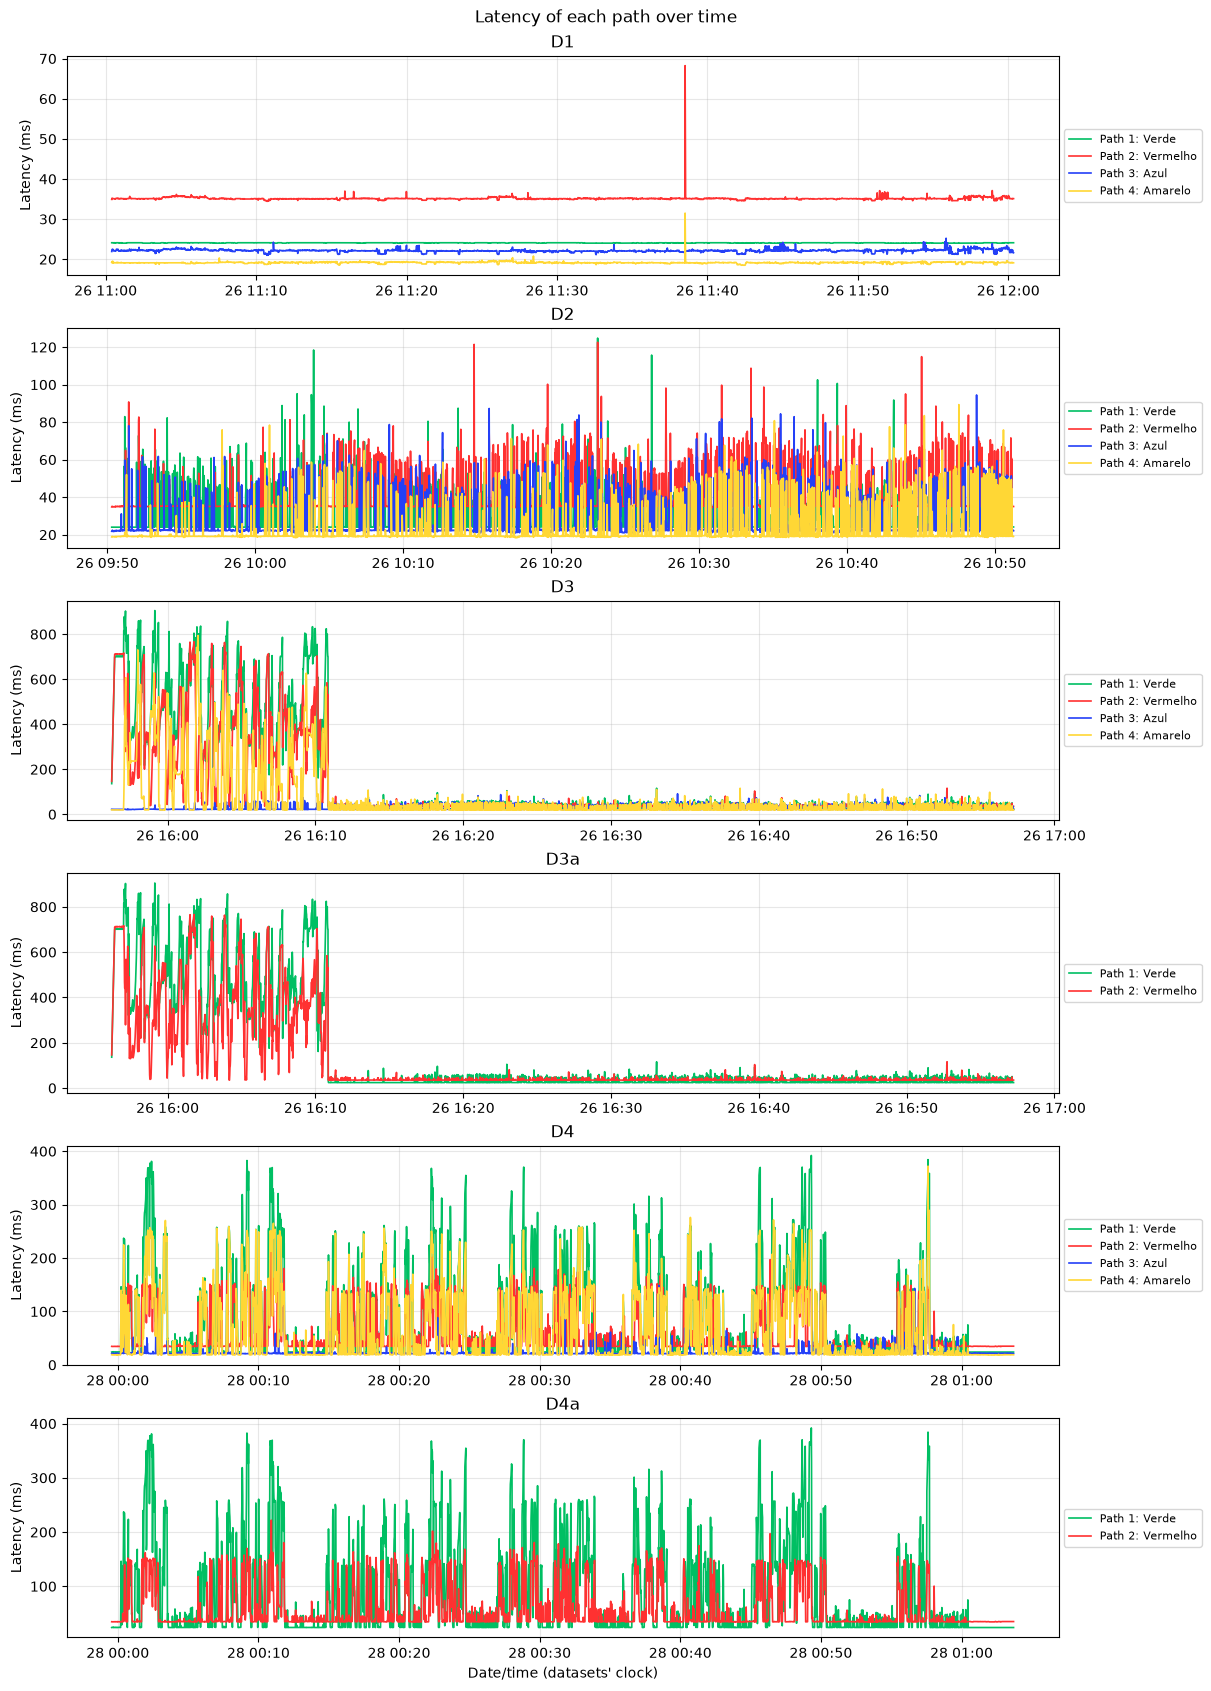

In [91]:
plot_route_metric_fs('latencia_ms', 'Latency (ms)', 'Latency of each path over time')

### Bandwidth of each path

Column *gargalo_Mbps__<route>* of **X**: the available bandwidth at the bottleneck link
of each path.

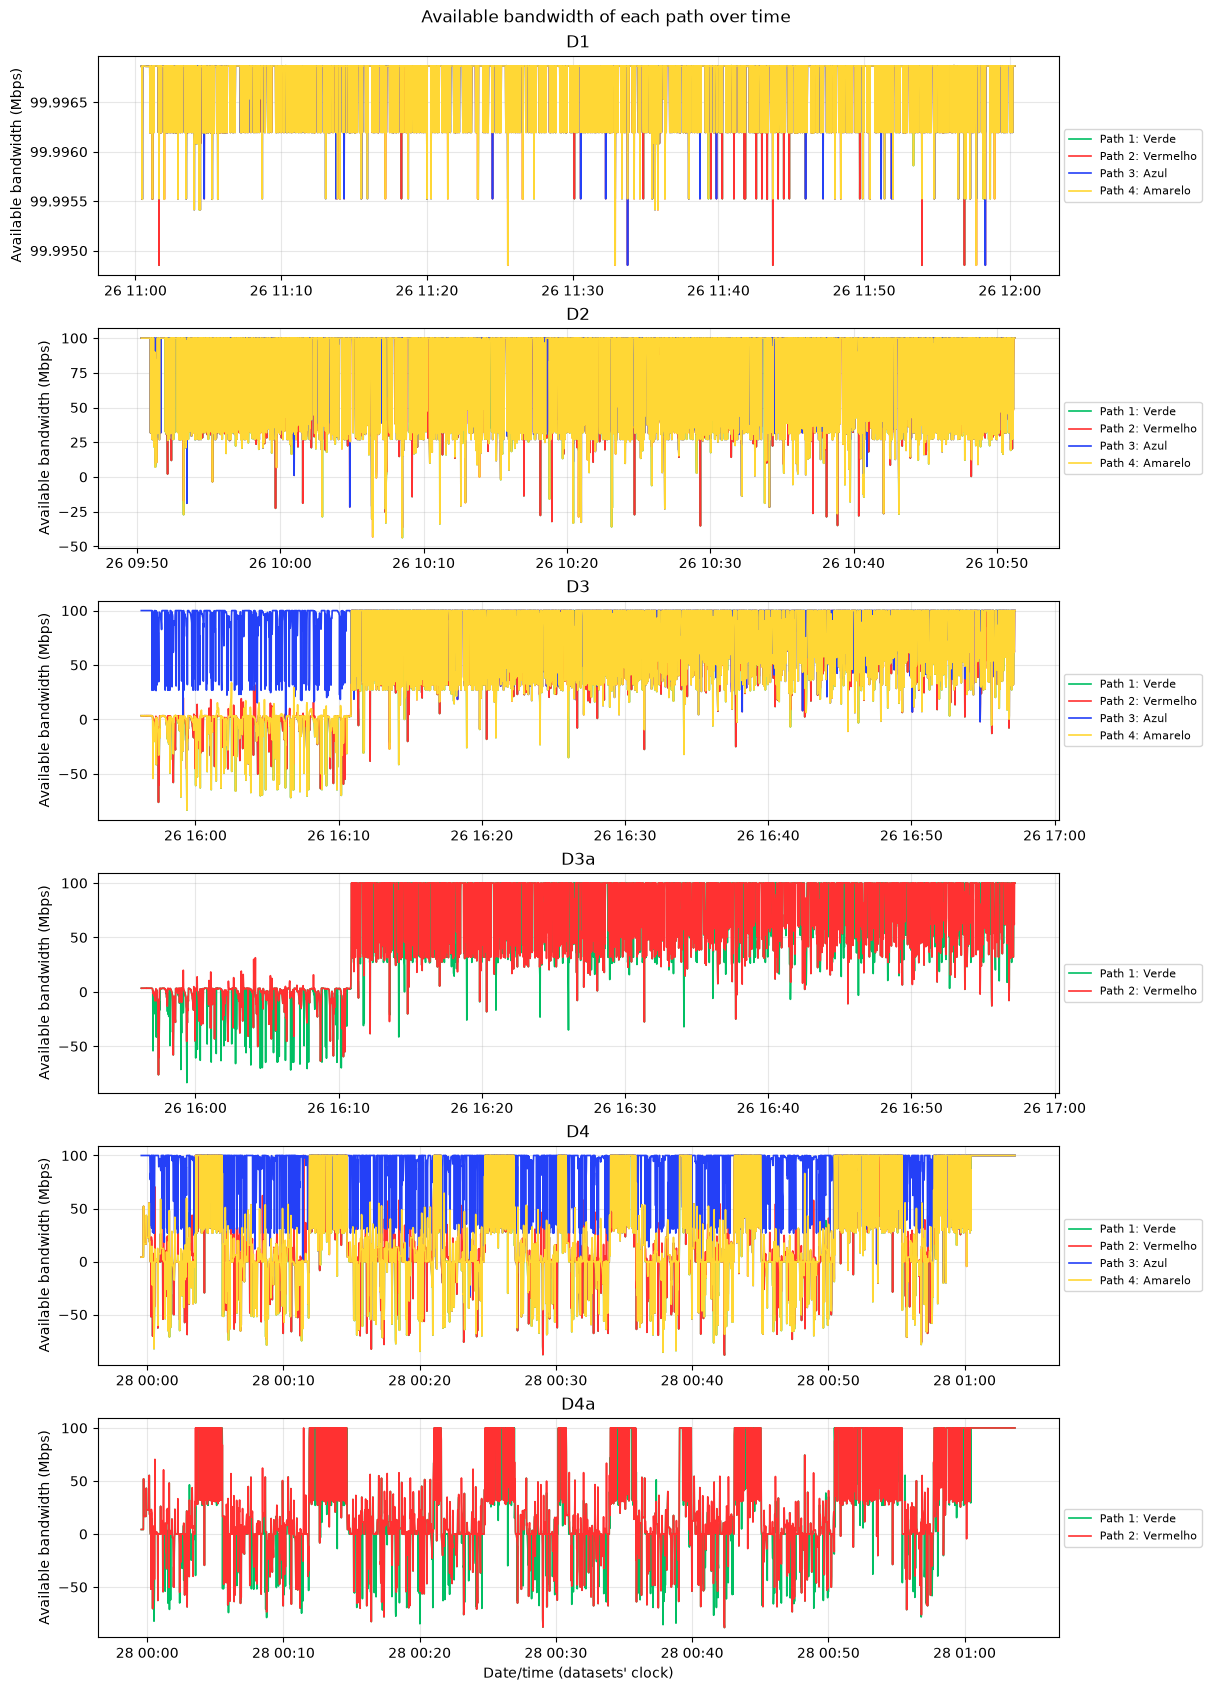

In [92]:
plot_route_metric_fs('gargalo_Mbps', 'Available bandwidth (Mbps)',
                     'Available bandwidth of each path over time')

### First rows of X

One row per instant and one column per feature and path. Only the first and last
columns are shown when there are many; the shape line gives the full size.

In [93]:
for dataset in datasets:
    wide = overview_frame_fs(dataset)
    # Named x_fs, not X, so the X of the older sections is left untouched
    x_fs = wide[pt.colunas_de_feature(wide)]
    x_fs.index = pd.to_datetime(wide['ts_epoch'], unit='s').rename('datetime')
    print(f'{dataset}: X has {x_fs.shape[0]} rows x {x_fs.shape[1]} columns '
          f'({len(path_ids_fs(wide))} paths)')
    display(x_fs.head())

D1: X has 3594 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 11:00:24,0.999968,0.999973,0.999973,0.999968,99.996864,99.996864,99.996864,99.996864,99.997038,99.997300,...,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031
2025-11-26 11:00:25,0.999968,0.999974,0.999974,0.999968,99.997125,99.996864,99.996864,99.997021,99.997060,99.997191,...,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031
2025-11-26 11:00:26,0.999968,0.999975,0.999975,0.999968,99.997125,99.996864,99.996864,99.997021,99.997073,99.997125,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031
2025-11-26 11:00:27,0.999968,0.999975,0.999975,0.999968,99.996864,99.996864,99.996864,99.996864,99.997038,99.997082,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000037,0.000036,0.000036,0.000037
2025-11-26 11:00:28,0.999987,0.999986,0.999987,0.999987,99.995781,99.995781,99.995520,99.995834,99.996859,99.996896,...,0.000032,0.000033,0.000033,0.000032,0.000032,0.000033,0.000034,0.000034,0.000034,0.000034


D2: X has 3656 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 09:50:18,0.999967,0.999975,0.999975,0.999967,99.997125,99.996864,99.996864,99.997021,99.997125,99.997163,...,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031,0.000031,0.000028,0.000028,0.000031
2025-11-26 09:50:19,0.999968,0.999975,0.999975,0.999968,99.996864,99.996864,99.996864,99.996864,99.997060,99.997088,...,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031,0.000031,0.000029,0.000029,0.000031
2025-11-26 09:50:20,0.999968,0.999975,0.999976,0.999968,99.996864,99.997125,99.996864,99.997021,99.997021,99.997095,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031
2025-11-26 09:50:21,0.999968,0.999976,0.999976,0.999968,99.996867,99.996867,99.996867,99.996867,99.996995,99.997057,...,0.000030,0.000031,0.000031,0.000030,0.000030,0.000031,0.000037,0.000036,0.000036,0.000037
2025-11-26 09:50:22,0.999987,0.999979,0.999987,0.999979,99.995524,99.995263,99.995524,99.995368,99.996785,99.996801,...,0.000032,0.000034,0.000033,0.000033,0.000032,0.000034,0.000034,0.000036,0.000034,0.000036


D3: X has 3659 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-26 15:56:13,0.090945,0.041178,0.999974,0.043706,3.366960,67.779115,99.996864,61.349571,35.546062,78.506692,...,0.000028,0.644708,0.644745,0.644745,0.000028,0.644708,0.644745,0.644745,0.000028,0.644708
2025-11-26 15:56:14,0.117644,0.042638,0.999975,0.045693,3.277435,67.754539,99.996864,61.310602,27.478905,75.818653,...,0.000029,0.725329,0.725384,0.725384,0.000029,0.725329,0.725384,0.725384,0.000029,0.725329
2025-11-26 15:56:15,0.142309,0.043562,0.999976,0.046658,3.287963,67.777355,99.996864,61.303229,22.640717,74.210394,...,0.000030,0.773819,0.773864,0.773631,0.000030,0.773819,0.773864,0.773631,0.000030,0.773819
2025-11-26 15:56:16,0.165840,0.044201,0.999976,0.047542,3.365320,67.770746,99.996867,61.353611,19.428151,73.137119,...,0.000030,0.805946,0.806022,0.805828,0.000030,0.805946,0.967227,0.966994,0.000036,0.967135
2025-11-26 15:56:17,0.188031,0.045179,0.999987,0.048195,3.378408,67.807851,99.995524,61.337859,17.135330,72.375795,...,0.000032,0.828914,0.828979,0.828663,0.000032,0.828914,0.967036,0.966594,0.000034,0.966967


... (2 outputs left out)

D4: X has 3847 rows x 100 columns (4 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_delta_micro_longa__h13_h63,banda_delta_micro_longa__h14_h64,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_Mbps__h13_h63,banda_media_Mbps__h14_h64,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,...,utilizacao_media_curta_15s__h13_h63,utilizacao_media_curta_15s__h14_h64,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_longa_30s__h13_h63,utilizacao_media_longa_30s__h14_h64,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62,utilizacao_media_micro_5s__h13_h63,utilizacao_media_micro_5s__h14_h64
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-27 23:59:34,0.116029,0.053435,0.999922,0.056341,4.253627,68.084851,99.990598,61.691861,36.153483,78.714181,...,0.000086,0.638676,0.638676,0.638402,0.000086,0.638676,0.638676,0.638402,0.000086,0.638676
2025-11-27 23:59:35,0.148841,0.055302,0.999924,0.058861,4.273360,68.084854,99.990601,61.703705,28.183452,76.056849,...,0.000088,0.718324,0.718324,0.718118,0.000088,0.718324,0.718324,0.718118,0.000088,0.718324
2025-11-27 23:59:36,0.179238,0.056486,0.999926,0.060484,4.285264,68.088822,99.990601,61.708466,23.403814,74.463244,...,0.000089,0.766089,0.766089,0.765924,0.000089,0.766089,0.766089,0.765924,0.000089,0.766089
2025-11-27 23:59:37,0.207501,0.057303,0.999926,0.061617,4.277328,68.088822,99.990601,61.703705,20.216067,73.400840,...,0.000090,0.797951,0.797951,0.797794,0.000090,0.797951,0.957542,0.957353,0.000108,0.957542
2025-11-27 23:59:38,0.234251,0.058828,0.999961,0.062562,4.277269,68.084796,99.987096,61.702371,17.939096,72.641405,...,0.000096,0.820717,0.820717,0.820565,0.000096,0.820717,0.957393,0.957203,0.000102,0.957393


D4a: X has 3847 rows x 50 columns (2 paths)


,banda_delta_micro_longa__h11_h61,banda_delta_micro_longa__h12_h62,banda_media_Mbps__h11_h61,banda_media_Mbps__h12_h62,banda_media_curta_15s__h11_h61,banda_media_curta_15s__h12_h62,banda_media_longa_30s__h11_h61,banda_media_longa_30s__h12_h62,banda_media_micro_5s__h11_h61,banda_media_micro_5s__h12_h62,...,latencia_p95_micro_5s__h11_h61,latencia_p95_micro_5s__h12_h62,util_max_pct__h11_h61,util_max_pct__h12_h62,utilizacao_media_curta_15s__h11_h61,utilizacao_media_curta_15s__h12_h62,utilizacao_media_longa_30s__h11_h61,utilizacao_media_longa_30s__h12_h62,utilizacao_media_micro_5s__h11_h61,utilizacao_media_micro_5s__h12_h62
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-27 23:59:34,0.116029,0.053435,4.253627,68.084851,36.153483,78.714181,36.153483,78.714181,36.153483,78.714181,...,24.900023,36.277020,95.797744,95.726640,0.638676,0.638402,0.638676,0.638402,0.638676,0.638402
2025-11-27 23:59:35,0.148841,0.055302,4.273360,68.084854,28.183452,76.056849,28.183452,76.056849,28.183452,76.056849,...,24.886984,36.188755,95.726640,95.726640,0.718324,0.718118,0.718324,0.718118,0.718324,0.718118
2025-11-27 23:59:36,0.179238,0.056486,4.285264,68.088822,23.403814,74.463244,23.403814,74.463244,23.403814,74.463244,...,24.859412,36.113996,95.714736,95.714736,0.766089,0.765924,0.766089,0.765924,0.766089,0.765924
2025-11-27 23:59:37,0.207501,0.057303,4.277328,68.088822,20.216067,73.400840,20.216067,73.400840,4.259280,68.081008,...,24.831840,36.030234,95.726640,95.714736,0.797951,0.797794,0.797951,0.797794,0.957542,0.957353
2025-11-27 23:59:38,0.234251,0.058828,4.277269,68.084796,17.939096,72.641405,17.939096,72.641405,4.273370,68.086429,...,24.373194,34.672027,95.730672,95.718760,0.820717,0.820565,0.820717,0.820565,0.957393,0.957203


### First rows of y

`melhor_rota` is the pathId the model must predict at each instant (before any horizon
shift; scenario 1 moves it H seconds ahead).

In [94]:
for target in targets:
    first_y = {}
    for dataset in datasets:
        wide = overview_frame_fs(dataset, target)
        first_y[dataset] = pd.DataFrame({
            'datetime': pd.to_datetime(wide['ts_epoch'], unit='s'),
            'y': wide['melhor_rota'],
        }).head(10)
    print(f'target: {target}')
    display(pd.concat(first_y, axis=1))

target: lowest_latency


D1                     D2                     D3     \
             datetime  y            datetime  y            datetime  y   
0 2025-11-26 11:00:24  4 2025-11-26 09:50:18  4 2025-11-26 15:56:13  4   
1 2025-11-26 11:00:25  4 2025-11-26 09:50:19  4 2025-11-26 15:56:14  4   
2 2025-11-26 11:00:26  4 2025-11-26 09:50:20  4 2025-11-26 15:56:15  4   
3 2025-11-26 11:00:27  4 2025-11-26 09:50:21  4 2025-11-26 15:56:16  4   
4 2025-11-26 11:00:28  4 2025-11-26 09:50:22  4 2025-11-26 15:56:17  4   
5 2025-11-26 11:00:29  4 2025-11-26 09:50:23  4 2025-11-26 15:56:18  4   
6 2025-11-26 11:00:30  4 2025-11-26 09:50:24  4 2025-11-26 15:56:19  4   
7 2025-11-26 11:00:31  4 2025-11-26 09:50:25  4 2025-11-26 15:56:20  4   
8 2025-11-26 11:00:32  4 2025-11-26 09:50:26  4 2025-11-26 15:56:21  4   
9 2025-11-26 11:00:33  4 2025-11-26 09:50:27  4 2025-11-26 15:56:22  4   

                  D3a                     D4                    D4a     
             datetime  y            datetime  y            datetime  y  
0 2025-11-26 15:56:13  1 2025-11-27 23:59:34  4 2025-11-27 23:59:34  1  
1 2025-11-26 15:56:14  1 2025-11-27 23:59:35  4 2025-11-27 23:59:35  1  
2 2025-11-26 15:56:15  1 2025-11-27 23:59:36  4 2025-11-27 23:59:36  1  
3 2025-11-26 15:56:16  1 2025-11-27 23:59:37  4 2025-11-27 23:59:37  1  
4 2025-11-26 15:56:17  1 2025-11-27 23:59:38  4 2025-11-27 23:59:38  1  
5 2025-11-26 15:56:18  1 2025-11-27 23:59:39  4 2025-11-27 23:59:39  1  
6 2025-11-26 15:56:19  1 2025-11-27 23:59:40  4 2025-11-27 23:59:40  1  
7 2025-11-26 15:56:20  1 2025-11-27 23:59:41  4 2025-11-27 23:59:41  1  
8 2025-11-26 15:56:21  1 2025-11-27 23:59:42  4 2025-11-27 23:59:42  1  
9 2025-11-26 15:56:22  1 2025-11-27 23:59:43  4 2025-11-27 23:59:43  1

### PathIds and their distribution

Which paths each dataset has, and how often each one is the best path over the whole
series. The split into training and test blocks comes in the next section.

target: lowest_latency


,pathIds,pathIds in y,instants,Path 1: Verde,Path 2: Vermelho,Path 3: Azul,Path 4: Amarelo
dataset,,,,,,,
D1,"[1, 2, 3, 4]","[3, 4]",3594,0 (0.0%),0 (0.0%),2 (0.1%),3592 (99.9%)
D2,"[1, 2, 3, 4]","[1, 2, 3, 4]",3656,196 (5.4%),13 (0.4%),400 (10.9%),3047 (83.3%)
D3,"[1, 2, 3, 4]","[1, 2, 3, 4]",3659,332 (9.1%),48 (1.3%),1373 (37.5%),1906 (52.1%)
D3a,"[1, 2]","[1, 2]",3659,2532 (69.2%),1127 (30.8%),-,-
D4,"[1, 2, 3, 4]","[1, 2, 3, 4]",3847,37 (1.0%),18 (0.5%),1848 (48.0%),1944 (50.5%)
D4a,"[1, 2]","[1, 2]",3847,2016 (52.4%),1831 (47.6%),-,-


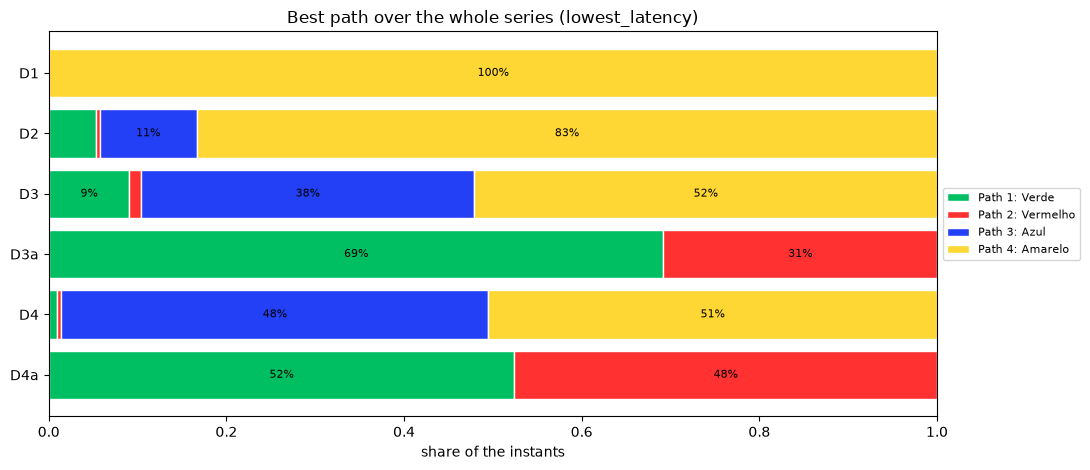

In [95]:
for target in targets:
    rows, shares = [], {}
    for dataset in datasets:
        wide = overview_frame_fs(dataset, target)
        path_ids = path_ids_fs(wide)
        counts = wide['melhor_rota'].value_counts().reindex(path_ids, fill_value=0)
        shares[dataset] = counts / counts.sum()
        row = {'dataset': dataset, 'pathIds': path_ids,
               'pathIds in y': sorted(int(p) for p in wide['melhor_rota'].unique()),
               'instants': int(counts.sum())}
        for path_id in path_ids:
            row[path_label_fs(path_id)] = f'{counts[path_id]} ({shares[dataset][path_id]:.1%})'
        rows.append(row)

    print(f'target: {target}')
    display(pd.DataFrame(rows).set_index('dataset').fillna('-'))

    # One stacked bar per dataset, each path in its colour
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(datasets) + 1.5))
    for position, (dataset, share) in enumerate(shares.items()):
        left = 0.0
        for path_id, value in share.items():
            ax.barh(position, value, left=left, color=rotas[path_id]['cor'],
                    edgecolor='white', label=path_label_fs(path_id))
            if value >= 0.06:
                ax.text(left + value / 2, position, f'{value:.0%}',
                        ha='center', va='center', fontsize=8)
            left += value
    ax.set_yticks(range(len(shares)), list(shares))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('share of the instants')
    ax.set_title(f'Best path over the whole series ({target})')
    handles, names = ax.get_legend_handles_labels()
    unique = dict(zip(names, handles))
    ax.legend(unique.values(), unique.keys(), loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=8)
    plt.tight_layout()
    plt.show()

## Joint analysis of the datasets

This section presents what each dataset gives the models to learn.

The first table shows the target at the reference horizon, over the whole series and over each
chronological block. It uses the same protocol as the evaluation, on the rows of the first feature set. A dataset where one route is best in almost every instant has little to predict. When the dominant route changes between train and test, the majority-class baseline measures the
regime shift rather than the imbalance.

The second table shows how much the features of each set actually vary. A column
whose coefficient of variation is below *VARIATION_THRESHOLD* is constant up to
numerical noise, and *StandardScaler* would promote that noise to unit variance.
This happens to the bandwidth of the idle scenario (D1). The table only flags those
columns; it never drops one.

The graph shows the label distribution on each block (train vs test).

In [63]:
def blocks_fs(wide, horizon_s, fraction=TRAIN_FRACTION):
    """Shifted frame and chronological masks, with the drop messages silenced."""
    with contextlib.redirect_stdout(io.StringIO()):
        frame, train, test = pt.preparar_treino_teste(wide, horizon_s, fracao_treino=fraction)
    return frame, train.to_numpy(), test.to_numpy()


def class_summary_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    row = {'dataset': dataset}
    for name, block in {'full': y, 'train': y[train], 'test': y[test]}.items():
        shares = block.value_counts(normalize=True)
        row[f'{name} n'] = len(block)
        row[f'{name} classes'] = block.nunique()
        row[f'{name} dominant route'] = int(shares.idxmax())
        row[f'{name} dominant %'] = round(100 * shares.max(), 2)
    row['dominant route changes'] = row['train dominant route'] != row['test dominant route']
    return row


def route_shares_fs(target, dataset, horizon_s=H_REF, feature_set=feature_sets[0]):
    frame, train, test = blocks_fs(WIDE_FS[target][(dataset, feature_set)], horizon_s)
    y = frame['melhor_rota'].astype(int)
    return {name: block.value_counts(normalize=True)
            for name, block in {'train': y[train], 'test': y[test]}.items()}


def variation_fs(wide):
    values = wide[pt.colunas_de_feature(wide)]
    return (values.std() / values.mean().abs()).replace([np.inf, -np.inf], np.nan)


class_summary_table_fs, variation_table_fs = {}, {}
for target in targets:
    class_summary_table_fs[target] = pd.DataFrame(
        [class_summary_fs(target, d) for d in datasets]).set_index('dataset')
    class_summary_table_fs[target].to_csv(
        RESULTS_DIR[target] / f'class_distribution_H{H_REF}.csv')

    variation_rows = []
    for (dataset, feature_set), wide in WIDE_FS[target].items():
        cv = variation_fs(wide)
        flagged = cv.index[(cv < VARIATION_THRESHOLD) | cv.isna()]
        variation_rows.append({
            'dataset': dataset, 'feature set': feature_set,
            'columns of X': len(cv), 'constant up to noise': len(flagged),
            'cv min': cv.min(), 'cv median': cv.median(),
            'flagged features': sorted({c.split('__')[0] for c in flagged}),
        })
    variation_table_fs[target] = pd.DataFrame(variation_rows).set_index(['dataset', 'feature set'])
    variation_table_fs[target].to_csv(RESULTS_DIR[target] / 'feature_variation.csv')

    print(f'=== target: {target} ===')
    print(f'Target at H={H_REF}s (rows of {feature_sets[0]!r}):')
    display(class_summary_table_fs[target])
    print('Variation of the features:')
    display(variation_table_fs[target])

=== target: lowest_latency ===
Target at H=30s (rows of 'store: bandwidth features'):


,full n,full classes,full dominant route,full dominant %,train n,train classes,train dominant route,train dominant %,test n,test classes,test dominant route,test dominant %,dominant route changes
dataset,,,,,,,,,,,,,
D1,3561,2,4,99.94,2849,2,4,99.93,682,1,4,100.00,False
D2,3624,4,4,83.22,2900,4,4,86.24,695,4,4,71.51,False
D3,3627,4,4,51.72,2902,4,4,49.31,695,4,4,61.58,False
D3a,3627,2,1,68.96,2902,2,1,66.99,695,2,1,77.84,False
D4,3816,4,4,50.13,3053,4,3,53.98,733,4,4,71.49,True
D4a,3816,2,1,52.04,3053,2,2,52.93,733,2,1,72.44,True


Variation of the features:


columns of X  constant up to noise  \
dataset feature set                                                     
D1      store: bandwidth features            56                    36   
        store: latency features              44                     0   
        store: all features                 100                    36   
D2      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D3      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D3a     store: bandwidth features            28                     0   
        store: latency features              22                     0   
        store: all features                  50                     0   
D4      store: bandwidth features            56                     0   
        store: latency features              44                     0   
        store: all features                 100                     0   
D4a     store: bandwidth features            28                     0   
        store: latency features              22                     0   
        store: all features                  50                     0   

                                         cv min  cv median  \
dataset feature set                                          
D1      store: bandwidth features  2.517758e-07   0.000004   
        store: latency features    1.505561e-03   0.018117   
        store: all features        2.455600e-07   0.010617   
D2      store: bandwidth features  1.910233e-02   0.423764   
        store: latency features    6.178261e-02   0.334243   
        store: all features        1.908082e-02   0.388631   
D3      store: bandwidth features  1.957035e-02   0.781333   
        store: latency features    7.229787e-02   1.402119   
        store: all features        1.954968e-02   1.097965   
D3a     store: bandwidth features  1.495616e-01   0.879348   
        store: latency features    1.298544e+00   1.464143   
        store: all features        1.495818e-01   1.360685   
D4      store: bandwidth features  2.487263e-02   0.650515   
        store: latency features    6.746047e-02   0.736149   
        store: all features        2.486035e-02   0.711828   
D4a     store: bandwidth features  1.843142e-01   1.162296   
        store: latency features    4.216696e-01   0.728418   
        store: all features        1.843320e-01   0.772977   

                                                                                                                                                                                                                    flagged features  
dataset feature set                                                                                                                                                                                                                   
D1      store: bandwidth features  [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
        store: latency features                                                                                                                                                                                                   []  
        store: all features        [banda_delta_micro_longa, banda_media_Mbps, banda_media_curta_15s, banda_media_longa_30s, banda_media_micro_5s, gargalo_Mbps, gargalo_min_curta_15s, gargalo_min_longa_30s, gargalo_min_micro_5s]  
D2      store: bandwidth features                                                                                                                                                 

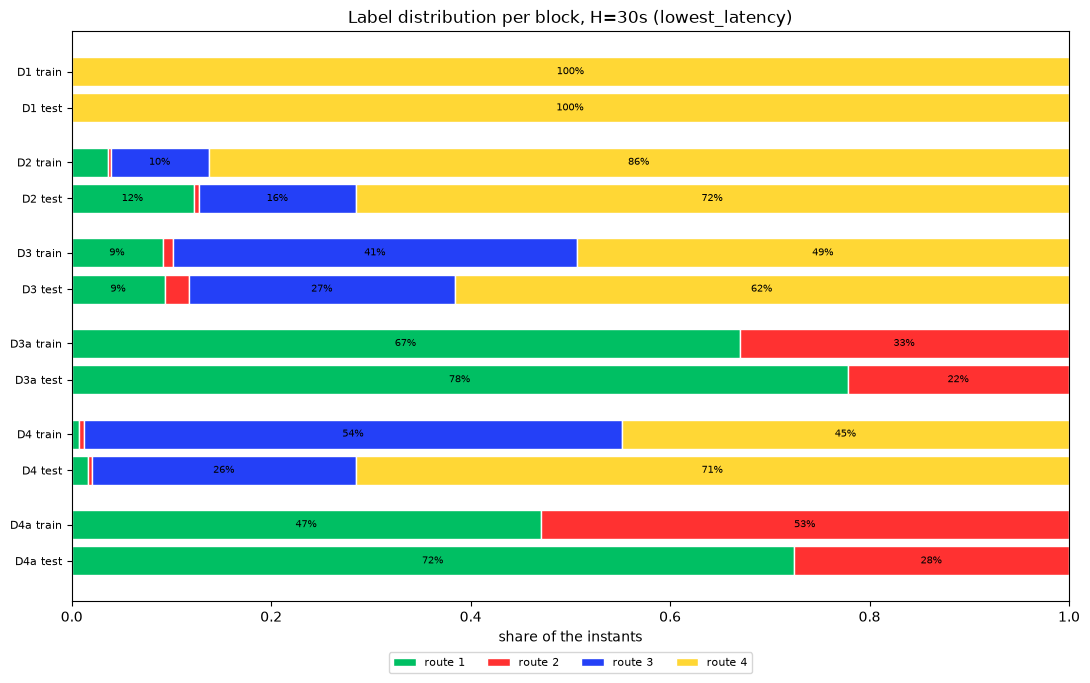

In [64]:
# Share of each route in the training and test blocks, one bar pair per dataset
for target in targets:
    plot_block_shares_fs({dataset: route_shares_fs(target, dataset) for dataset in datasets},
                         f'Label distribution per block, H={H_REF}s ({target})',
                         path=RESULTS_DIR[target] / f'class_distribution_H{H_REF}.png')

## Model evaluation, dataset by dataset

The loop below runs both scenarios for every dataset and every feature set:

**Scenario 1, horizon sweep.** For each `H` in `horizons`, `pt.preparar_treino_teste`
shifts the target to `t + H` and cuts each dataset chronologically (first 80% to
train, last 20% to test, with a gap of `H` seconds between them). Every model is
trained **once** on the whole training block and measured on the whole test block,
next to the two baselines: **persistence** (the best route in `H` seconds is the
best route now) and the **majority class** of the training block.

**Scenario 2, training window `W`.** Instead of everything up to `t`, the models
see only the last `W` seconds. For each evaluated test instant `t` they are
retrained from scratch on the pairs `(X(τ), y(τ + H))` whose label had already been
observed at `t`, and then predict `y(t + H)` from `X(t)`:

    t − H − W  <  τ  ≤  t − H        (τ ≤ t − 1 when H = 0)

A window holds at most `W` samples, fewer where the series has gaps. It may reach
back into the training block or into the gap before the test block, which is fine:
those instants are in the past of `t`. Over a few seconds the best route rarely
changes, so many windows hold a single label. Those windows predict that label
directly, for every model, since most classifiers cannot be fitted on one class.
For that reason the **window majority** (the most frequent label of the window) is
reported as a third baseline: it is what a sliding-window learner gets without
using `X`. Only one test instant every `WINDOW_STEP` seconds is evaluated,
because every one of them refits every model.

A training block with a single class makes some models fail; they get `NaN`
instead of stopping the loop.

In [ ]:
def make_pipelines_fs(names=evaluated_models, random_state=RANDOM_STATE, n_jobs=-1,
                      n_samples=None):
    """The 7 classifiers of the predictive section, each preceded by a StandardScaler.

    n_samples: size of the training set when it is known to be small (scenario 2);
    KNN cannot ask for more neighbours than there are samples.
    """
    neighbours = 5 if n_samples is None else max(1, min(5, n_samples))
    catalogue = {
        'LogisticRegression': lambda: LogisticRegression(max_iter=1000),
        'KNeighbors': lambda: KNeighborsClassifier(n_neighbors=neighbours),
        'SVC': lambda: svm.SVC(random_state=random_state),
        'DecisionTree': lambda: tree.DecisionTreeClassifier(random_state=random_state),
        'ExtraTrees': lambda: ExtraTreesClassifier(random_state=random_state, n_jobs=n_jobs),
        'RandomForest': lambda: RandomForestClassifier(random_state=random_state, n_jobs=n_jobs),
        'GaussianNB': lambda: GaussianNB(var_smoothing=VAR_SMOOTHING),
    }
    return {name: Pipeline([('scaler', StandardScaler()), ('classifier', catalogue[name]())])
            for name in names}


def evaluate_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1: train once on the training block, measure on the test block."""
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]

    rows = []
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            y_pred = model.fit(X_train, y_train).predict(X_test)
            accuracy = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            accuracy = f1 = np.nan
        rows.append({'model': name, 'accuracy': accuracy, 'f1_macro': f1})

    majority_class = int(pd.Series(y_train).value_counts().idxmax())
    return {
        'results': pd.DataFrame(rows),
        'persistence': float((current[test] == y_test).mean()),
        'majority': float((y_test == majority_class).mean()),
        'n_train': len(y_train),
        'n_test': len(y_test),
    }


def evaluate_window_instant_fs(X_window, y_window, x_now, evaluated_models=evaluated_models):
    """Predictions of every model retrained on one window, plus the window majority."""
    labels, counts = np.unique(y_window, return_counts=True)
    majority = int(labels[counts.argmax()])  # a tie goes to the lowest route number
    out = {'window_majority': majority, 'single_class': len(labels) == 1, 'fallback': 0}

    for name, model in make_pipelines_fs(evaluated_models, n_jobs=1, n_samples=len(y_window)).items():
        if len(labels) == 1:
            out[name] = majority
            continue
        try:
            out[name] = int(model.fit(X_window, y_window).predict(x_now[None, :])[0])
        except ValueError:
            # e.g. a class with too few samples for the model; counted, not hidden
            out[name] = majority
            out['fallback'] += 1
    return out


def run_training_window_fs(wide, horizon_s, window_sizes=windows,
                           step_s=WINDOW_STEP, evaluated_models=evaluated_models,
                           n_jobs=N_JOBS):
    """Scenario 2: one prediction per evaluated test instant, model and window size."""
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, _, test = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    # Last instant whose label is known at t: t - H, or t - 1 when H = 0
    last_known = max(horizon_s, 1)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        evaluated = positions[test[positions]][::step_s]

        for W in window_sizes:
            cases = []  # (evaluated instant, positions of its window)
            for i in evaluated:
                upper = ts[i] - last_known
                start = np.searchsorted(ts_d, upper - W, side='right')
                stop = np.searchsorted(ts_d, upper, side='right')
                if stop > start:
                    cases.append((i, positions[start:stop]))

            outputs = Parallel(n_jobs=n_jobs)(
                delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
                for i, w in cases
            )
            for (i, w), out in zip(cases, outputs):
                rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'window_s': W,
                             'n_train': len(w), 'y_true': int(y[i]),
                             'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print('evaluation helpers defined')

evaluation helpers defined


In [ ]:
sweep_fs, sweep_baselines_fs, window_predictions_fs = {}, {}, {}

for target in targets:
    sweep_rows, baseline_rows, window_parts = [], [], []
    for dataset in datasets:
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            started = time.time()

            # Scenario 1: horizon sweep, whole training block
            for H in horizons:
                result = evaluate_full_block_fs(wide, H)
                sweep_rows.append(result['results'].assign(
                    dataset=dataset, feature_set=feature_set, horizon_s=H))
                baseline_rows.append({
                    'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H,
                    'persistence': result['persistence'], 'majority': result['majority'],
                    'n_train': result['n_train'], 'n_test': result['n_test'],
                })

            # Scenario 2: sliding training window
            for H in horizons:
                part = run_training_window_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                window_parts.append(part)

            print(f'{target:24s} | {dataset:4s} | {feature_set:26s} | '
                  f'{len(pt.colunas_de_feature(wide)):3d} columns | {len(wide):5d} instants '
                  f'| {time.time() - started:6.1f} s')

    sweep_fs[target] = pd.concat(sweep_rows, ignore_index=True)[
        ['dataset', 'feature_set', 'horizon_s', 'model', 'accuracy', 'f1_macro']]
    sweep_baselines_fs[target] = pd.DataFrame(baseline_rows)
    window_predictions_fs[target] = pd.concat(window_parts, ignore_index=True)

    results_dir = RESULTS_DIR[target]
    sweep_fs[target].to_csv(results_dir / 'sweep_accuracy.csv', index=False)
    sweep_baselines_fs[target].to_csv(results_dir / 'sweep_baselines.csv', index=False)
    window_predictions_fs[target].to_csv(results_dir / 'window_predictions.csv', index=False)
    print(f'saved to {results_dir}')

D1   | store: bandwidth features  |  52 columns |  3595 instants |   11.2 s
D1   | store: all features        | 100 columns |  3594 instants |    8.2 s
D2   | store: bandwidth features  |  52 columns |  3657 instants |   65.1 s
D2   | store: all features        | 100 columns |  3656 instants |   80.7 s
D3   | store: bandwidth features  |  52 columns |  3660 instants |   73.1 s
D3   | store: all features        | 100 columns |  3659 instants |  114.1 s
D3a  | store: bandwidth features  |  26 columns |  3660 instants |  133.5 s
D3a  | store: all features        |  50 columns |  3659 instants |  132.1 s
D4   | store: bandwidth features  |  52 columns |  3848 instants |  123.3 s
D4   | store: all features        | 100 columns |  3847 instants |  158.4 s
D4a  | store: bandwidth features  |  26 columns |  3848 instants |  122.2 s
D4a  | store: all features        |  50 columns |  3847 instants |  120.6 s
saved to /home/beatrizam/Documents/beatriz/path-aware-datasets/resultados_am/CenarioPred

## Scenario 1: horizon sweep

The best model of each `(dataset, feature set, H)` next to the two baselines. The
success criterion is not the absolute accuracy but the **gain over persistence**: a
model that does not beat "the best route in `H` seconds is the best route now" does
not predict anything a reactive controller would not get for free. At `H = 0`
persistence is 1.0 by construction, so that column only isolates the effect of
the chronological split.

In [ ]:
_keys_fs = ['dataset', 'feature_set', 'horizon_s']
best_fs = {}
for target in targets:
    best = (sweep_fs[target].dropna(subset=['accuracy'])
            .sort_values('accuracy', ascending=False)
            .drop_duplicates(_keys_fs)
            .merge(sweep_baselines_fs[target], on=_keys_fs)
            .rename(columns={'model': 'best model'}))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best_fs[target] = best.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    best_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_best_model.csv')

    baselines = sweep_baselines_fs[target]
    print(f'=== target: {target} ===')
    print('Accuracy of the best model, by horizon (persistence and majority class below):')
    display(best_fs[target]['accuracy'].unstack('horizon_s').round(4))
    display(baselines[baselines.feature_set == feature_sets[0]]
            .set_index(['dataset', 'horizon_s'])[['persistence', 'majority']]
            .stack().unstack('horizon_s').reindex(datasets, level=0).round(4))

    print('Gain of the best model over persistence:')
    display(best_fs[target]['gain over persistence'].unstack('horizon_s').round(4))

Accuracy of the best model, by horizon (persistence and majority class below):


horizon_s                              0       1       5       15      30  \
dataset feature_set                                                         
D1      store: all features        1.0000  1.0000  1.0000  1.0000  1.0000   
        store: bandwidth features  1.0000  1.0000  1.0000  1.0000  1.0000   
D2      store: all features        0.9808  0.7380  0.7113  0.7153  0.7151   
        store: bandwidth features  0.7510  0.7133  0.7113  0.7153  0.7151   
D3      store: all features        0.9808  0.7174  0.6152  0.6199  0.6173   
        store: bandwidth features  0.7579  0.6685  0.6138  0.6157  0.6158   
D3a     store: all features        0.9918  0.8519  0.7683  0.7742  0.7784   
        store: bandwidth features  0.7962  0.7959  0.7683  0.7756  0.7784   
D4      store: all features        0.9766  0.7940  0.7493  0.7627  0.7432   
        store: bandwidth features  0.7971  0.7797  0.7392  0.7603  0.7517   
D4a     store: all features        0.9857  0.8096  0.7690  0.7680  0.7664   
        store: bandwidth features  0.8153  0.7901  0.7746  0.7670  0.7681   

horizon_s                              60  
dataset feature_set                        
D1      store: all features        1.0000  
        store: bandwidth features  1.0000  
D2      store: all features        0.7162  
        store: bandwidth features  0.7162  
D3      store: all features        0.6237  
        store: bandwidth features  0.6206  
D3a     store: all features        0.7785  
        store: bandwidth features  0.7785  
D4      store: all features        0.7011  
        store: bandwidth features  0.7145  
D4a     store: all features        0.7155  
        store: bandwidth features  0.7174

horizon_s                0       1       5       15      30      60
dataset                                                            
D1      persistence  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
        majority     1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
D2      persistence  1.0000  0.6763  0.5552  0.5498  0.5353  0.5615
        majority     0.7141  0.7133  0.7113  0.7153  0.7151  0.7162
D3      persistence  1.0000  0.6247  0.4483  0.4362  0.4417  0.5175
        majority     0.6088  0.6096  0.6138  0.6157  0.6158  0.6131
D3a     persistence  1.0000  0.6658  0.6538  0.6522  0.6043  0.6904
        majority     0.7661  0.7658  0.7683  0.7742  0.7784  0.7785
D4      persistence  1.0000  0.7601  0.6527  0.6551  0.6398  0.6686
        majority     0.2601  0.2608  0.2621  0.2597  0.2647  0.2697
D4a     persistence  1.0000  0.7927  0.7025  0.6951  0.6794  0.6815
        majority     0.2796  0.2803  0.2805  0.2770  0.2756  0.2812

Gain of the best model over persistence:


horizon_s                              0       1       5       15      30  \
dataset feature_set                                                         
D1      store: all features        0.0000  0.0000  0.0000  0.0000  0.0000   
        store: bandwidth features  0.0000  0.0000  0.0000  0.0000  0.0000   
D2      store: all features       -0.0192  0.0617  0.1561  0.1655  0.1799   
        store: bandwidth features -0.2490  0.0370  0.1561  0.1655  0.1799   
D3      store: all features       -0.0192  0.0933  0.1669  0.1837  0.1755   
        store: bandwidth features -0.2421  0.0438  0.1655  0.1795  0.1741   
D3a     store: all features       -0.0082  0.1852  0.1145  0.1220  0.1741   
        store: bandwidth features -0.2038  0.1301  0.1145  0.1234  0.1741   
D4      store: all features       -0.0234  0.0339  0.0958  0.1080  0.1025   
        store: bandwidth features -0.2029  0.0196  0.0865  0.1052  0.1119   
D4a     store: all features       -0.0143  0.0169  0.0656  0.0733  0.0861   
        store: bandwidth features -0.1847 -0.0026  0.0721  0.0719  0.0887   

horizon_s                              60  
dataset feature_set                        
D1      store: all features        0.0000  
        store: bandwidth features  0.0000  
D2      store: all features        0.1548  
        store: bandwidth features  0.1548  
D3      store: all features        0.1062  
        store: bandwidth features  0.1032  
D3a     store: all features        0.0880  
        store: bandwidth features  0.0880  
D4      store: all features        0.0316  
        store: bandwidth features  0.0459  
D4a     store: all features        0.0345  
        store: bandwidth features  0.0359

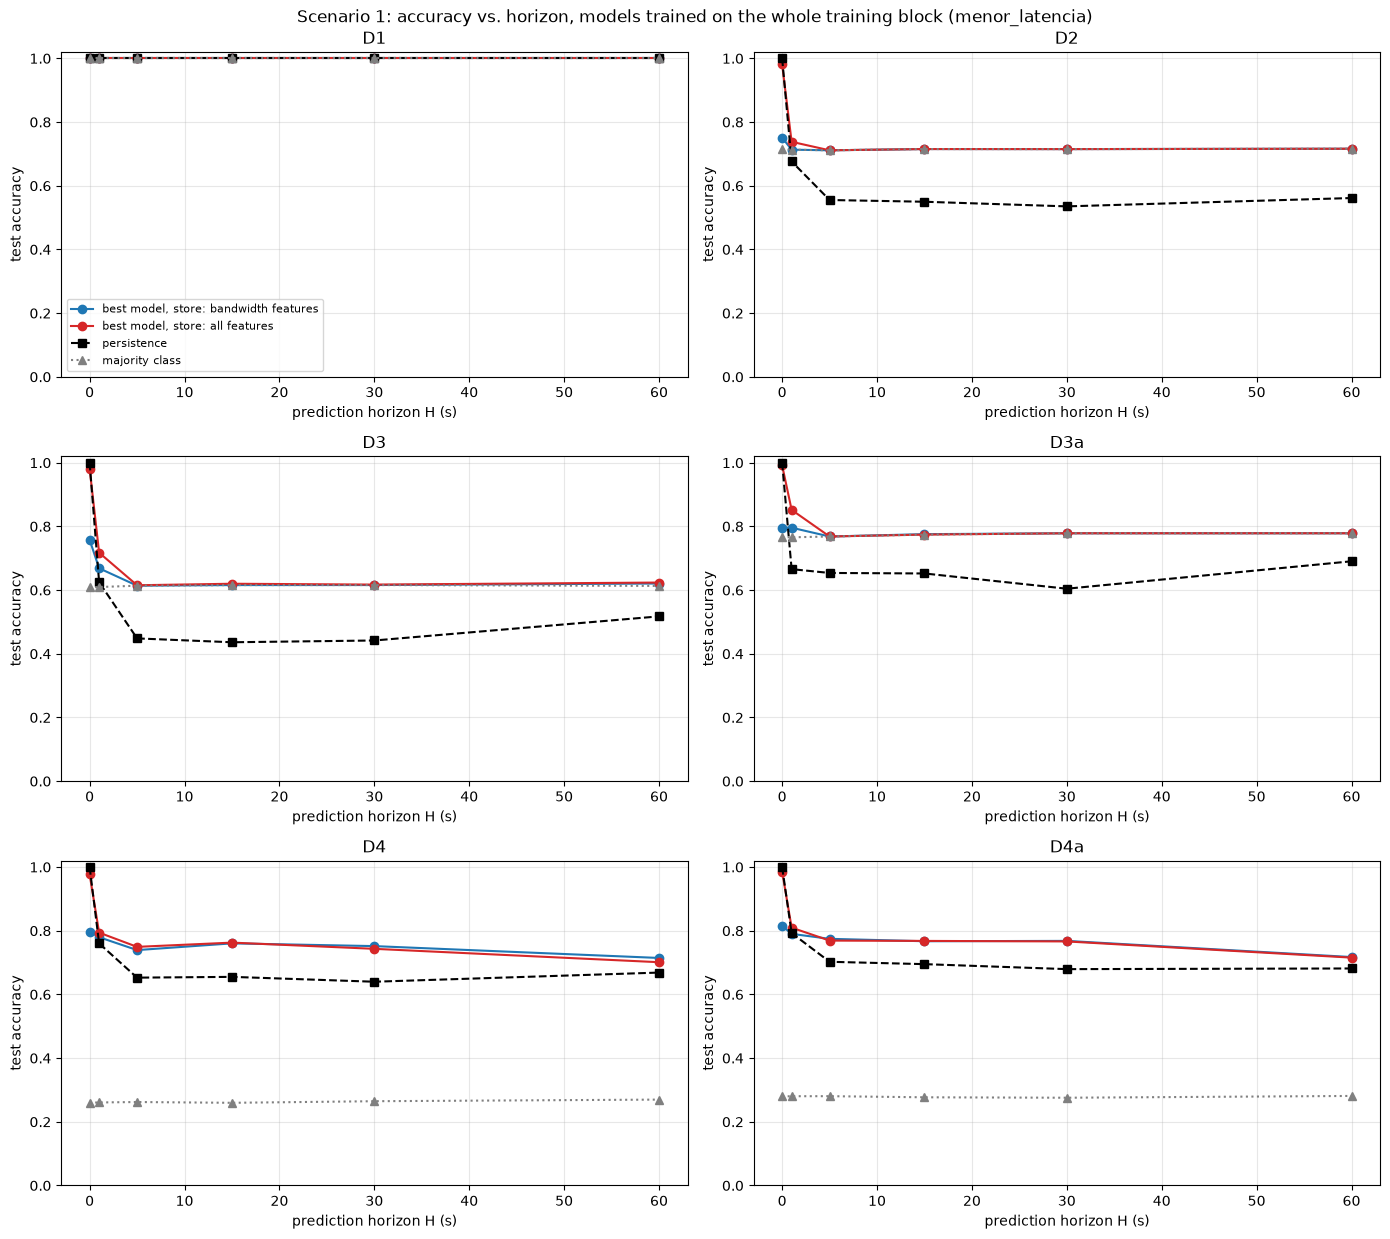

In [ ]:
for target in targets:
    plot_sweep_accuracy_fs(
        best_fs[target], sweep_baselines_fs[target], datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 1: accuracy vs. horizon, models trained on the whole training block '
        f'({target})',
        path=RESULTS_DIR[target] / 'sweep_best_model.png')

### Scenario 1: confusion matrices and metrics beyond accuracy

Accuracy hides the class imbalance: in a dataset where one route is best in 70% of
the instants, a model that always answers that route scores 0.70. The metrics below
do not reward that:

| metric | what it measures | always predicting the majority route gives |
|---|---|---|
| `balanced_accuracy` | mean recall over the routes present in the test block | 1 / number of routes |
| `precision_macro`, `recall_macro`, `f1_macro` | mean over the routes, each route weighing the same | low, since the minority routes score 0 |
| `mcc` | Matthews correlation between predicted and actual routes, from −1 to 1 | 0 |

The loop of scenario 1 only kept accuracy and F1-macro, so the cell below retrains
the same models on the same blocks, this time keeping every prediction. The two
baselines are scored as predictors too, on the same instants: **persistence**
(the route of `t`) and the **majority class** of the training block. A check at the
end confirms that the retrained models reproduce the accuracies of the loop.

When the test block holds a single route (D1), `mcc` is undefined and scikit-learn reports 0 even for a perfect model; read D1 on the other metrics.

In [ ]:
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

# Horizons retrained here; list(horizons) reproduces the whole sweep
PREDICTION_HORIZONS_FS = list(horizons)

METRICS_FS = ['accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro',
              'f1_macro', 'mcc']
BASELINES_FS = ['persistence', 'majority']


def classification_metrics_fs(y_true, y_pred):
    """Every metric of METRICS_FS for one set of predictions."""
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(y_true, y_pred),
    }


def predict_full_block_fs(wide, horizon_s, evaluated_models=evaluated_models):
    """Scenario 1 again, returning one row per test instant with every prediction.

    Same blocks and same models as evaluate_full_block_fs. A model that cannot be
    trained (single-class training block) gets NaN predictions.
    """
    frame, train, test = blocks_fs(wide, horizon_s)
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    majority_class = int(pd.Series(y[train]).value_counts().idxmax())

    out = pd.DataFrame({
        'ts_epoch': frame['ts_epoch'].to_numpy()[test],
        'y_true': y[test],
        'persistence': current[test],
        'majority': majority_class,
    })
    for name, model in make_pipelines_fs(evaluated_models).items():
        try:
            out[name] = model.fit(X[train], y[train]).predict(X[test])
        except ValueError as error:
            print(f'    {name}: not trained ({error})')
            out[name] = np.nan
    return out


sweep_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            for H in PREDICTION_HORIZONS_FS:
                part = predict_full_block_fs(WIDE_FS[target][(dataset, feature_set)], H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                part.insert(0, 'dataset', dataset)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    sweep_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    sweep_predictions_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_predictions.csv',
                                        index=False)


def metrics_table_fs(predictions, keys, predictors):
    """One row per (case, predictor) with every metric of METRICS_FS."""
    rows = []
    for case, group in predictions.groupby(keys):
        case = dict(zip(keys, case if isinstance(case, tuple) else (case,)))
        for predictor in predictors:
            valid = group[predictor].notna()
            if not valid.any():
                continue
            rows.append({**case, 'predictor': predictor, 'instants': int(valid.sum()),
                         **classification_metrics_fs(group.y_true[valid],
                                                     group[predictor][valid].astype(int))})
    return pd.DataFrame(rows)


sweep_metrics_fs = {}
for target in targets:
    metrics = metrics_table_fs(sweep_predictions_fs[target],
                               ['dataset', 'feature_set', 'horizon_s'],
                               evaluated_models + BASELINES_FS)
    sweep_metrics_fs[target] = metrics
    metrics.to_csv(RESULTS_DIR[target] / 'sweep_metrics.csv', index=False)

    # The retrained models must reproduce the accuracies of the loop
    check = metrics.merge(
        sweep_fs[target].rename(columns={'model': 'predictor', 'accuracy': 'loop_accuracy'}),
        on=['dataset', 'feature_set', 'horizon_s', 'predictor'])
    print(f'=== target: {target} ===')
    print(f'largest accuracy difference against the loop: '
          f'{(check.accuracy - check.loop_accuracy).abs().max():.2e} '
          f'over {len(check)} cases')

    print(f'Every metric at the reference horizon H={H_REF}s:')
    display(metrics[metrics.horizon_s == H_REF]
            .set_index(['dataset', 'feature_set', 'predictor'])[METRICS_FS]
            .reindex(datasets, level=0).round(3))

D1   |   16.7 s
D2   |   58.5 s
D3   |  526.6 s
D3a  |   12.5 s
D4   |   36.7 s
D4a  |   15.1 s
largest accuracy difference against the loop: 0.00e+00 over 504 cases

Every metric at the reference horizon H=30s:


accuracy  \
dataset feature_set               predictor                      
D1      store: all features       LogisticRegression     1.000   
                                  KNeighbors             1.000   
                                  SVC                    1.000   
                                  DecisionTree           1.000   
                                  ExtraTrees             1.000   
...                                                        ...   
D4a     store: bandwidth features ExtraTrees             0.730   
                                  RandomForest           0.711   
                                  GaussianNB             0.768   
                                  persistence            0.679   
                                  majority               0.276   

                                                      balanced_accuracy  \
dataset feature_set               predictor                               
D1      store: all features       LogisticRegression              1.000   
                                  KNeighbors                      1.000   
                                  SVC                             1.000   
                                  DecisionTree                    1.000   
                                  ExtraTrees                      1.000   
...                                                                 ...   
D4a     store: bandwidth features ExtraTrees                      0.605   
                                  RandomForest                    0.570   
                                  GaussianNB                      0.657   
                                  persistence                     0.608   
                                  majority                        0.500   

                                                      precision_macro  \
dataset feature_set               predictor                             
D1      store: all features       LogisticRegression            1.000   
                                  KNeighbors                    1.000   
                                  SVC                           1.000   
                                  DecisionTree                  1.000   
                                  ExtraTrees                    1.000   
...                                                               ...   
D4a     store: bandwidth features ExtraTrees                    0.645   
                                  RandomForest                  0.607   
                                  GaussianNB                    0.710   
                                  persistence                   0.604   
                                  majority                      0.138   

                                                      recall_macro  f1_macro  \
dataset feature_set               predictor                                    
D1      store: all features       LogisticRegression         1.000     1.000   
                                  KNeighbors                 1.000     1.000   
                                  SVC                        1.000     1.000   
                                  DecisionTree               1.000     1.000   
                                  ExtraTrees                 1.000     1.000   
...                                                            ...       ...   
D4a     store: bandwidth features ExtraTrees                 0.605     0.613   
                                  RandomForest               0.570     0.572   
                                  GaussianNB                 0.657     0.672   
                                  persistence                0.608     0.606   
                                  majority                   0.500     0.216   

                                                        mcc  
dataset feature_set               predictor                  
D1      store: all features       LogisticRegression  0.000  
                                  KNeighbo

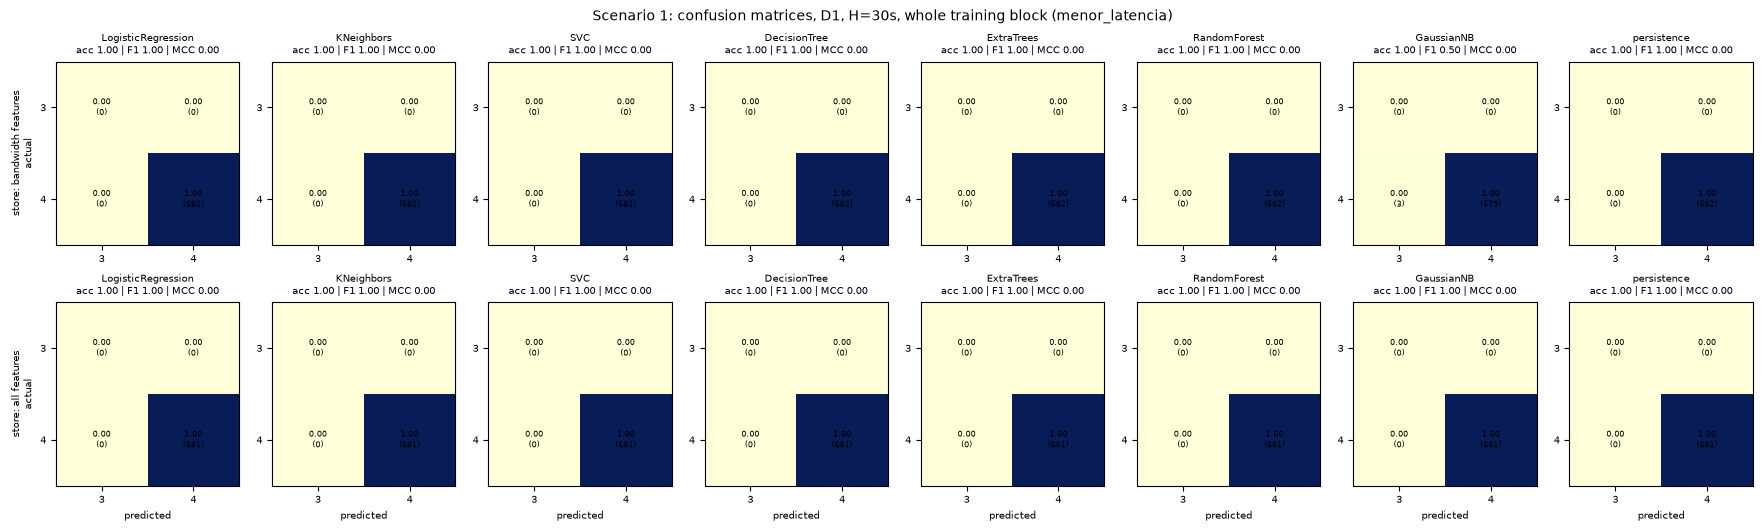

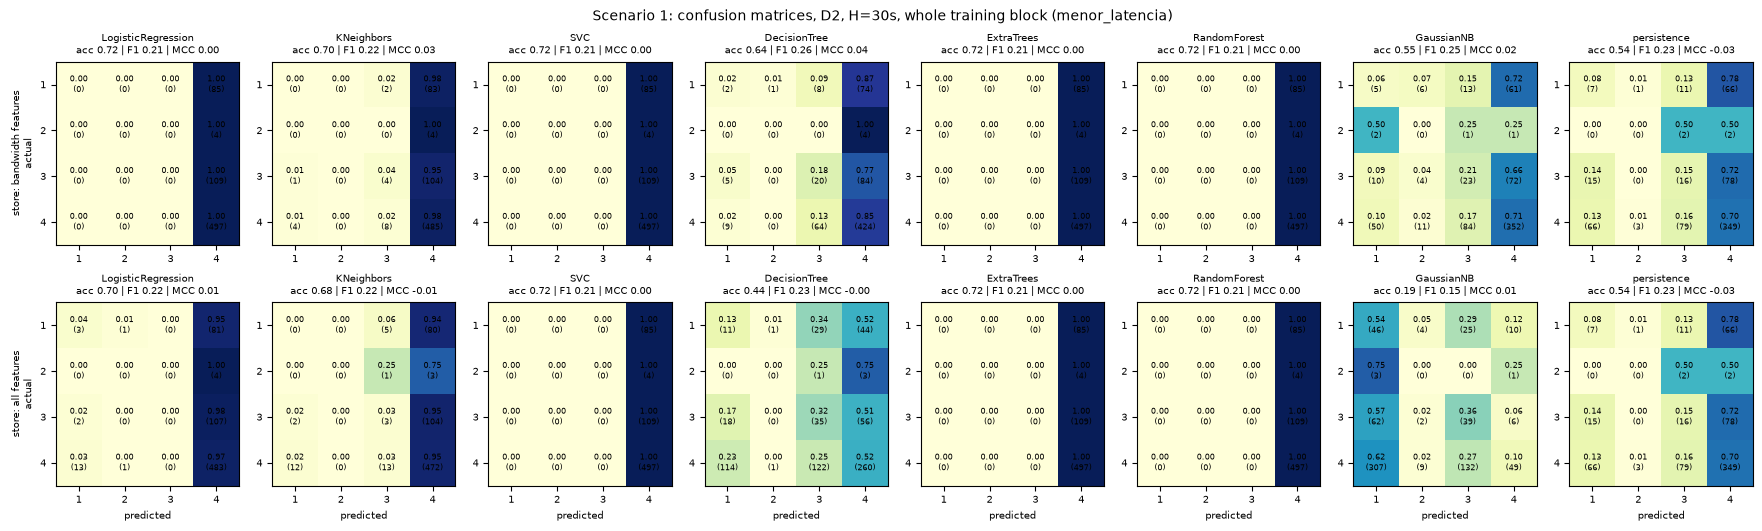

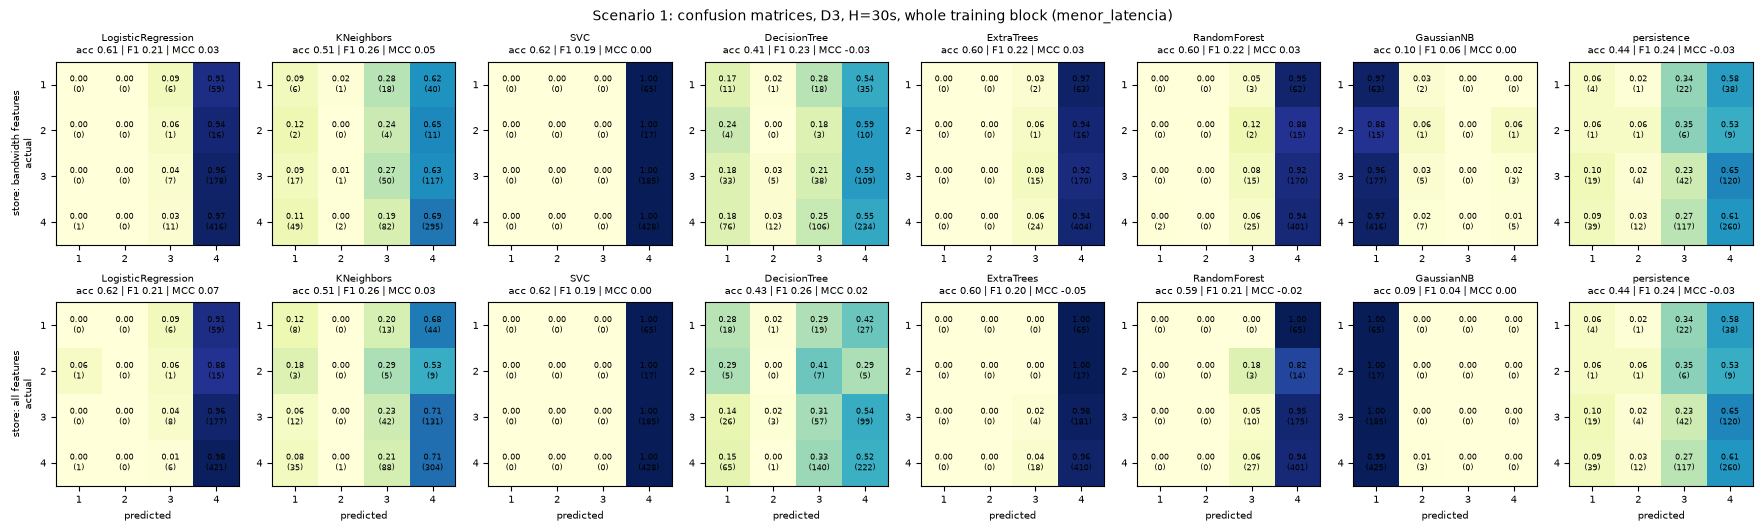

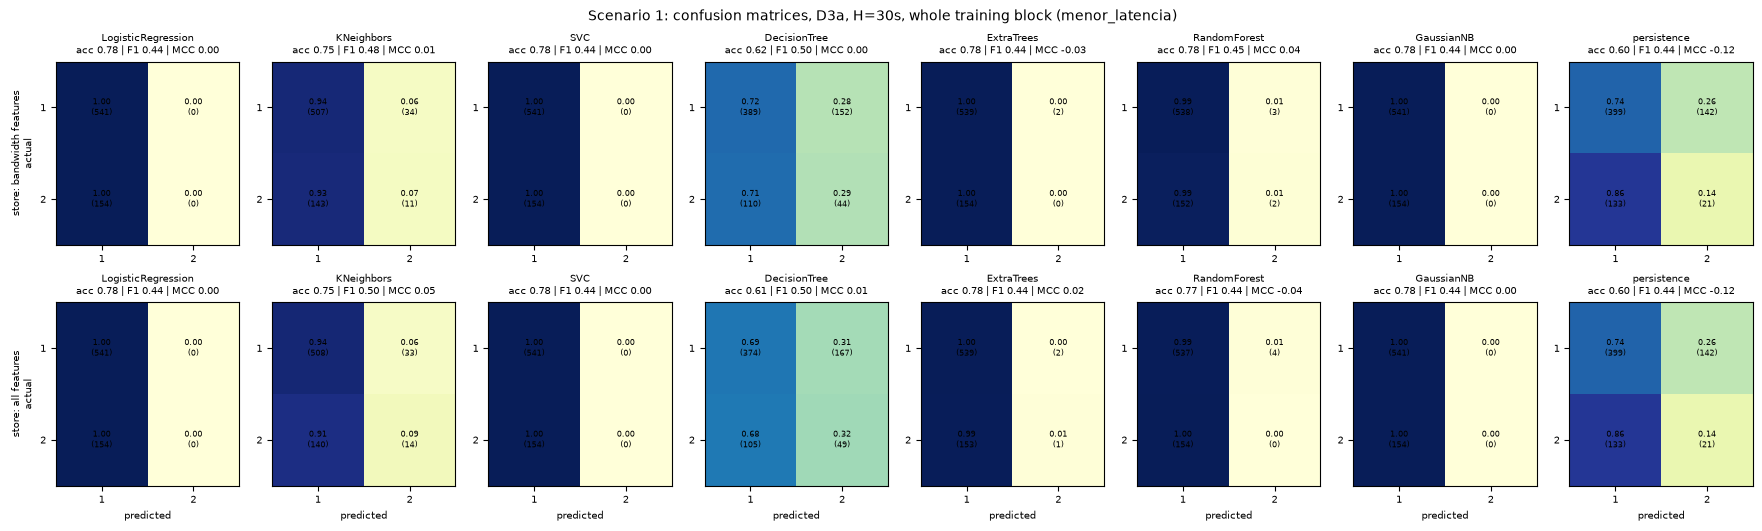

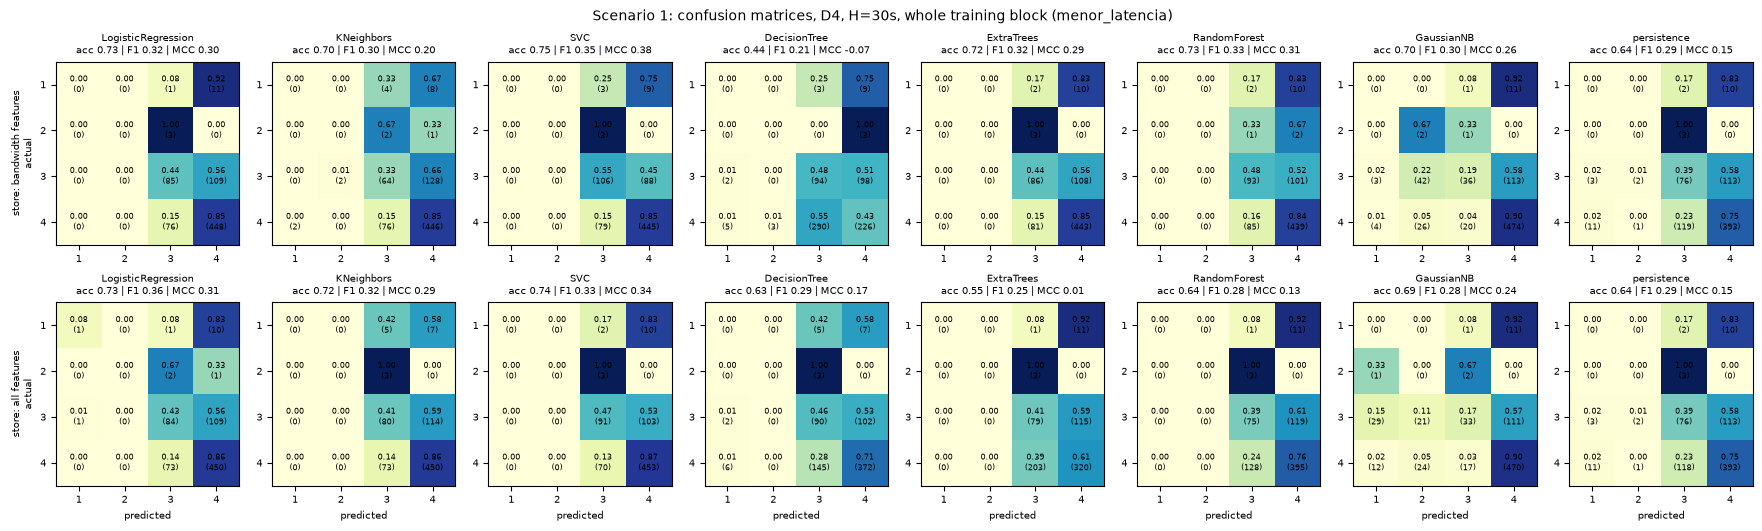

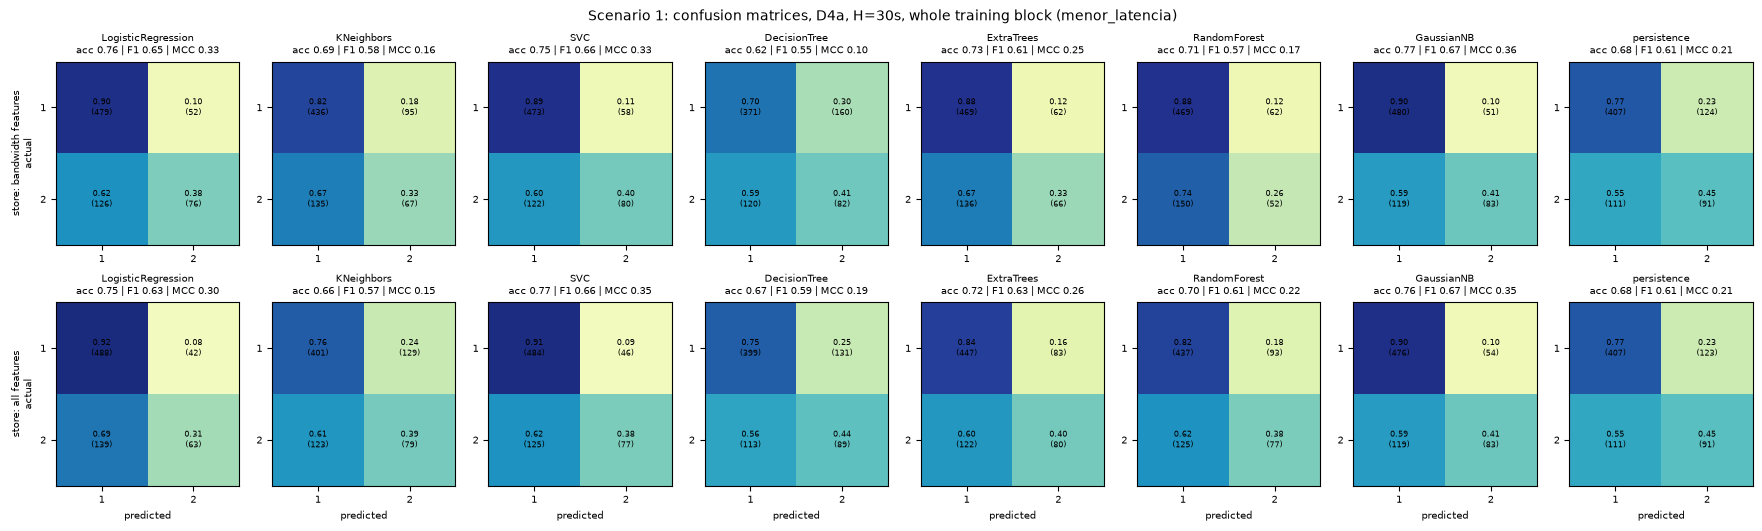

In [ ]:
# Confusion matrices of every model at one horizon: one figure per dataset, one row
#   per feature set (plot_confusion_rows_fs). Persistence is drawn next to the models.
#   CONFUSION_NORMALIZE_FS = True divides each row by its support, so the diagonal
#   becomes the recall of that route; the raw count is shown below it.
CONFUSION_H_FS = H_REF
CONFUSION_PREDICTORS_FS = evaluated_models + ['persistence']
CONFUSION_NORMALIZE_FS = True

for target in targets:
    predictions = sweep_predictions_fs[target]
    for dataset in datasets:
        plot_confusion_rows_fs(
            predictions[predictions.horizon_s == CONFUSION_H_FS], dataset,
            f'Scenario 1: confusion matrices, {dataset}, H={CONFUSION_H_FS}s, '
            f'whole training block ({target})',
            CONFUSION_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=RESULTS_DIR[target] / f'sweep_confusion_{dataset}_H{CONFUSION_H_FS}.png')

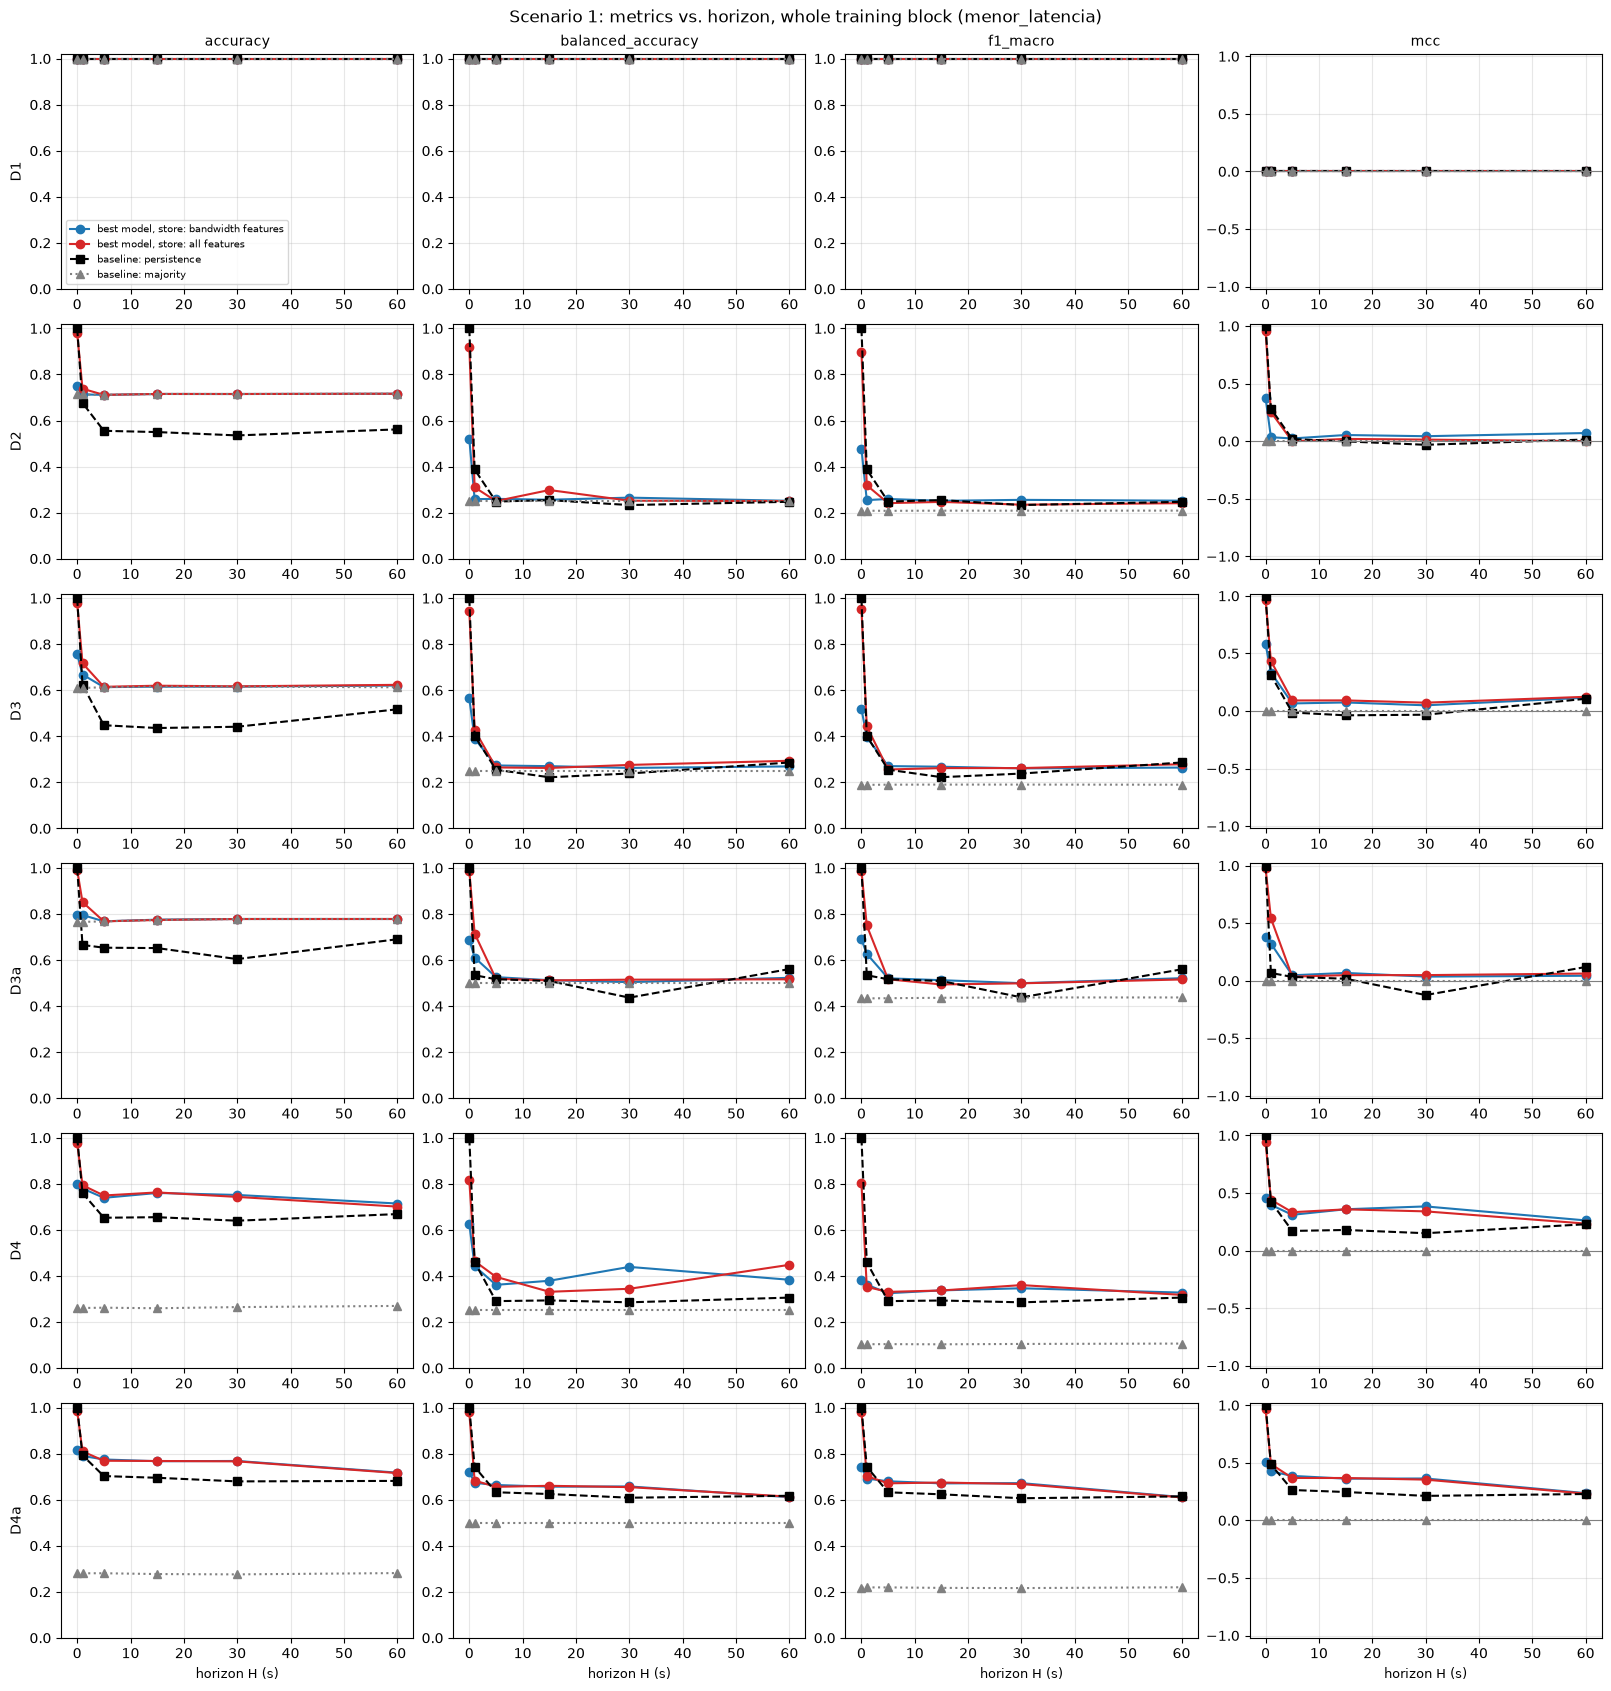

F1-macro of the best model minus that of persistence:


horizon_s                             0      1      5      15     30     60
dataset feature_set                                                        
D1      store: all features        0.000  0.000  0.000  0.000  0.000  0.000
        store: bandwidth features  0.000  0.000  0.000  0.000  0.000  0.000
D2      store: all features       -0.103 -0.069 -0.007 -0.008  0.001 -0.006
        store: bandwidth features -0.522 -0.133  0.011 -0.003  0.022  0.005
D3      store: all features       -0.046  0.042  0.001  0.039  0.024 -0.008
        store: bandwidth features -0.481 -0.005  0.016  0.045  0.022 -0.022
D3a     store: all features       -0.011  0.215 -0.000 -0.015  0.061 -0.044
        store: bandwidth features -0.310  0.093  0.004  0.004  0.062 -0.039
D4      store: all features       -0.198 -0.107  0.040  0.044  0.074  0.011
        store: bandwidth features -0.617 -0.097  0.034  0.044  0.061  0.022
D4a     store: all features       -0.018 -0.041  0.038  0.051  0.061 -0.003
        store: bandwidth features -0.257 -0.051  0.048  0.048  0.066 -0.003

In [ ]:
# Metrics beyond accuracy over the horizons. Each panel shows, for one dataset and one
#   metric, the best model of each feature set (best by that metric, so the model may
#   change from panel to panel) against the two baselines. On balanced accuracy, F1
#   and MCC the majority class drops to 1 / routes, low and 0 respectively, which is
#   where a model that only follows the dominant route shows up.
METRICS_PLOT_FS = ['accuracy', 'balanced_accuracy', 'f1_macro', 'mcc']


def best_by_metric_fs(metrics, keys, predictors=evaluated_models):
    """For every case and metric, the highest value among the given predictors."""
    models = metrics[metrics.predictor.isin(predictors)]
    return models.groupby(keys)[METRICS_FS].max()


best_metrics_fs = {}
for target in targets:
    metrics = sweep_metrics_fs[target]
    best_metrics_fs[target] = best_by_metric_fs(metrics, ['dataset', 'feature_set', 'horizon_s'])
    best_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'sweep_best_by_metric.csv')

    plot_metric_panels_fs(
        best_metrics_fs[target], metrics, 'horizon_s', METRICS_PLOT_FS, BASELINES_FS,
        datasets, feature_sets, feature_sets_colors,
        f'Scenario 1: metrics vs. horizon, whole training block ({target})', 'horizon H (s)',
        path=RESULTS_DIR[target] / 'sweep_metrics.png')

    print(f'=== target: {target} ===')
    print('F1-macro of the best model minus that of persistence:')
    persistence = (metrics[metrics.predictor == 'persistence']
                   .set_index(['dataset', 'feature_set', 'horizon_s']))
    display((best_metrics_fs[target]['f1_macro'] - persistence['f1_macro'])
            .unstack('horizon_s').reindex(datasets, level=0).round(3))

## Scenario 2: training window W

Accuracy over the evaluated test instants, per `(dataset, feature set, H, W, model)`,
next to three baselines measured on the same instants: persistence, the window
majority, and the **full block** model of scenario 1 (same feature set, horizon and
model). The full-block accuracy is measured on every test instant and this scenario
on one instant every `WINDOW_STEP` seconds, so the two match closely but not
exactly. `single_class %` is the share of windows holding a single label; when it
is close to 100%, every model collapses into the window majority, and a gain at
that `W` comes from the recent labels rather than from `X`.

In [ ]:
_case_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
_columns_fs = ['best model', 'accuracy', 'persistence', 'window_majority', 'full_block',
               'single_class_pct', 'gain over persistence']
window_metrics_fs, window_best_fs = {}, {}
for target in targets:
    rows = []
    for case, group in window_predictions_fs[target].groupby(_case_fs):
        common = dict(zip(_case_fs, case),
                      instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      single_class_pct=100 * group.single_class.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({
                **common, 'model': model,
                'accuracy': accuracy_score(group.y_true, group[model]),
                'f1_macro': f1_score(group.y_true, group[model], average='macro', zero_division=0),
            })

    window_metrics_fs[target] = pd.DataFrame(rows).merge(
        sweep_fs[target].rename(columns={'accuracy': 'full_block', 'f1_macro': 'full_block_f1'}),
        on=['dataset', 'feature_set', 'horizon_s', 'model'], how='left')
    window_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_metrics.csv', index=False)

    best = (window_metrics_fs[target].sort_values('accuracy', ascending=False)
            .drop_duplicates(_case_fs)
            .rename(columns={'model': 'best model'})
            .set_index(_case_fs).sort_index()
            .reindex(datasets, level=0))
    best['gain over persistence'] = best['accuracy'] - best['persistence']
    best['gain over window majority'] = best['accuracy'] - best['window_majority']
    window_best_fs[target] = best
    best.to_csv(RESULTS_DIR[target] / 'window_best_model.csv')

    print(f'=== target: {target} ===')
    print(f'Best model per window at the reference horizon H={H_REF}s:')
    display(best.xs(H_REF, level='horizon_s')[_columns_fs].round(4))

    print('Gain of the best window model over persistence (rows: dataset, feature set, W; '
          'columns: H):')
    display(best['gain over persistence'].unstack('horizon_s').round(4))

Best model per window at the reference horizon H=30s:


best model  accuracy  \
dataset feature_set               window_s                                 
D1      store: all features       5         LogisticRegression      1.00   
                                  10              DecisionTree      1.00   
                                  15        LogisticRegression      1.00   
                                  30        LogisticRegression      1.00   
                                  45                ExtraTrees      1.00   
...                                                        ...       ...   
D4a     store: bandwidth features 10              DecisionTree      0.72   
                                  15                KNeighbors      0.84   
                                  30                KNeighbors      0.88   
                                  45                       SVC      0.80   
                                  60                       SVC      0.80   

                                            persistence  window_majority  \
dataset feature_set               window_s                                 
D1      store: all features       5                1.00             1.00   
                                  10               1.00             1.00   
                                  15               1.00             1.00   
                                  30               1.00             1.00   
                                  45               1.00             1.00   
...                                                 ...              ...   
D4a     store: bandwidth features 10               0.68             0.68   
                                  15               0.68             0.76   
                                  30               0.68             0.76   
                                  45               0.68             0.76   
                                  60               0.68             0.80   

                                            full_block  single_class_pct  \
dataset feature_set               window_s                                 
D1      store: all features       5             1.0000             100.0   
                                  10            1.0000             100.0   
                                  15            1.0000             100.0   
                                  30            1.0000             100.0   
                                  45            1.0000             100.0   
...                                                ...               ...   
D4a     store: bandwidth features 10            0.6180              20.0   
                                  15            0.6862              20.0   
                                  30            0.6862              20.0   
                                  45            0.7544              16.0   
                                  60            0.7544              16.0   

                                            gain over persistence  
dataset feature_set               window_s                         
D1      store: all features       5                          0.00  
                                  10                         0.00  
                                  15                         0.00  
                                  30                         0.00  
                                  45                         0.00  
...                                                           ...  
D4a     store: bandwidth features 10                         0.04  
                                  15                         0.16  
                                  30                         0.20  
                                  45                         0.12  
                                  60                         0.12  

[72 rows x 7 columns]

Gain of the best window model over persistence (rows: dataset, feature set, W; columns: H):


horizon_s                                       0       1       5       15  \
dataset feature_set               window_s                                   
D1      store: all features       5         0.0000  0.0000  0.0000  0.0000   
                                  10        0.0000  0.0000  0.0000  0.0000   
                                  15        0.0000  0.0000  0.0000  0.0000   
                                  30        0.0000  0.0000  0.0000  0.0000   
                                  45        0.0000  0.0000  0.0000  0.0000   
...                                            ...     ...     ...     ...   
D4a     store: bandwidth features 10       -0.2308  0.0385  0.1538  0.2308   
                                  15       -0.1923  0.0385  0.1538  0.1923   
                                  30       -0.1923  0.0385  0.1154  0.1538   
                                  45       -0.1538  0.0000  0.1538  0.1538   
                                  60       -0.1923 -0.0385  0.1538  0.1538   

horizon_s                                     30      60  
dataset feature_set               window_s                
D1      store: all features       5         0.00  0.0000  
                                  10        0.00  0.0000  
                                  15        0.00  0.0000  
                                  30        0.00  0.0000  
                                  45        0.00  0.0000  
...                                          ...     ...  
D4a     store: bandwidth features 10        0.04  0.0417  
                                  15        0.16  0.0417  
                                  30        0.20  0.0417  
                                  45        0.12  0.0417  
                                  60        0.12  0.0000  

[72 rows x 6 columns]

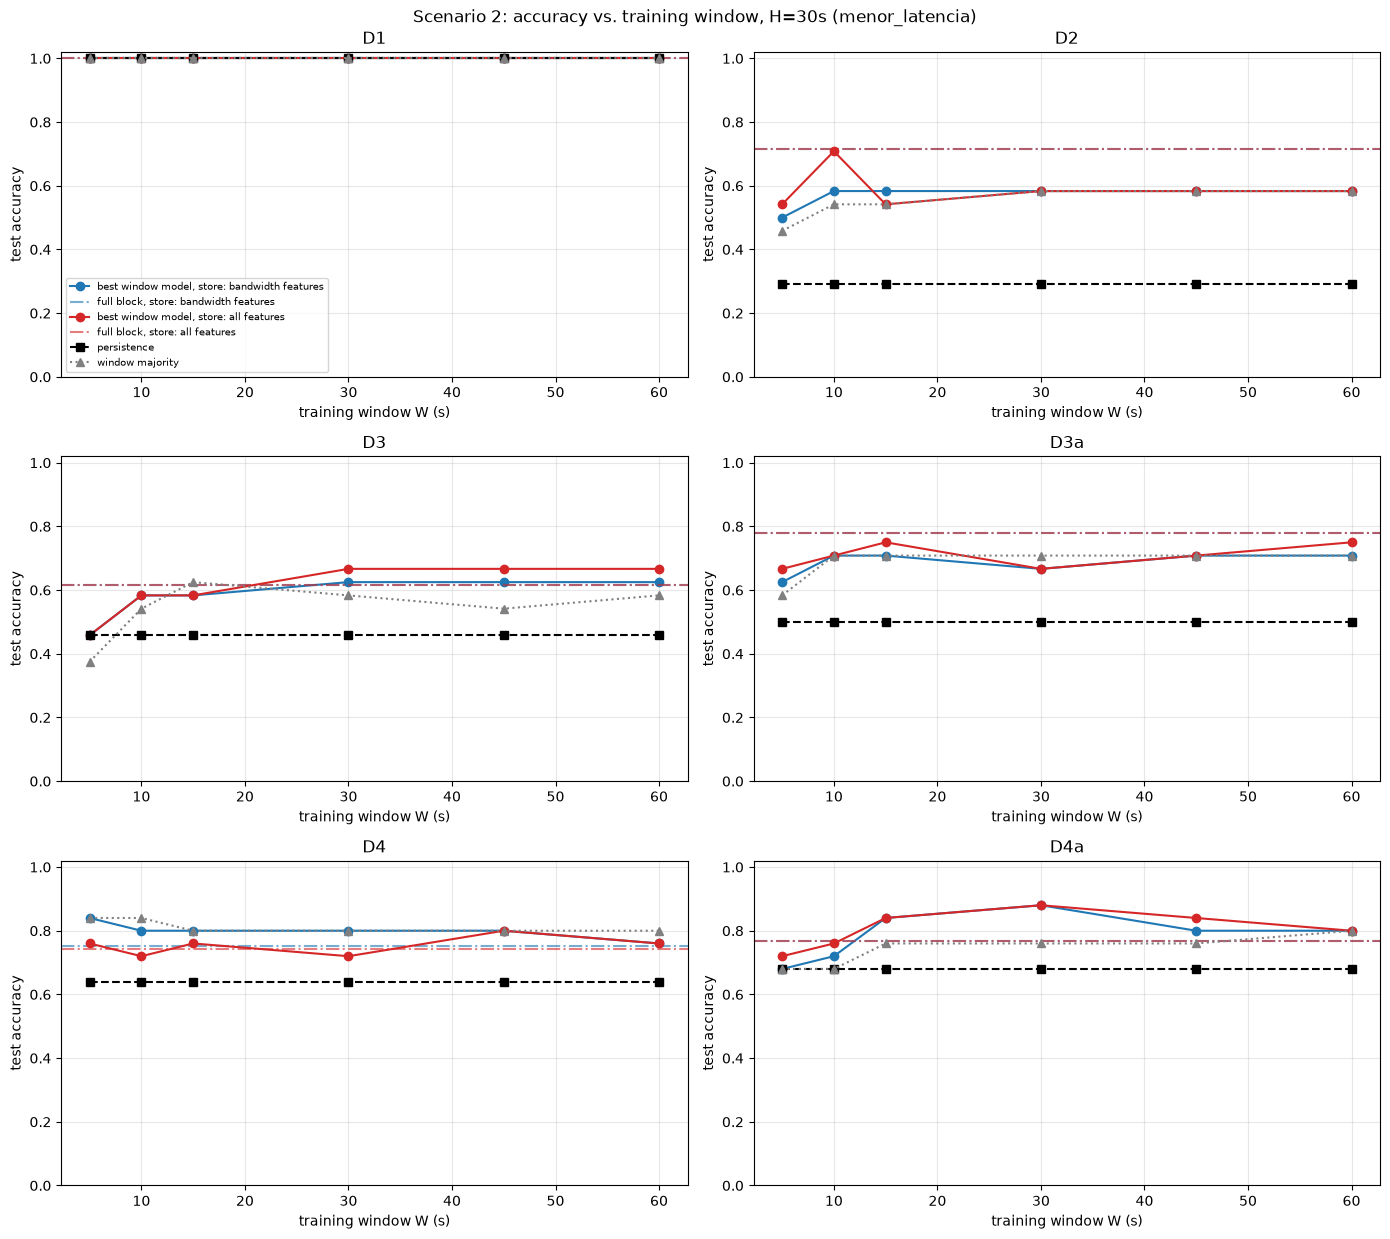

In [ ]:
for target in targets:
    plot_window_accuracy_fs(
        window_best_fs[target], best_fs[target], H_REF, datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 2: accuracy vs. training window, H={H_REF}s ({target})',
        path=RESULTS_DIR[target] / f'window_accuracy_H{H_REF}.png')

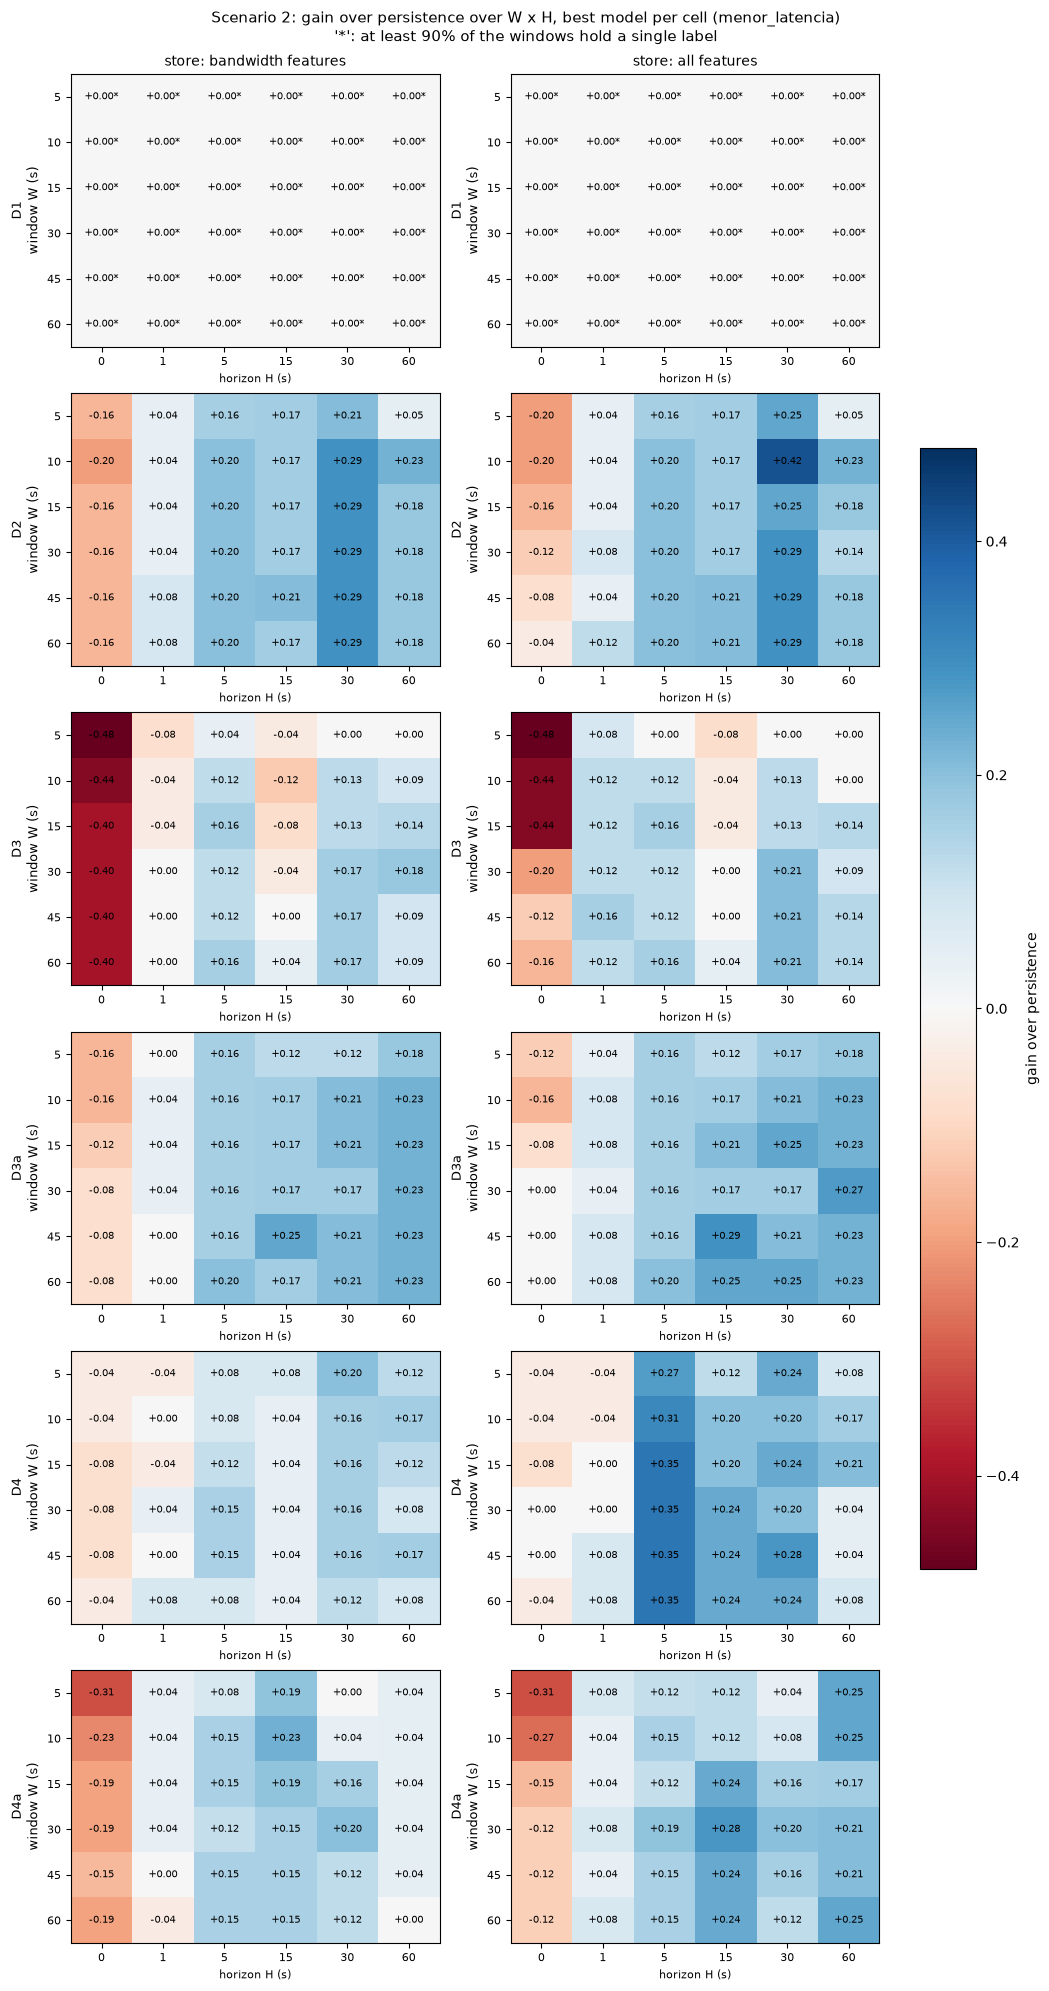

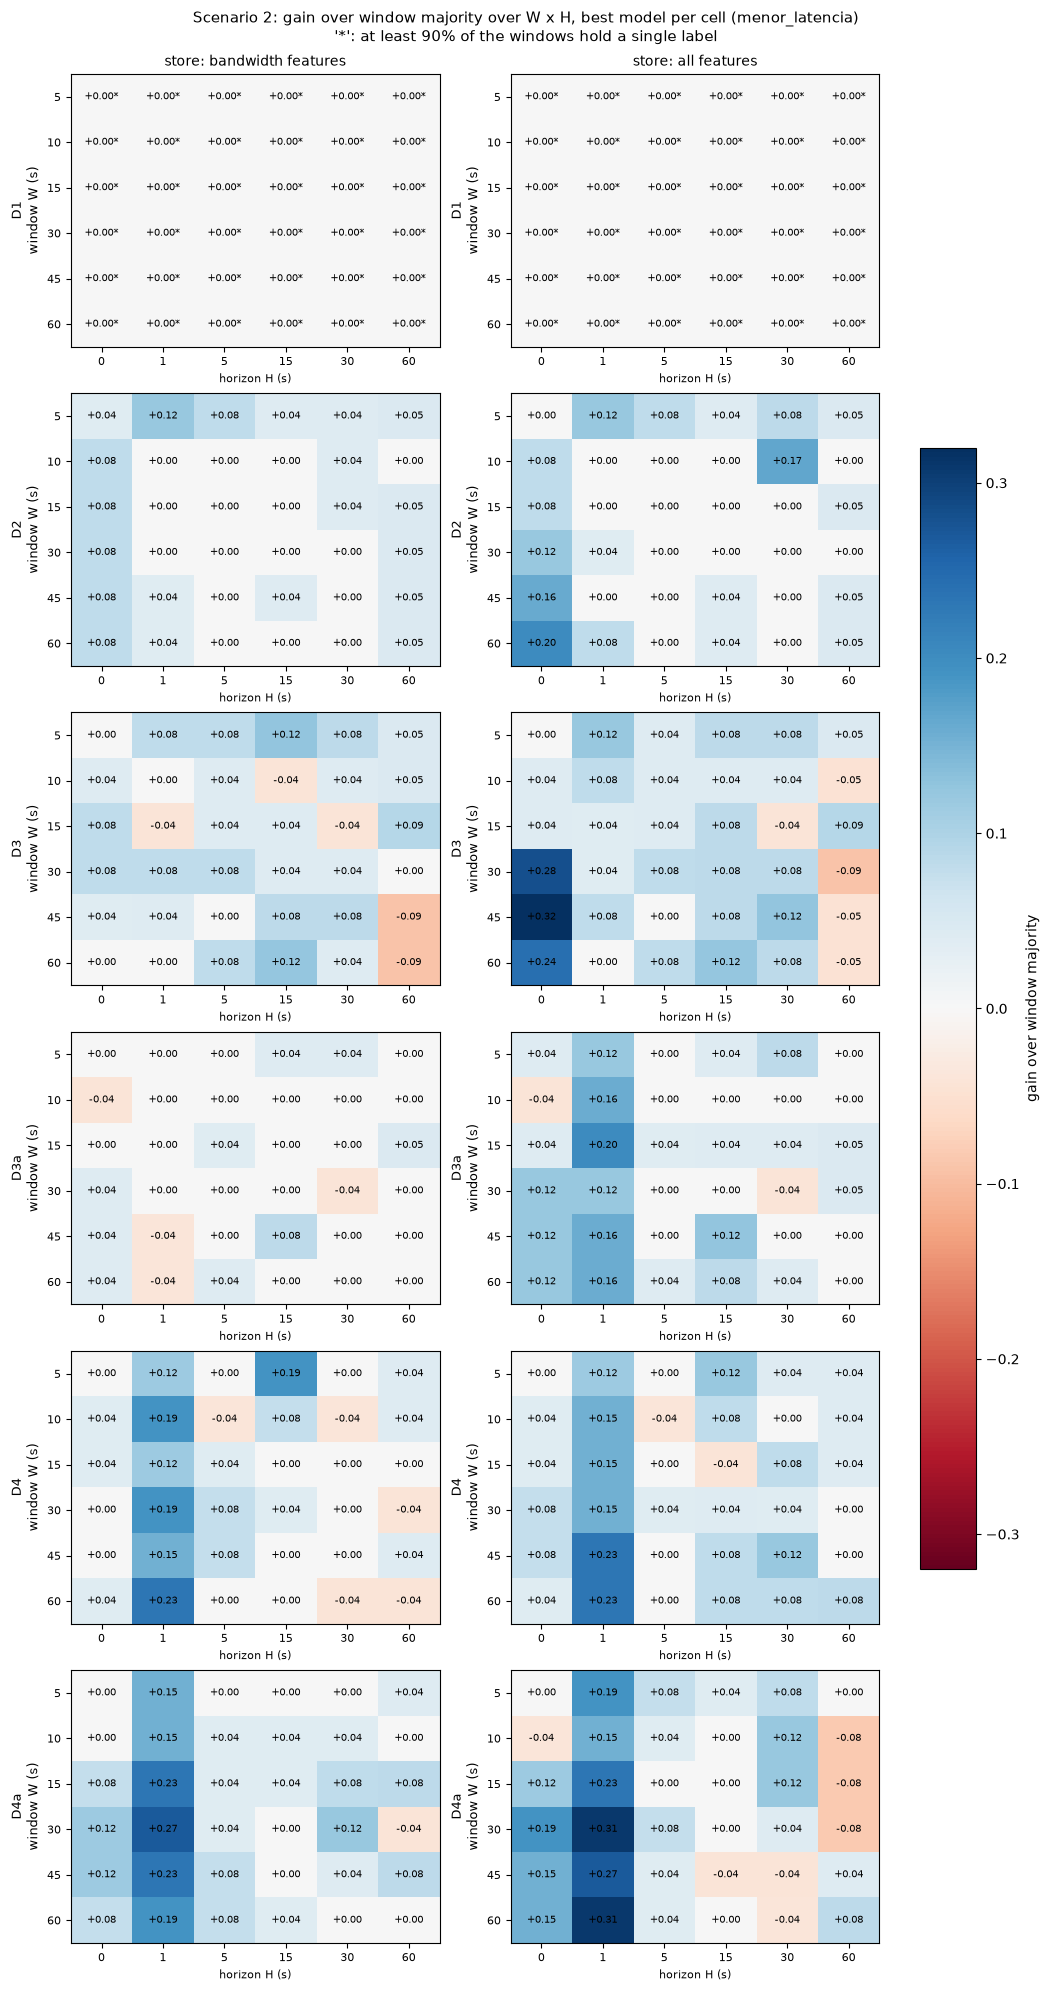

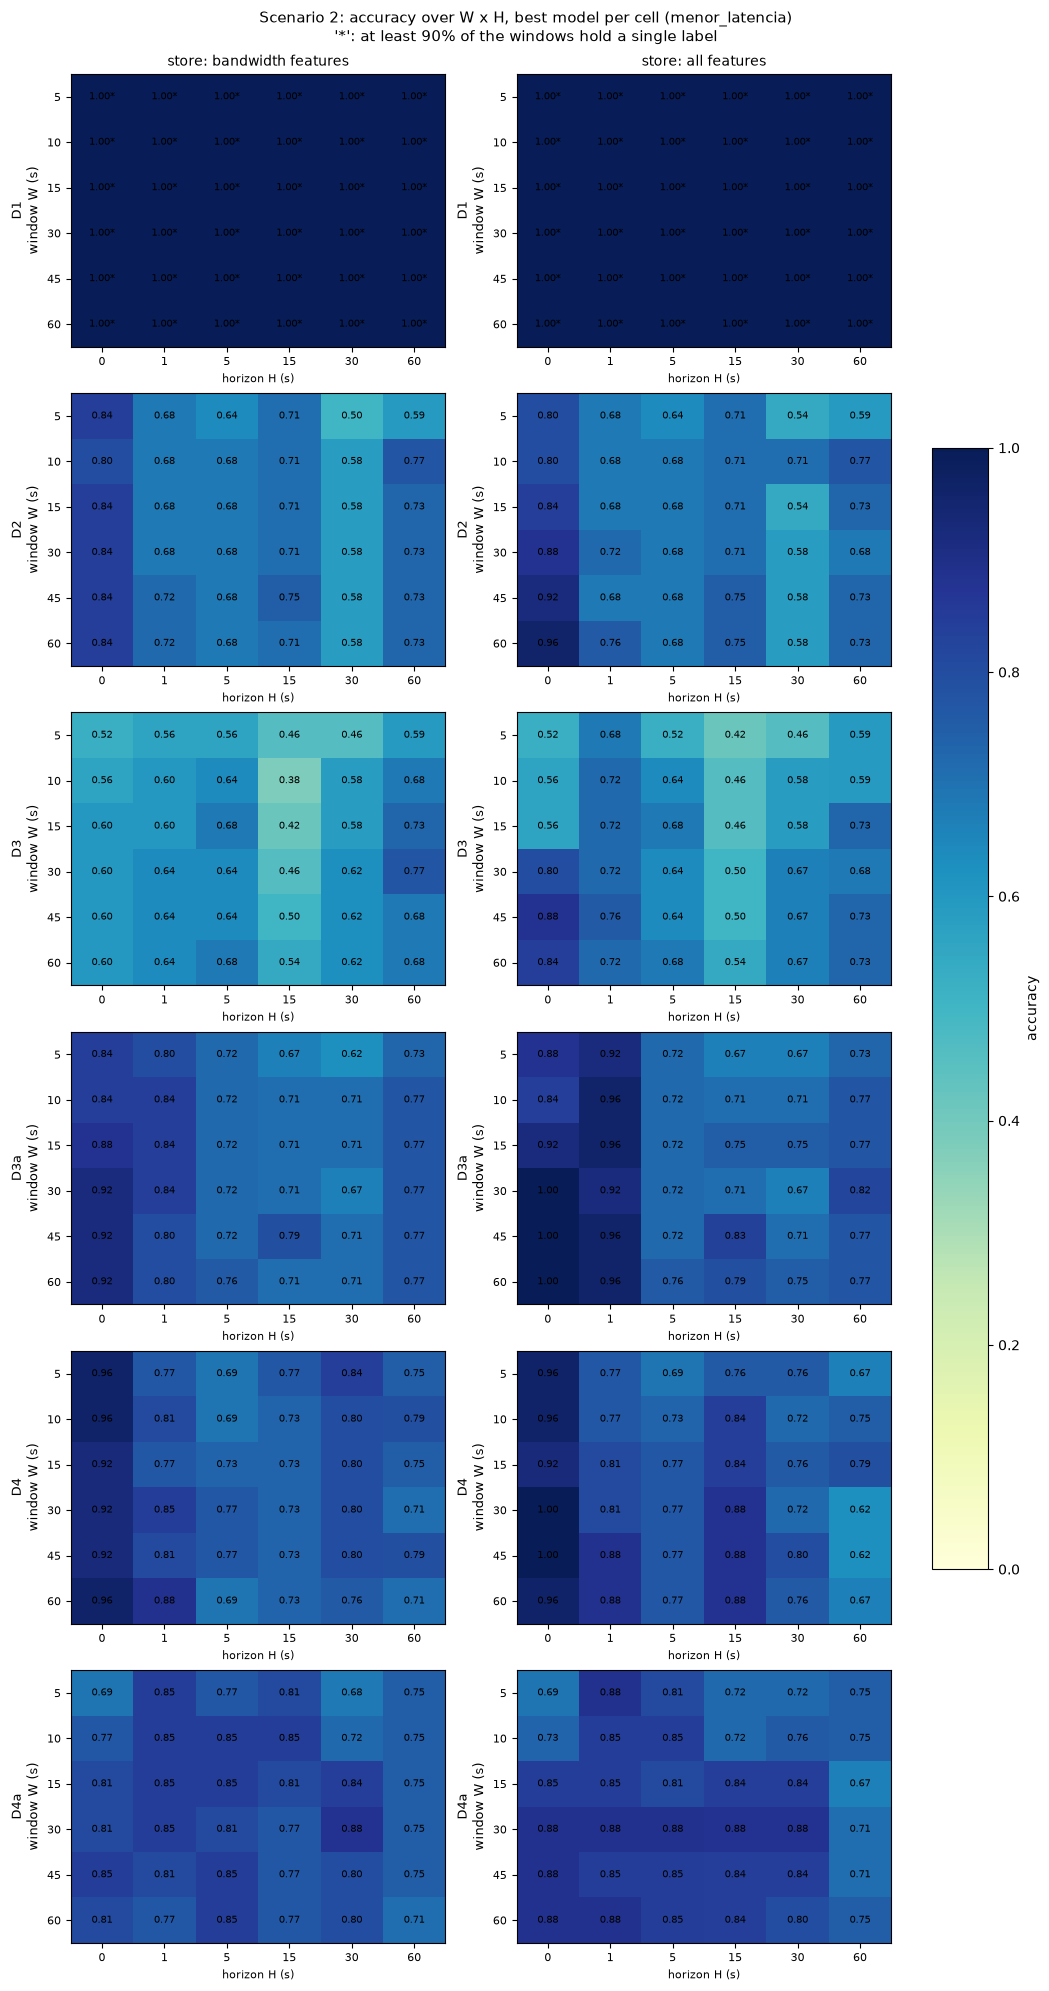

gain over persistence (best model per cell); rows: dataset, feature set, W; columns: H


horizon_s                                      0      1      5      15    30  \
dataset feature_set               window_s                                     
D1      store: all features       5         0.000  0.000  0.000  0.000  0.00   
                                  10        0.000  0.000  0.000  0.000  0.00   
                                  15        0.000  0.000  0.000  0.000  0.00   
                                  30        0.000  0.000  0.000  0.000  0.00   
                                  45        0.000  0.000  0.000  0.000  0.00   
...                                           ...    ...    ...    ...   ...   
D4a     store: bandwidth features 10       -0.231  0.038  0.154  0.231  0.04   
                                  15       -0.192  0.038  0.154  0.192  0.16   
                                  30       -0.192  0.038  0.115  0.154  0.20   
                                  45       -0.154  0.000  0.154  0.154  0.12   
                                  60       -0.192 -0.038  0.154  0.154  0.12   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.042  
                                  15        0.042  
                                  30        0.042  
                                  45        0.042  
                                  60        0.000  

[72 rows x 6 columns]

gain over window majority (best model per cell); rows: dataset, feature set, W; columns: H


horizon_s                                      0      1      5      15    30  \
dataset feature_set               window_s                                     
D1      store: all features       5         0.000  0.000  0.000  0.000  0.00   
                                  10        0.000  0.000  0.000  0.000  0.00   
                                  15        0.000  0.000  0.000  0.000  0.00   
                                  30        0.000  0.000  0.000  0.000  0.00   
                                  45        0.000  0.000  0.000  0.000  0.00   
...                                           ...    ...    ...    ...   ...   
D4a     store: bandwidth features 10        0.000  0.154  0.038  0.038  0.04   
                                  15        0.077  0.231  0.038  0.038  0.08   
                                  30        0.115  0.269  0.038  0.000  0.12   
                                  45        0.115  0.231  0.077  0.000  0.04   
                                  60        0.077  0.192  0.077  0.038  0.00   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.000  
                                  15        0.083  
                                  30       -0.042  
                                  45        0.083  
                                  60        0.000  

[72 rows x 6 columns]

In [ ]:
# Results over the whole (W, H) grid: one heatmap per dataset and feature set, with
#   the training window W on the rows and the horizon H on the columns.
#
#   MODEL_GRID_FS = None picks, in every cell, the model with the highest accuracy on
#   the evaluated test instants. That choice is made on the test instants themselves,
#   so it is optimistic. Set a model name (e.g. 'RandomForest') to read a single
#   model across the grid instead.
#
#   Three metrics, each in its own figure:
#     gain over persistence     - accuracy minus "the best route in H s is the one now"
#     gain over window majority - accuracy minus the most frequent label of the window,
#                                 i.e. what the model adds by using X at all
#     accuracy                  - the absolute value, for reference
#   A '*' marks the cells where at least SINGLE_CLASS_MARK_FS % of the windows hold a
#   single label: there every model returns the window majority, so the cell says
#   nothing about X.
MODEL_GRID_FS = None
SINGLE_CLASS_MARK_FS = 90

GRID_METRICS_FS = ['gain over persistence', 'gain over window majority', 'accuracy']
grid_model_label_fs = 'best model per cell' if MODEL_GRID_FS is None else MODEL_GRID_FS
_grid_tag_fs = 'best' if MODEL_GRID_FS is None else MODEL_GRID_FS

grid_table_fs = {}
for target in targets:
    if MODEL_GRID_FS is None:
        grid_source = window_best_fs[target].reset_index()
    else:
        metrics = window_metrics_fs[target]
        grid_source = metrics[metrics.model == MODEL_GRID_FS].copy()
        grid_source['gain over persistence'] = grid_source.accuracy - grid_source.persistence
        grid_source['gain over window majority'] = (grid_source.accuracy
                                                    - grid_source.window_majority)

    # Long table of the grid, saved once for every metric
    grid_table_fs[target] = (grid_source
                             .set_index(['dataset', 'feature_set', 'window_s', 'horizon_s'])
                             [GRID_METRICS_FS + ['persistence', 'window_majority',
                                                 'single_class_pct']]
                             .sort_index())
    grid_table_fs[target].to_csv(RESULTS_DIR[target] / f'window_grid_W_H_{_grid_tag_fs}.csv')

    for metric in GRID_METRICS_FS:
        plot_window_grid_fs(
            grid_source, metric,
            f'Scenario 2: {metric} over W x H, {grid_model_label_fs} ({target})',
            datasets, feature_sets, windows, horizons,
            SINGLE_CLASS_MARK_FS,
            path=(RESULTS_DIR[target]
                  / f'window_grid_{metric.replace(" ", "_")}_{_grid_tag_fs}.png'))

    # The same grid as tables: rows are (dataset, feature set, W), columns are H
    print(f'=== target: {target} ===')
    for metric in GRID_METRICS_FS[:2]:
        print(f'{metric} ({grid_model_label_fs}); rows: dataset, feature set, W; columns: H')
        display(grid_table_fs[target][metric].unstack('horizon_s')
                .reindex(columns=horizons).round(3))

### Scenario 2: confusion matrices and metrics beyond accuracy

The same metrics for the sliding training window, computed from the predictions the
loop already stored (`window_predictions_fs`), so nothing is retrained. The
predictors are the 7 models plus **persistence** and the **window majority**.
Each `(dataset, feature set, H, W)` case is scored on the evaluated instants only,
about 25 per case with `WINDOW_STEP = 30`. With so few instants a minority route
may appear once or twice, so `mcc` and the macro averages move in large steps; read
them as orders of magnitude.

Best model by each metric, H=30s (rows: dataset, feature set, W):


accuracy  balanced_accuracy  \
dataset feature_set               window_s                                
D1      store: all features       5             1.00              1.000   
                                  10            1.00              1.000   
                                  15            1.00              1.000   
                                  30            1.00              1.000   
                                  45            1.00              1.000   
...                                              ...                ...   
D4a     store: bandwidth features 10            0.72              0.675   
                                  15            0.84              0.725   
                                  30            0.88              0.850   
                                  45            0.80              0.750   
                                  60            0.80              0.700   

                                            precision_macro  recall_macro  \
dataset feature_set               window_s                                  
D1      store: all features       5                   1.000         1.000   
                                  10                  1.000         1.000   
                                  15                  1.000         1.000   
                                  30                  1.000         1.000   
                                  45                  1.000         1.000   
...                                                     ...           ...   
D4a     store: bandwidth features 10                  0.629         0.675   
                                  15                  0.765         0.725   
                                  30                  0.807         0.850   
                                  45                  0.697         0.750   
                                  60                  0.679         0.700   

                                            f1_macro    mcc  
dataset feature_set               window_s                   
D1      store: all features       5            1.000  0.000  
                                  10           1.000  0.000  
                                  15           1.000  0.000  
                                  30           1.000  0.000  
                                  45           1.000  0.000  
...                                              ...    ...  
D4a     store: bandwidth features 10           0.636  0.300  
                                  15           0.709  0.431  
                                  30           0.825  0.656  
                                  45           0.709  0.421  
                                  60           0.671  0.356  

[72 rows x 6 columns]

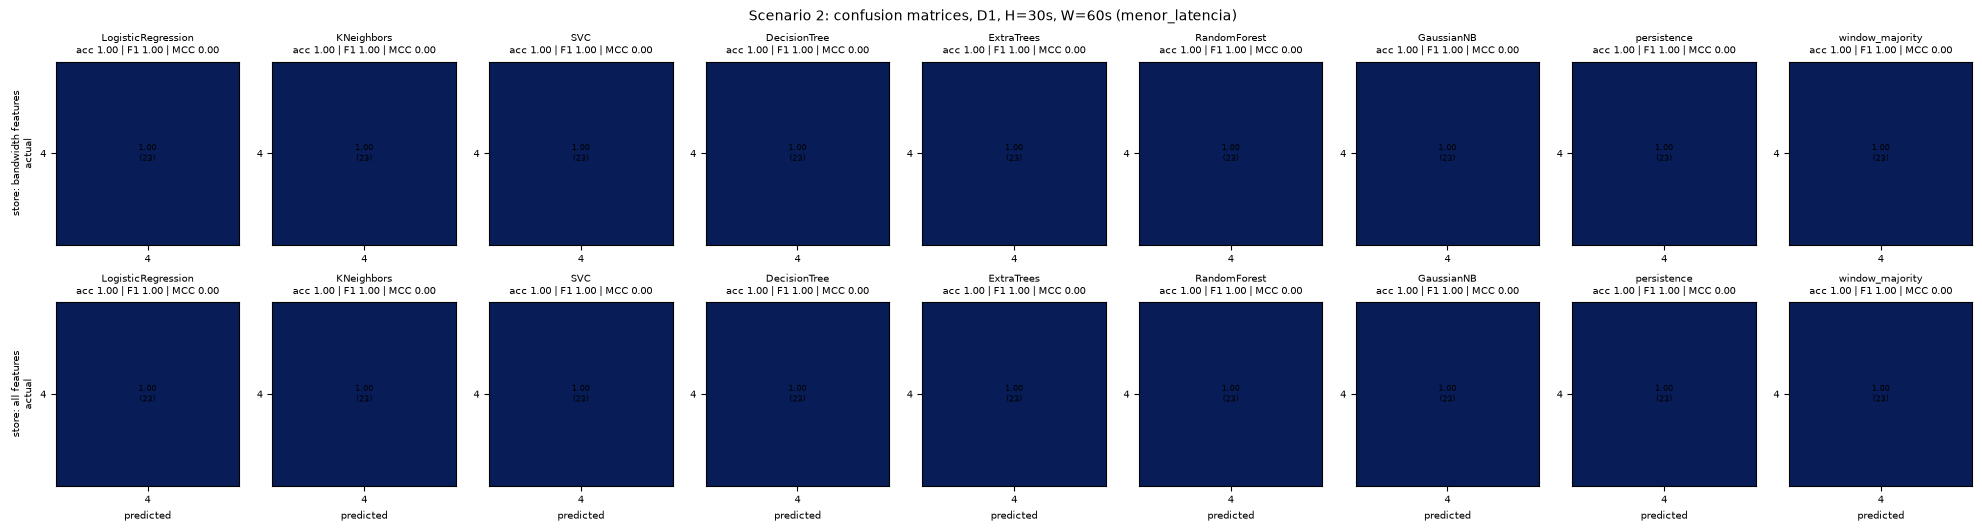

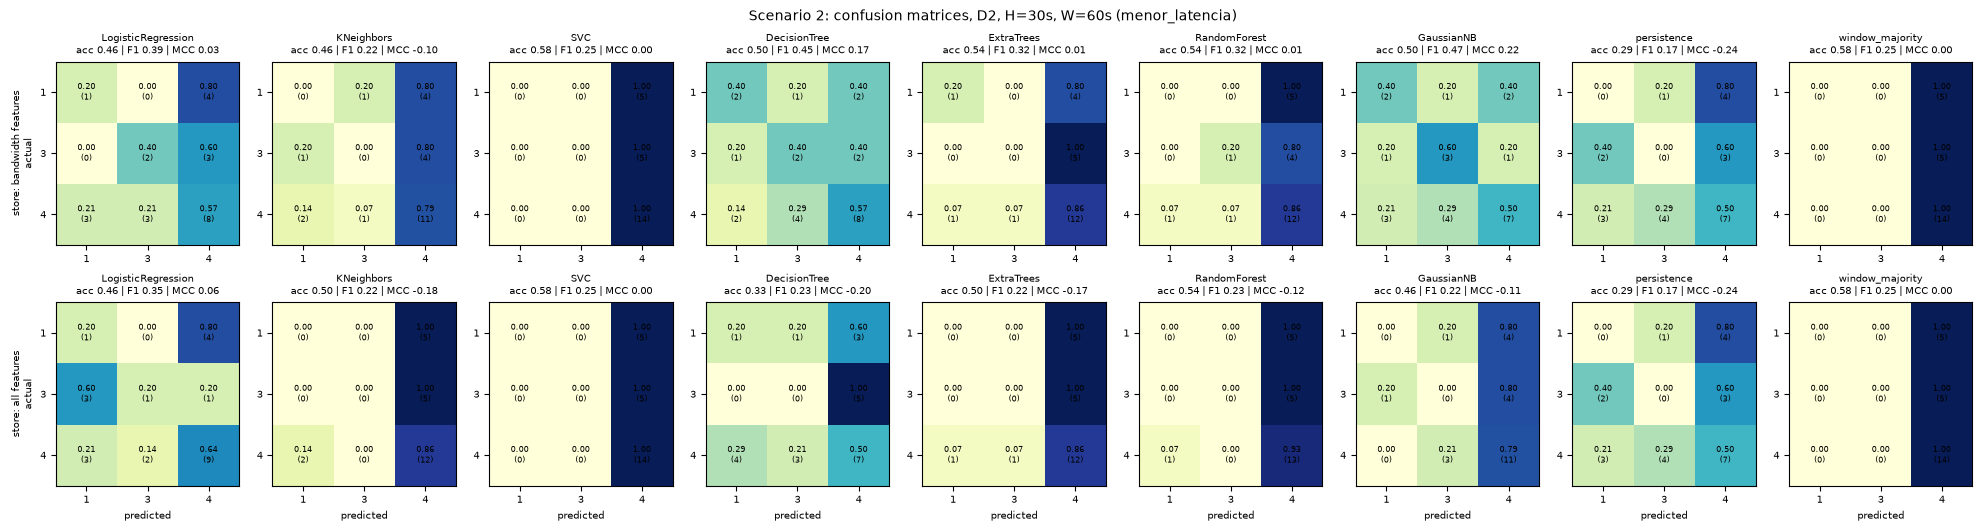

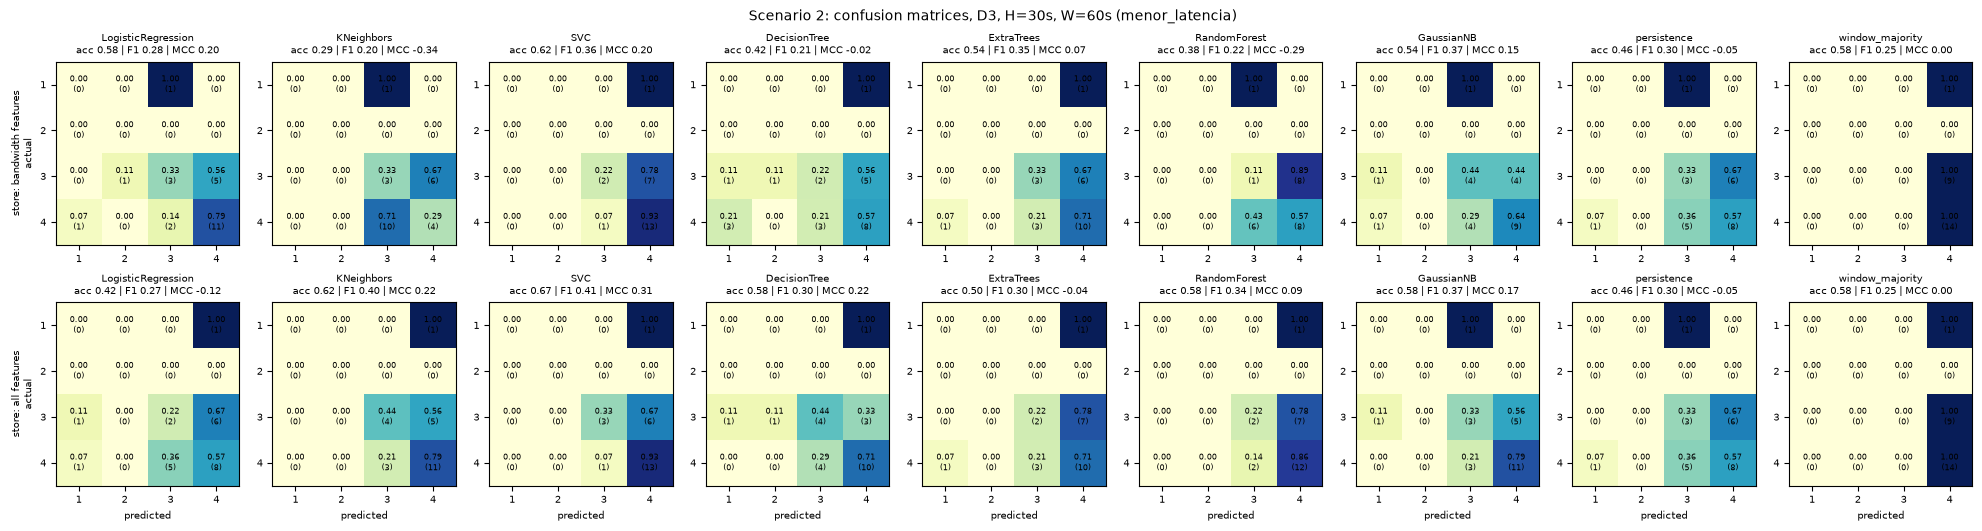

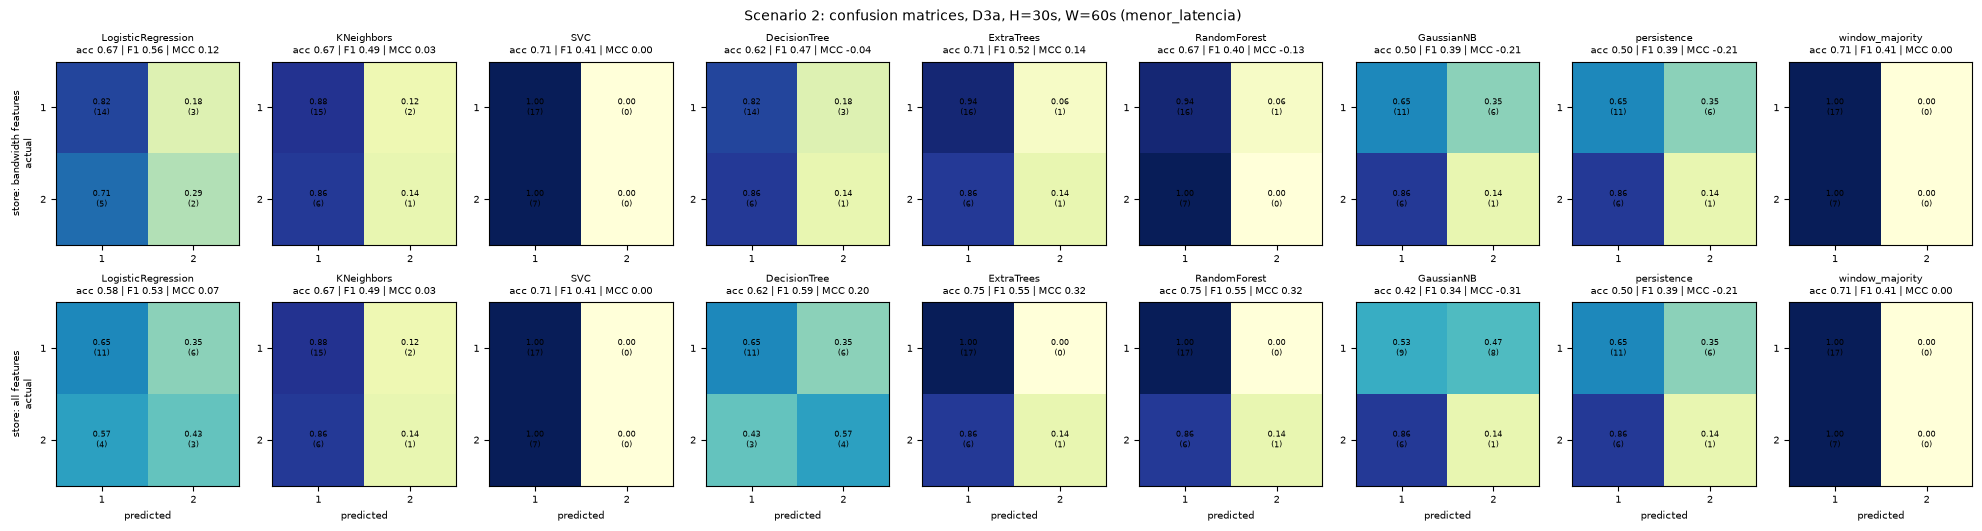

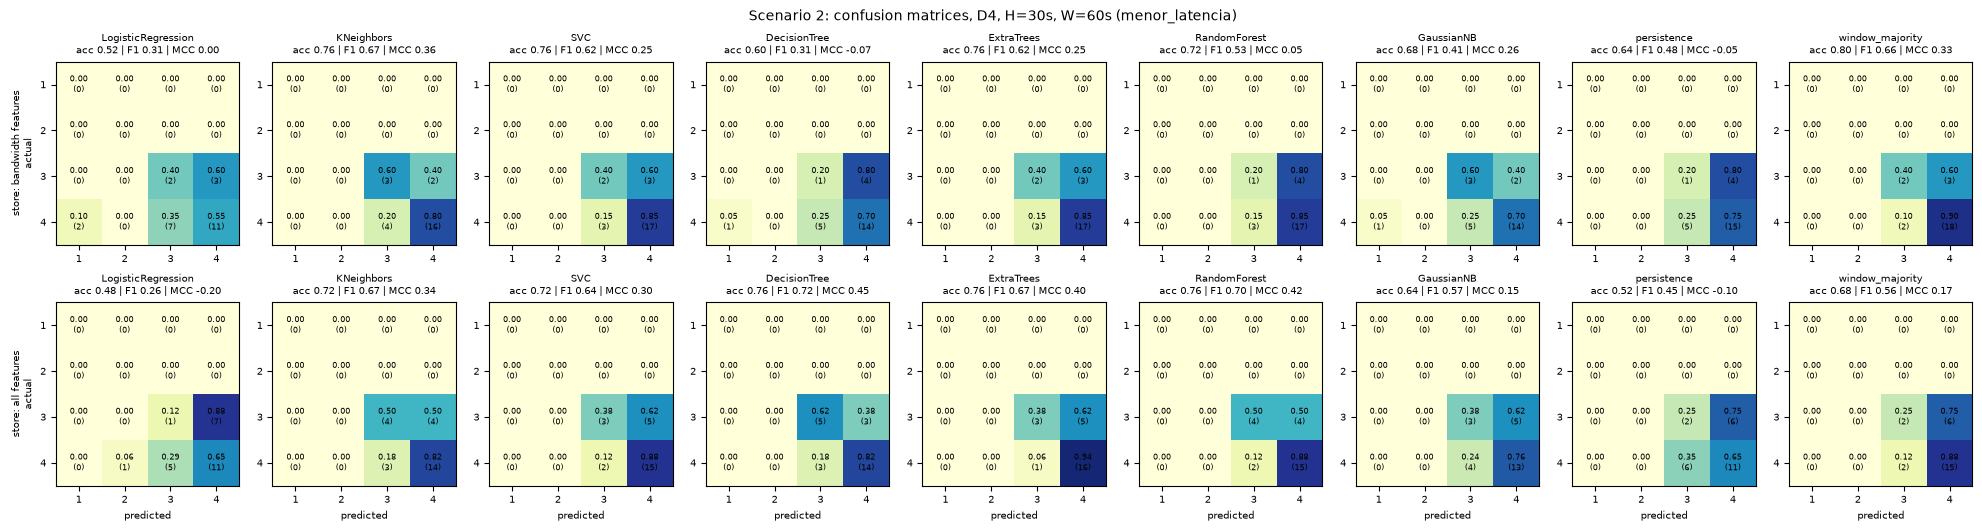

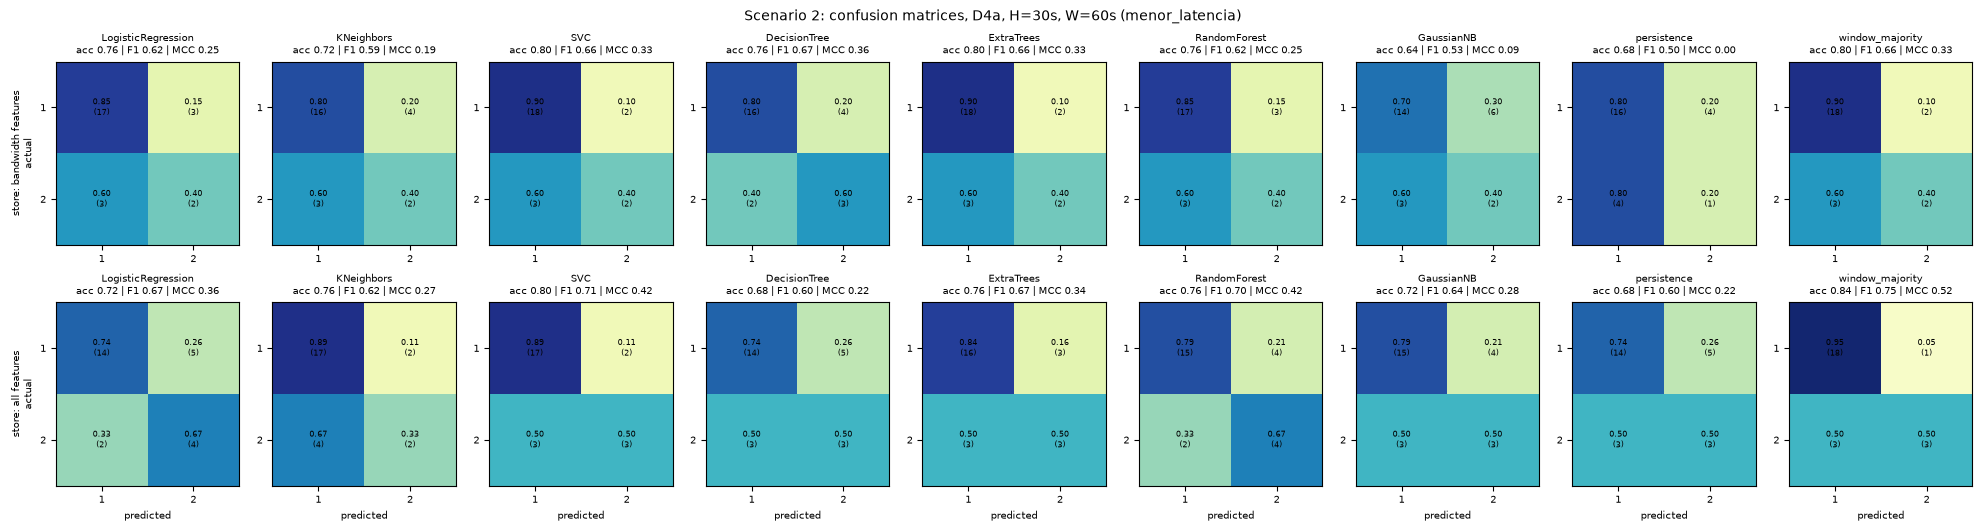

In [ ]:
WINDOW_BASELINES_FS = ['persistence', 'window_majority']

# Confusion matrices at the reference horizon and one window size, summed over the
#   evaluated instants of each dataset's test block
CONFUSION_W_FS = 60
CONFUSION_WINDOW_PREDICTORS_FS = evaluated_models + WINDOW_BASELINES_FS

window_class_metrics_fs, window_best_metrics_fs = {}, {}
for target in targets:
    predictions = window_predictions_fs[target]
    window_class_metrics_fs[target] = metrics_table_fs(
        predictions, ['dataset', 'feature_set', 'horizon_s', 'window_s'],
        evaluated_models + WINDOW_BASELINES_FS)
    window_class_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_class_metrics.csv',
                                           index=False)

    window_best_metrics_fs[target] = best_by_metric_fs(
        window_class_metrics_fs[target], ['dataset', 'feature_set', 'horizon_s', 'window_s'])
    window_best_metrics_fs[target].to_csv(RESULTS_DIR[target] / 'window_best_by_metric.csv')

    print(f'=== target: {target} ===')
    print(f'Best model by each metric, H={H_REF}s (rows: dataset, feature set, W):')
    display(window_best_metrics_fs[target].xs(H_REF, level='horizon_s')
            .reindex(datasets, level=0).round(3))

    case = predictions[(predictions.horizon_s == H_REF)
                       & (predictions.window_s == CONFUSION_W_FS)]
    for dataset in datasets:
        plot_confusion_rows_fs(
            case, dataset,
            f'Scenario 2: confusion matrices, {dataset}, H={H_REF}s, W={CONFUSION_W_FS}s '
            f'({target})',
            CONFUSION_WINDOW_PREDICTORS_FS, feature_sets, normalize=CONFUSION_NORMALIZE_FS,
            path=(RESULTS_DIR[target]
                  / f'window_confusion_{dataset}_H{H_REF}_W{CONFUSION_W_FS}.png'))

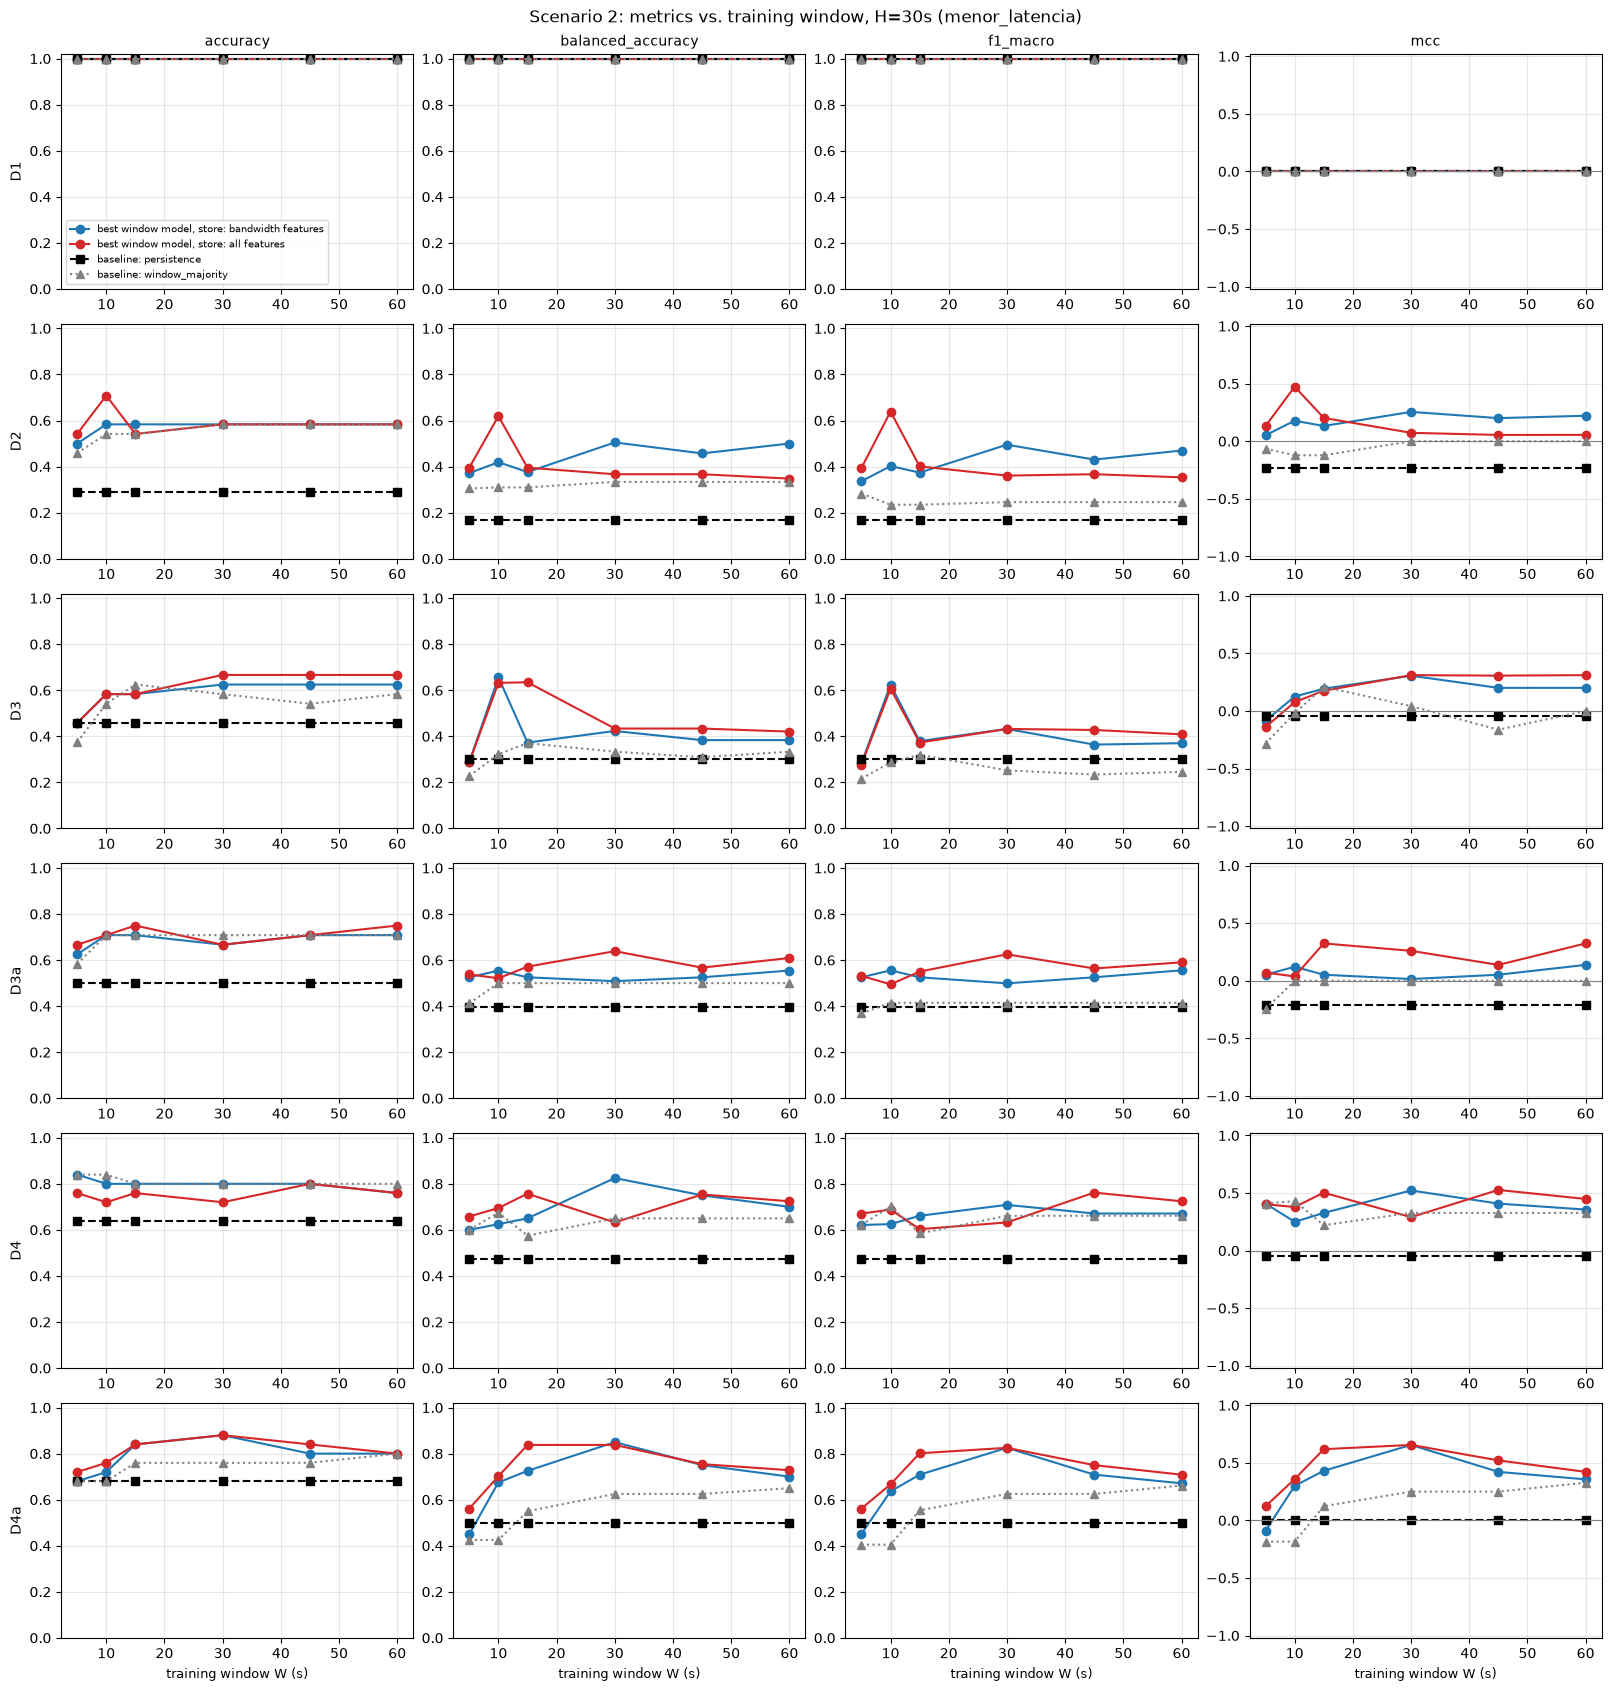

f1_macro of the best window model minus that of the window majority (rows: dataset, feature set, W; columns: H):


horizon_s                                      0      1      5      15     30  \
dataset feature_set               window_s                                      
D1      store: all features       5         0.000  0.000  0.000  0.000  0.000   
                                  10        0.000  0.000  0.000  0.000  0.000   
                                  15        0.000  0.000  0.000  0.000  0.000   
                                  30        0.000  0.000  0.000  0.000  0.000   
                                  45        0.000  0.000  0.000  0.000  0.000   
...                                           ...    ...    ...    ...    ...   
D4a     store: bandwidth features 10        0.072  0.374  0.117  0.061  0.231   
                                  15        0.134  0.402  0.040  0.069  0.155   
                                  30        0.170  0.417  0.083  0.022  0.200   
                                  45        0.223  0.346  0.124  0.038  0.084   
                                  60        0.182  0.341  0.155  0.088  0.010   

horizon_s                                      60  
dataset feature_set               window_s         
D1      store: all features       5         0.000  
                                  10        0.000  
                                  15        0.000  
                                  30        0.000  
                                  45        0.000  
...                                           ...  
D4a     store: bandwidth features 10        0.000  
                                  15        0.101  
                                  30       -0.039  
                                  45        0.101  
                                  60        0.026  

[72 rows x 6 columns]

In [ ]:
# Metrics beyond accuracy against the window size, at the reference horizon: best
#   model of each feature set (best by the metric of the panel) against persistence
#   and the window majority, measured on the same evaluated instants. Then the whole
#   (W, H) grid of METRIC_GRID_FS: best model minus the window majority.
METRIC_GRID_FS = 'f1_macro'

for target in targets:
    class_metrics = window_class_metrics_fs[target]
    plot_metric_panels_fs(
        window_best_metrics_fs[target].xs(H_REF, level='horizon_s'),
        class_metrics[class_metrics.horizon_s == H_REF],
        'window_s', METRICS_PLOT_FS, WINDOW_BASELINES_FS,
        datasets, feature_sets, feature_sets_colors,
        f'Scenario 2: metrics vs. training window, H={H_REF}s ({target})',
        'training window W (s)', curve_label='best window model',
        path=RESULTS_DIR[target] / f'window_metrics_H{H_REF}.png')

    majority = (class_metrics[class_metrics.predictor == 'window_majority']
                .set_index(['dataset', 'feature_set', 'horizon_s', 'window_s'])[METRIC_GRID_FS])
    print(f'=== target: {target} ===')
    print(f'{METRIC_GRID_FS} of the best window model minus that of the window majority '
          f'(rows: dataset, feature set, W; columns: H):')
    display((window_best_metrics_fs[target][METRIC_GRID_FS] - majority)
            .unstack('horizon_s').reindex(columns=horizons)
            .reindex(datasets, level=0).round(3))

## Targets side by side

With more than one target in `targets`, the reference horizon `H_REF` of both
scenarios, one column block per target. Each target is read against its own
persistence: the same route can be the best by latency and not by bandwidth, so
the absolute accuracies are not comparable across targets, the gains are.

In [ ]:
_scenario_1_columns_fs = ['best model', 'accuracy', 'persistence', 'majority',
                          'gain over persistence']
print(f'Scenario 1, H={H_REF}s: best model trained on the whole training block')
display(pd.concat({target: best_fs[target].xs(H_REF, level='horizon_s')[_scenario_1_columns_fs]
                   for target in targets}, axis=1).round(4))

print(f'Scenario 2, H={H_REF}s: gain of the best window model over persistence '
      f'and over the window majority')
display(pd.concat({target: window_best_fs[target].xs(H_REF, level='horizon_s')
                   [['gain over persistence', 'gain over window majority']]
                   for target in targets}, axis=1).round(4))

## Model selection by time-series cross-validation

The tables above report, for every case, the **best of the 7 models by its accuracy
on the test block**. That choice is made on the test block itself, so part of the
gap to the baselines is selection luck, more so in scenario 2, where each case rests
on about 25 instants. This section **adds** a selection that never looks at the
test block:

1. For every `(dataset, feature set, H)`, the training block of scenario 1 is split
   by `TimeSeriesSplit(n_splits=CV_FOLDS, gap=H)`: `CV_FOLDS` consecutive validation
   chunks, each one scored by the models trained on every instant before it, with
   `H` rows left out between the two, the same rule as the gap between the training
   and test blocks. The store has one row per second, so `H` rows span at least `H`
   seconds and no training label `y(τ + H)` falls inside the validation chunk.
2. The model with the highest mean validation accuracy is the **CV-selected model**.
   A model that cannot be trained on some fold (e.g. a fold with a single route)
   ranks below the models trained on every fold; ties go to the first model of
   `evaluated_models`.
3. Its test accuracy is read from scenario 1 (`sweep_fs`): same model, same training
   block, so nothing is refitted on the test block.
4. Scenario 2 keeps the CV-selected model of the same `(dataset, feature set, H)` and
   reads its accuracy at every `W` from `window_metrics_fs`. `W` itself is not
   selected: every `W` is reported.

Next to it, the **test-selected** model (the best model of the tables above) and two
differences:

| column | meaning |
|---|---|
| `selection optimism` | test-selected minus CV-selected accuracy; never negative, and the part of the earlier tables that came from choosing on the test block |
| `cv minus test` | mean validation accuracy minus test accuracy of the CV-selected model; large values mean the regime changes between the training and test blocks |

The hyperparameters are the fixed ones of `make_pipelines_fs`: this section chooses
among the 7 models, it does not tune them.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

CV_FOLDS = 5

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_cv_selection, CenarioPreditivoFS_<target>_cv_selection
RESULTS_DIR_CV = {target: folder.with_name(f'{folder.name}_cv_selection')
                  for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_CV.values():
    _folder.mkdir(parents=True, exist_ok=True)


def cross_validate_training_block_fs(wide, horizon_s, folds=CV_FOLDS,
                                     evaluated_models=evaluated_models):
    """Forward-chaining CV of every model inside the training block of scenario 1.

    Same frame and training block as evaluate_full_block_fs. Returns one row per
    (fold, model); a model that cannot be trained on a fold gets NaN there.
    """
    frame, train, _ = blocks_fs(wide, horizon_s)
    rows_train = np.flatnonzero(train)
    rows_train = rows_train[np.argsort(frame['ts_epoch'].to_numpy()[rows_train], kind='stable')]
    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)[rows_train]
    y = frame['melhor_rota'].to_numpy(dtype=int)[rows_train]

    rows = []
    splitter = TimeSeriesSplit(n_splits=folds, gap=horizon_s)
    for fold, (fit, validation) in enumerate(splitter.split(X), start=1):
        for name, model in make_pipelines_fs(evaluated_models).items():
            try:
                y_pred = model.fit(X[fit], y[fit]).predict(X[validation])
                accuracy = accuracy_score(y[validation], y_pred)
                f1 = f1_score(y[validation], y_pred, average='macro', zero_division=0)
            except ValueError:
                accuracy = f1 = np.nan
            rows.append({'fold': fold, 'model': name, 'n_fit': len(fit),
                         'n_validation': len(validation),
                         'fit_routes': len(np.unique(y[fit])),
                         'validation_routes': len(np.unique(y[validation])),
                         'accuracy': accuracy, 'f1_macro': f1})
    return pd.DataFrame(rows)


def select_model_cv_fs(cv_folds, evaluated_models=evaluated_models):
    """CV-selected model of one case and the per-model CV summary.

    Order: most folds trained, then highest mean validation accuracy, then the
    order of evaluated_models.
    """
    summary = (cv_folds.groupby('model')
               .agg(cv_accuracy=('accuracy', 'mean'), cv_accuracy_std=('accuracy', 'std'),
                    cv_f1_macro=('f1_macro', 'mean'), trained_folds=('accuracy', 'count'))
               .reindex(evaluated_models))
    ranking = (summary.assign(_order=np.arange(len(summary)))
               .sort_values(['trained_folds', 'cv_accuracy', '_order'],
                            ascending=[False, False, True], na_position='last'))
    return ranking.index[0], summary


print(f'CV helpers defined: TimeSeriesSplit with {CV_FOLDS} folds, gap = H rows')
for _target, _folder in RESULTS_DIR_CV.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Scenario 1: CV inside every training block, then the test accuracy of the selected model
cv_folds_fs, cv_summary_fs, cv_selected_fs = {}, {}, {}

for target in targets:
    fold_parts, summary_parts, selected_rows = [], [], []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                case = {'dataset': dataset, 'feature_set': feature_set, 'horizon_s': H}
                folds_table = cross_validate_training_block_fs(wide, H)
                selected, summary = select_model_cv_fs(folds_table)
                fold_parts.append(folds_table.assign(**case))
                summary_parts.append(summary.reset_index().assign(
                    **case, selected=lambda table: table.model == selected))
                selected_rows.append({**case, 'cv model': selected,
                                      **summary.loc[selected].to_dict()})
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    cv_folds_fs[target] = pd.concat(fold_parts, ignore_index=True)
    cv_summary_fs[target] = pd.concat(summary_parts, ignore_index=True)

    # Test accuracy of the CV-selected model, read from the loop of scenario 1
    test_of_model = sweep_fs[target].rename(columns={
        'model': 'cv model', 'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro'})
    test_selected = (best_fs[target].reset_index()
                     [_keys_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    selected = (pd.DataFrame(selected_rows)
                .merge(test_of_model, on=_keys_fs + ['cv model'], how='left')
                .merge(sweep_baselines_fs[target][_keys_fs + ['persistence', 'majority']],
                       on=_keys_fs, how='left')
                .merge(test_selected, on=_keys_fs, how='left'))
    selected['gain over persistence'] = selected['test accuracy'] - selected['persistence']
    selected['selection optimism'] = (selected['test-selected accuracy']
                                      - selected['test accuracy'])
    selected['cv minus test'] = selected['cv_accuracy'] - selected['test accuracy']
    cv_selected_fs[target] = (selected.set_index(_keys_fs).sort_index()
                              .reindex(datasets, level=0))

    results_dir = RESULTS_DIR_CV[target]
    cv_folds_fs[target].to_csv(results_dir / 'cv_folds.csv', index=False)
    cv_summary_fs[target].to_csv(results_dir / 'cv_summary.csv', index=False)
    cv_selected_fs[target].to_csv(results_dir / 'sweep_cv_selected_model.csv')

    assert cv_selected_fs[target]['test accuracy'].notna().all(), \
        'a CV-selected model has no test accuracy in sweep_fs'
    assert (cv_selected_fs[target]['selection optimism'] >= -1e-12).all()

    table = cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print('Test accuracy of the CV-selected model, by horizon:')
    display(table['test accuracy'].unstack('horizon_s').round(4))
    print('CV-selected model:')
    display(table['cv model'].unstack('horizon_s'))
    print('Gain of the CV-selected model over persistence:')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy):')
    display(table['selection optimism'].unstack('horizon_s').round(4))
    print(f'At H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'cv_accuracy', 'cv_accuracy_std', 'trained_folds', 'test accuracy',
         'cv minus test', 'test-selected model', 'test-selected accuracy',
         'selection optimism', 'persistence', 'majority', 'gain over persistence']].round(4))

In [ ]:
def plot_cv_selected_accuracy_fs(selected, baselines, datasets, feature_sets, colors,
                                 title, path=None):
    """Scenario 1: test accuracy of the CV-selected model against H.

    The test-selected model of the earlier tables is drawn as a faint dotted line of
    the same color, so the vertical distance between the two is the selection optimism.
    """
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        for feature_set in feature_sets:
            cases = selected.loc[(dataset, feature_set)]
            color = colors[feature_set]
            axis.plot(cases.index, cases['test accuracy'], marker='o', color=color,
                      label=f'CV-selected model, {feature_set}')
            axis.plot(cases.index, cases['test-selected accuracy'], linestyle=':',
                      color=color, alpha=0.5, label=f'test-selected model, {feature_set}')
        base = baselines[(baselines.dataset == dataset)
                         & (baselines.feature_set == feature_sets[0])]
        axis.plot(base.horizon_s, base.persistence, 's--', color='black', label='persistence')
        axis.plot(base.horizon_s, base.majority, '^:', color='gray', label='majority class')
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    plot_cv_selected_accuracy_fs(
        cv_selected_fs[target], sweep_baselines_fs[target], datasets, feature_sets,
        feature_sets_colors,
        f'Scenario 1: accuracy vs. horizon, model selected by TimeSeriesSplit CV '
        f'({target})',
        path=RESULTS_DIR_CV[target] / 'sweep_cv_selected_model.png')

In [ ]:
# Scenario 2: the CV-selected model of scenario 1, read at every training window W
_case_cv_fs = ['dataset', 'feature_set', 'horizon_s', 'window_s']
window_cv_selected_fs = {}
for target in targets:
    chosen = cv_selected_fs[target].reset_index()[_keys_fs + ['cv model']]
    window = (window_metrics_fs[target]
              .merge(chosen, on=_keys_fs)
              .query('model == `cv model`')
              .drop(columns='model'))
    test_selected = (window_best_fs[target].reset_index()
                     [_case_cv_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))
    window = window.merge(test_selected, on=_case_cv_fs, how='left')
    window['gain over persistence'] = window['accuracy'] - window['persistence']
    window['gain over window majority'] = window['accuracy'] - window['window_majority']
    window['selection optimism'] = window['test-selected accuracy'] - window['accuracy']
    window_cv_selected_fs[target] = (window.set_index(_case_cv_fs).sort_index()
                                     .reindex(datasets, level=0))
    window_cv_selected_fs[target].to_csv(RESULTS_DIR_CV[target] / 'window_cv_selected_model.csv')

    assert len(window) == len(window_best_fs[target]), \
        'every (dataset, feature set, H, W) case must have its CV-selected model'

    table = window_cv_selected_fs[target]
    print(f'=== target: {target} ===')
    print(f'CV-selected model per window at the reference horizon H={H_REF}s:')
    display(table.xs(H_REF, level='horizon_s')[
        ['cv model', 'accuracy', 'persistence', 'window_majority', 'full_block',
         'single_class_pct', 'gain over persistence', 'gain over window majority',
         'test-selected model', 'test-selected accuracy', 'selection optimism']].round(4))
    print('Gain of the CV-selected model over persistence (rows: dataset, feature set, W; '
          'columns: H):')
    display(table['gain over persistence'].unstack('horizon_s').round(4))
    print('Selection optimism (test-selected minus CV-selected accuracy; rows: dataset, '
          'feature set, W; columns: H):')
    display(table['selection optimism'].unstack('horizon_s').round(4))

## Scenario 2: model and window selection by prequential evaluation in the training block

The previous section chooses the model of scenario 2 by the CV of scenario 1, that is,
by how it does when trained on a whole training block. A model that is good with
about 2,000 samples is not necessarily good with the 5 to 60 samples of a window, so
that choice transfers poorly. This section **adds** a selection made in the regime
of scenario 2 itself, again without looking at the test block:

1. The procedure of scenario 2 (`run_training_window_fs`) is replayed **inside the
   training block**: one instant `t` every `TRAIN_WINDOW_STEP` rows of the training
   block is evaluated, and for each one every model is retrained on the window
   `t − H' − W < τ ≤ t − H'`, with `H' = max(H, 1)`, and predicts `y(t + H)`. This is
   prequential (test-then-train) evaluation. Only instants whose longest window fits
   in the series are evaluated, so every `W` is scored on the same instants.
2. Nothing of the test block enters: every window ends at `t − H' ≤ t_train-end − 1`,
   and the labels it holds were all observed inside the training block.
3. Two selections are made from that training-block accuracy:
   - **per window**: for each `(dataset, feature set, H, W)`, the model with the best
     prequential accuracy, so every `W` is still reported;
   - **joint**: for each `(dataset, feature set, H)`, the pair `(W, model)` with the
     best prequential accuracy, which gives a single number per case for scenario 2,
     comparable with the CV-selected model of scenario 1.
   Ties go to the first model of `evaluated_models`, then to the smallest `W`.
4. The test accuracy of each choice is read from `window_metrics_fs`, nothing is
   refitted on the test block.

The jointly selected window model is also compared with the **CV-selected full-block
model of scenario 1 on the same evaluated test instants** (from `sweep_predictions_fs`),
so the two scenarios are read on exactly the same instants.

In [ ]:
# One evaluated instant every TRAIN_WINDOW_STEP rows of the training block. The training
#   block is about 4 times the test block, so with the same step as WINDOW_STEP this
#   costs about 4 times the scenario 2 loop; a larger step is cheaper and noisier.
TRAIN_WINDOW_STEP = WINDOW_STEP

# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_prequential_selection, CenarioPreditivoFS_<target>_prequential_selection
RESULTS_DIR_PREQ = {target: folder.with_name(f'{folder.name}_prequential_selection')
                    for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_PREQ.values():
    _folder.mkdir(parents=True, exist_ok=True)


def run_training_window_in_train_fs(wide, horizon_s, window_sizes=windows,
                                    step_s=TRAIN_WINDOW_STEP,
                                    evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Scenario 2 replayed inside the training block, same windows and same models.

    Same frame and blocks as run_training_window_fs; only the evaluated instants
    change: they come from the training block, and only those whose longest window
    lies inside the series are kept.
    """
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, train, _ = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    last_known = max(horizon_s, 1)
    longest = max(window_sizes)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        candidates = positions[train[positions]]
        candidates = candidates[ts[candidates] - last_known - longest >= ts_d[0] - 1]
        evaluated = candidates[::step_s]

        for W in window_sizes:
            cases = []
            for i in evaluated:
                upper = ts[i] - last_known
                start = np.searchsorted(ts_d, upper - W, side='right')
                stop = np.searchsorted(ts_d, upper, side='right')
                if stop > start:
                    cases.append((i, positions[start:stop]))

            outputs = Parallel(n_jobs=n_jobs)(
                delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
                for i, w in cases
            )
            for (i, w), out in zip(cases, outputs):
                rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'window_s': W,
                             'n_train': len(w), 'y_true': int(y[i]),
                             'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print(f'prequential helpers defined: one training instant every {TRAIN_WINDOW_STEP} rows')
for _target, _folder in RESULTS_DIR_PREQ.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Prequential evaluation inside every training block (the slow cell of this section)
train_window_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                part = run_training_window_in_train_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    train_window_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    train_window_predictions_fs[target].to_csv(
        RESULTS_DIR_PREQ[target] / 'train_window_predictions.csv', index=False)

In [ ]:
_model_order_fs = {name: position for position, name in enumerate(evaluated_models)}


def prequential_accuracy_fs(predictions, keys=_case_fs, evaluated_models=evaluated_models):
    """Accuracy of every model on the evaluated instants, one row per (case, model)."""
    rows = []
    for case, group in predictions.groupby(keys):
        common = dict(zip(keys, case), instants=len(group),
                      single_class_pct=100 * group.single_class.mean(),
                      window_majority=(group.window_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean()})
    return pd.DataFrame(rows)


def pick_best_fs(table, keys):
    """Row of the highest accuracy per keys; ties to the first model, then the smallest W."""
    ranked = (table.assign(_order=table.model.map(_model_order_fs))
              .sort_values(['accuracy', '_order', 'window_s'],
                           ascending=[False, True, True]))
    return ranked.drop_duplicates(keys).drop(columns='_order')


train_window_metrics_fs, preq_per_window_fs, preq_joint_fs = {}, {}, {}
for target in targets:
    train_metrics = prequential_accuracy_fs(train_window_predictions_fs[target])
    train_window_metrics_fs[target] = train_metrics
    train_metrics.to_csv(RESULTS_DIR_PREQ[target] / 'train_window_metrics.csv', index=False)

    test_metrics = window_metrics_fs[target][
        _case_fs + ['model', 'accuracy', 'f1_macro', 'persistence', 'window_majority',
                    'single_class_pct', 'instants']].rename(columns={
        'accuracy': 'test accuracy', 'f1_macro': 'test f1_macro',
        'persistence': 'test persistence', 'window_majority': 'test window majority',
        'single_class_pct': 'test single_class_pct', 'instants': 'test instants'})
    test_selected = (window_best_fs[target].reset_index()[_case_fs + ['best model', 'accuracy']]
                     .rename(columns={'best model': 'test-selected model',
                                      'accuracy': 'test-selected accuracy'}))

    # Per window: model chosen on the training block, for every W
    per_window = (pick_best_fs(train_metrics, _case_fs)
                  .rename(columns={'model': 'preq model', 'accuracy': 'train accuracy',
                                   'instants': 'train instants',
                                   'window_majority': 'train window majority',
                                   'single_class_pct': 'train single_class_pct'})
                  .merge(test_metrics.rename(columns={'model': 'preq model'}),
                         on=_case_fs + ['preq model'], how='left')
                  .merge(test_selected, on=_case_fs, how='left'))
    per_window['gain over persistence'] = per_window['test accuracy'] - per_window['test persistence']
    per_window['gain over window majority'] = (per_window['test accuracy']
                                               - per_window['test window majority'])
    per_window['selection optimism'] = (per_window['test-selected accuracy']
                                        - per_window['test accuracy'])
    preq_per_window_fs[target] = (per_window.set_index(_case_fs).sort_index()
                                  .reindex(datasets, level=0))
    preq_per_window_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_selected_model.csv')

    # Joint: the pair (W, model) chosen on the training block, one row per (dataset, feature set, H)
    joint = (pick_best_fs(train_metrics, _keys_fs)
             .rename(columns={'model': 'preq model', 'window_s': 'preq W',
                              'accuracy': 'train accuracy'})
             [_keys_fs + ['preq W', 'preq model', 'train accuracy']]
             .merge(test_metrics.rename(columns={'model': 'preq model', 'window_s': 'preq W'}),
                    on=_keys_fs + ['preq W', 'preq model'], how='left'))

    # Scenario 1 on the same evaluated test instants: the CV-selected full-block model
    #   when the CV section has run, its predictions read from sweep_predictions_fs
    if 'cv_selected_fs' in globals() and target in cv_selected_fs:
        instants = (window_predictions_fs[target]
                    [['dataset', 'feature_set', 'horizon_s', 'ts_epoch']].drop_duplicates())
        full = sweep_predictions_fs[target].merge(instants, on=instants.columns.tolist())
        chosen = cv_selected_fs[target]['cv model']
        full_rows = []
        for case, group in full.groupby(_keys_fs):
            model = chosen.loc[case]
            full_rows.append(dict(zip(_keys_fs, case), **{
                'full-block CV model': model,
                'full-block accuracy (same instants)': (group[model] == group.y_true).mean()}))
        joint = joint.merge(pd.DataFrame(full_rows), on=_keys_fs, how='left')
        joint['window minus full block'] = (joint['test accuracy']
                                            - joint['full-block accuracy (same instants)'])

    joint['gain over persistence'] = joint['test accuracy'] - joint['test persistence']
    joint['gain over window majority'] = joint['test accuracy'] - joint['test window majority']
    preq_joint_fs[target] = joint.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    preq_joint_fs[target].to_csv(RESULTS_DIR_PREQ[target] / 'window_preq_joint_selection.csv')

    assert per_window['test accuracy'].notna().all() and joint['test accuracy'].notna().all(), \
        'a selected (W, model) has no test accuracy in window_metrics_fs'
    assert (per_window['selection optimism'] >= -1e-12).all()

    print(f'=== target: {target} ===')
    print(f'Per window, H={H_REF}s: model chosen by prequential accuracy in the training block')
    display(preq_per_window_fs[target].xs(H_REF, level='horizon_s')[
        ['preq model', 'train accuracy', 'test accuracy', 'test persistence',
         'test window majority', 'gain over window majority', 'test-selected model',
         'test-selected accuracy', 'selection optimism']].round(4))
    print('Per window, gain over the window majority (rows: dataset, feature set, W; '
          'columns: H):')
    display(preq_per_window_fs[target]['gain over window majority']
            .unstack('horizon_s').reindex(columns=horizons).round(4))
    print('Joint (W, model) selection, test accuracy and gains (rows: dataset, feature set, H):')
    display(preq_joint_fs[target].round(4))

## Scenario 3: expanding training window

Scenario 2 retrains on the last `W` seconds only, so it mixes two effects: it
**updates** the model with labels observed after the training block, and it
**forgets** everything older than `W`. This section **adds** the baseline that
separates them: at each evaluated test instant `t`, the models are retrained from
scratch on **every** labelled pair up to the same limit as scenario 2,

    τ ≤ t − H',   H' = max(H, 1)

that is, the whole training block, the gap and the test instants whose label was
already observed at `t`. The evaluated instants are those of scenario 2 (one every
`WINDOW_STEP` rows of the test block), so the three training regimes are read on the
same instants:

| regime | trained on | column |
|---|---|---|
| frozen (scenario 1) | the training block, once | `frozen accuracy` |
| expanding (this section) | everything up to `t − H'`, retrained at each `t` | `expanding accuracy` |
| sliding (scenario 2) | the last `W` seconds before `t − H'` | `sliding accuracy` |

The model of the frozen and expanding regimes is the CV-selected model of scenario 1
(an expanding window holds about as many samples as the training block, so that
choice transfers); the sliding regime uses the `(W, model)` pair chosen by
prequential evaluation in the training block. No choice is made on the test block.

- `expanding minus frozen` is the effect of **updating** the model with recent labels.
- `sliding minus expanding` is the effect of **forgetting** what is older than `W`.

The **expanding majority** (most frequent label up to `t − H'`) is the baseline of this
regime that does not use `X`. Run this section after the two selection sections above.

In [ ]:
# Results of this section, next to the folder of each target:
#   CenarioPreditivoFS_expanding_window, CenarioPreditivoFS_<target>_expanding_window
RESULTS_DIR_EXP = {target: folder.with_name(f'{folder.name}_expanding_window')
                   for target, folder in RESULTS_DIR.items()}
for _folder in RESULTS_DIR_EXP.values():
    _folder.mkdir(parents=True, exist_ok=True)


def run_expanding_window_fs(wide, horizon_s, step_s=WINDOW_STEP,
                            evaluated_models=evaluated_models, n_jobs=N_JOBS):
    """Expanding window: same evaluated instants as run_training_window_fs, but every
    model is retrained on all the pairs up to t - H' instead of the last W seconds."""
    ordered = wide.sort_values(['dataset_id', 'ts_epoch']).reset_index(drop=True)
    frame, _, test = blocks_fs(ordered, horizon_s)

    X = frame[pt.colunas_de_feature(frame)].to_numpy(dtype=float)
    y = frame['melhor_rota'].to_numpy(dtype=int)
    current = frame[pt.COLUNA_ALVO_ATUAL].to_numpy(dtype=int)
    ts = frame['ts_epoch'].to_numpy()
    last_known = max(horizon_s, 1)

    rows = []
    for dataset, positions in frame.groupby('dataset_id').indices.items():
        positions = positions[np.argsort(ts[positions])]
        ts_d = ts[positions]
        evaluated = positions[test[positions]][::step_s]

        cases = []
        for i in evaluated:
            stop = np.searchsorted(ts_d, ts[i] - last_known, side='right')
            if stop > 0:
                cases.append((i, positions[:stop]))

        outputs = Parallel(n_jobs=n_jobs)(
            delayed(evaluate_window_instant_fs)(X[w], y[w], X[i], evaluated_models)
            for i, w in cases
        )
        for (i, w), out in zip(cases, outputs):
            out['expanding_majority'] = out.pop('window_majority')
            rows.append({'dataset': dataset, 'ts_epoch': int(ts[i]), 'n_train': len(w),
                         'y_true': int(y[i]), 'persistence': int(current[i]), **out})
    return pd.DataFrame(rows)


print(f'expanding-window helper defined: same instants as scenario 2 '
      f'(one every {WINDOW_STEP} test rows)')
for _target, _folder in RESULTS_DIR_EXP.items():
    print(f'results      : {_folder} ({_target})')

In [ ]:
# Expanding window over every (dataset, feature set, H); each instant refits every model
#   on a few thousand samples
expanding_predictions_fs = {}
for target in targets:
    parts = []
    for dataset in datasets:
        started = time.time()
        for feature_set in feature_sets:
            wide = WIDE_FS[target][(dataset, feature_set)]
            for H in horizons:
                part = run_expanding_window_fs(wide, H)
                part.insert(0, 'horizon_s', H)
                part.insert(0, 'feature_set', feature_set)
                parts.append(part)
        print(f'{target:24s} | {dataset:4s} | {time.time() - started:6.1f} s')

    expanding_predictions_fs[target] = pd.concat(parts, ignore_index=True)
    expanding_predictions_fs[target].to_csv(
        RESULTS_DIR_EXP[target] / 'expanding_predictions.csv', index=False)

    # Same evaluated instants as scenario 2
    sliding = (window_predictions_fs[target][_keys_fs + ['ts_epoch']]
               .drop_duplicates().sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    expanding = (expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
                 .sort_values(_keys_fs + ['ts_epoch']).reset_index(drop=True))
    assert sliding.equals(expanding), 'expanding and sliding windows must share their instants'

In [ ]:
assert 'cv_selected_fs' in globals(), 'run the TimeSeriesSplit selection section first'

expanding_metrics_fs, regimes_fs = {}, {}
for target in targets:
    rows = []
    for case, group in expanding_predictions_fs[target].groupby(_keys_fs):
        common = dict(zip(_keys_fs, case), instants=len(group),
                      mean_train_size=group.n_train.mean(),
                      persistence=(group.persistence == group.y_true).mean(),
                      expanding_majority=(group.expanding_majority == group.y_true).mean())
        for model in evaluated_models:
            rows.append({**common, 'model': model,
                         'accuracy': (group[model] == group.y_true).mean(),
                         'f1_macro': f1_score(group.y_true, group[model], average='macro',
                                              zero_division=0)})
    expanding_metrics_fs[target] = pd.DataFrame(rows)
    expanding_metrics_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'expanding_metrics.csv',
                                        index=False)

    # Frozen and expanding regimes with the CV-selected model of each case
    chosen = cv_selected_fs[target]['cv model']
    instants = expanding_predictions_fs[target][_keys_fs + ['ts_epoch']]
    frozen = sweep_predictions_fs[target].merge(instants, on=_keys_fs + ['ts_epoch'])
    regime_rows = []
    for case, group in frozen.groupby(_keys_fs):
        model = chosen.loc[case]
        expanding_row = expanding_metrics_fs[target].set_index(_keys_fs + ['model']).loc[
            case + (model,)]
        regime_rows.append(dict(zip(_keys_fs, case), **{
            'cv model': model, 'instants': len(group),
            'frozen accuracy': (group[model] == group.y_true).mean(),
            'expanding accuracy': expanding_row['accuracy'],
            'persistence': expanding_row['persistence'],
            'expanding majority': expanding_row['expanding_majority']}))
    regimes = pd.DataFrame(regime_rows)

    # Sliding regime with the (W, model) pair of the prequential selection, when it has run
    if 'preq_joint_fs' in globals() and target in preq_joint_fs:
        sliding_choice = (preq_joint_fs[target].reset_index()
                          [_keys_fs + ['preq W', 'preq model', 'test accuracy',
                                       'test window majority']]
                          .rename(columns={'test accuracy': 'sliding accuracy',
                                           'test window majority': 'window majority'}))
        regimes = regimes.merge(sliding_choice, on=_keys_fs, how='left')
        regimes['sliding minus expanding'] = (regimes['sliding accuracy']
                                              - regimes['expanding accuracy'])

    regimes['expanding minus frozen'] = regimes['expanding accuracy'] - regimes['frozen accuracy']
    regimes['expanding gain over persistence'] = (regimes['expanding accuracy']
                                                  - regimes['persistence'])
    regimes_fs[target] = regimes.set_index(_keys_fs).sort_index().reindex(datasets, level=0)
    regimes_fs[target].to_csv(RESULTS_DIR_EXP[target] / 'training_regimes.csv')

    table = regimes_fs[target]
    print(f'=== target: {target} ===')
    print(f'Training regimes at H={H_REF}s, same evaluated test instants:')
    display(table.xs(H_REF, level='horizon_s').round(4))
    print('Effect of updating, expanding minus frozen (rows: dataset, feature set; '
          'columns: H):')
    display(table['expanding minus frozen'].unstack('horizon_s').round(4))
    if 'sliding minus expanding' in table:
        print('Effect of forgetting, sliding minus expanding (rows: dataset, feature set; '
              'columns: H):')
        display(table['sliding minus expanding'].unstack('horizon_s').round(4))

In [ ]:
def plot_training_regimes_fs(regimes, datasets, feature_set, title, path=None):
    """Accuracy of the three training regimes against H, on the same test instants."""
    curves = [('frozen accuracy', 'o-', 'tab:blue', 'frozen (training block)'),
              ('expanding accuracy', 'D-', 'tab:green', 'expanding window'),
              ('sliding accuracy', 'v-', 'tab:orange', 'sliding window W'),
              ('persistence', 's--', 'black', 'persistence'),
              ('expanding majority', '^:', 'gray', 'expanding majority')]
    fig, axes = _dataset_panels_fs(datasets)
    for axis, dataset in zip(axes.ravel(), datasets):
        cases = regimes.loc[(dataset, feature_set)]
        for column, style, color, label in curves:
            if column in cases:
                axis.plot(cases.index, cases[column], style, color=color, label=label)
        axis.set_title(dataset)
        axis.set_xlabel('prediction horizon H (s)')
        axis.set_ylabel('test accuracy')
        axis.set_ylim(0, 1.02)
        axis.grid(alpha=0.3)

    axes[0][0].legend(fontsize=7, loc='lower left')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


for target in targets:
    for feature_set in feature_sets:
        plot_training_regimes_fs(
            regimes_fs[target], datasets, feature_set,
            f'Training regimes on the same test instants, {feature_set} ({target})',
            path=(RESULTS_DIR_EXP[target]
                  / f'training_regimes_{feature_set.split(": ")[1].replace(" ", "_")}.png'))